# Code From Docstrings

- This notebook contains all of the examples found in the documentation (https://veroviz.org/docs).
- This notebook was last tested with VeRoViz version 0.4.0 (May 2020).

--- 

In [1]:
import veroviz as vrv

vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [2]:
# Many of the examples below require the use of API keys for certain data providers.
# If you have saved your API keys as environment variables, you may use `os.environ` 
# to access them:

import os

ORS_API_KEY     = os.environ['ORSKEY']
OPENWEATHER_KEY = os.environ['OPENWEATHERKEY']
ELEV_API_KEY    = os.environ['ELEVAPIKEY']

# Otherwise, you can hard-code your keys here:
# ORS_API_KEY     = 'YOUR_ORS_KEY_GOES_HERE'
# OPENWEATHER_KEY = 'YOUR_OPENWEATHERMAP_KEY_GOES_HERE'
# ELEV_API_KEY    = 'YOUR_ELEVATION-API_KEY_GOES_HERE'

---
## createAssignments Module

This module includes the following functions:
- `addAssignment2D()`
- `addAssignment3D()`
- `addStaticAssignment()`
- `createAssignmentsFromArcs2D()`
- `createAssignmentsFromLocSeq2D()`
- `createAssignmentsFromNodeSeq2D()`

### `addAssignment2D()`
This function appends to an existing `Assignments` dataframe, or creates a new `Assignments` dataframe if `initAssignments` is `None`.  The new rows in this dataframe describe all of the "shapepoints" between between given starting and ending locations, including timestamps indicating the departure and arrival times for each shapepoint. Shapepoints are pairs of GPS coordinates that are connected by straight lines.  For a given origin and destination, numerous individual shapepoints can be combined to define a travel route along a road network.  

- See https://veroviz.org/docs/veroviz.createAssignments.html#veroviz.createAssignments.addAssignment2D for full documentation of this function.

In [3]:
# Import veroviz and check the latest version.
import veroviz as vrv

vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [4]:
# Define 5 node locations, as [lat, lon] pairs:
locs = [[42.8871085, -78.8731949],
        [42.8888311, -78.8649649],
        [42.8802158, -78.8660787],
        [42.8845705, -78.8762794],
        [42.8908031, -78.8770140]]

In [5]:
# Generate a nodes dataframe from these locations:
myNodes = vrv.createNodesFromLocs(locs=locs)
myNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.887108,-78.873195,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.888831,-78.864965,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.880216,-78.866079,0,None,None,3,glyphicon,info-sign,blue,3,pin,blue,3,None
3,4,42.884571,-78.876279,0,None,None,4,glyphicon,info-sign,blue,4,pin,blue,4,None
4,5,42.890803,-78.877014,0,None,None,5,glyphicon,info-sign,blue,5,pin,blue,5,None


In [6]:
# View these nodes on a map:
vrv.createLeaflet(nodes=myNodes)

In [7]:
# We're going to hard-code a solution.
# A car will start at node 1, visit nodes 2 and 3, and then return to node 1.
# A truck will follow a route from 1->5->4->1.
mySolution = {
    'car': [[1,2], [2,3], [3,1]],
    'truck': [[1,5], [5,4], [4,1]]
}

In [8]:
# Define some information about our 2 vehicles, for later use:
vehicleProperties = {
    'car':   {'model': 'veroviz/models/car_red.gltf',
              'color': 'red'},
    'truck': {'model': 'veroviz/models/ub_truck.glb',
              'color': 'blue'}
}

In [9]:
# The following examples assume the use of ORS as the data provider. 
# If you have saved your API key as an environment variable, you may use `os.environ` to access it:
import os
ORS_API_KEY = os.environ['ORSKEY']
# Otherwise, you may specify your key here:
# ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'

Example 1 -- The vehicles will visit the nodes in their routes, without any service times.  Assume Euclidean travel (ignoring the road network).

In [10]:
# Build the assignments dataframe for the 2 vehicle routes.
# No service times, Euclidean travel:
myAssignments = vrv.initDataframe('assignments')
for v in mySolution:
    endTimeSec = 0.0
    for arc in mySolution[v]:
        [myAssignments, endTimeSec] = vrv.addAssignment2D(
            initAssignments = myAssignments,
            objectID        = v,
            modelFile       = vehicleProperties[v]['model'],
            startLoc        = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
            endLoc          = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec    = endTimeSec,
            routeType       = 'euclidean2D',
            speedMPS        = vrv.convertSpeed(25, 'miles', 'hour', 'meters', 'second'),
            leafletColor    = vehicleProperties[v]['color'],
            cesiumColor     = vehicleProperties[v]['color'])
myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,car,/veroviz/models/car_red.gltf,100,75,0.000000,42.887108,-78.873195,0,62.545331,...,darkgray,None,None,None,None,None,None,None,None,None
1,2,car,/veroviz/models/car_red.gltf,100,75,62.545331,42.888831,-78.864965,0,148.568576,...,darkgray,None,None,None,None,None,None,None,None,None
2,3,car,/veroviz/models/car_red.gltf,100,75,148.568576,42.880216,-78.866079,0,234.592456,...,darkgray,None,None,None,None,None,None,None,None,None
3,4,truck,/veroviz/models/ub_truck.gltf,100,75,0.000000,42.887108,-78.873195,0,46.129575,...,darkgray,None,None,None,None,None,None,None,None,None
4,5,truck,/veroviz/models/ub_truck.gltf,100,75,46.129575,42.890803,-78.877014,0,108.314642,...,darkgray,None,None,None,None,None,None,None,None,None
5,6,truck,/veroviz/models/ub_truck.gltf,100,75,108.314642,42.884571,-78.876279,0,142.149457,...,darkgray,None,None,None,None,None,None,None,None,None


In [11]:
# Show the routes (and nodes) on a map:
vrv.createLeaflet(nodes=myNodes, arcs=myAssignments)

Example 2 -- The vehicles will now travel on the road network, but we'll still ignore service times.

In [12]:
# No service times, Travel on road network:
myAssignments = vrv.initDataframe('assignments')
for v in mySolution:
    endTimeSec = 0.0
    for arc in mySolution[v]:
        [myAssignments, endTimeSec] = vrv.addAssignment2D(
            initAssignments  = myAssignments,
            objectID         = v,
            modelFile        = vehicleProperties[v]['model'],
            startLoc         = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
            endLoc           = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            leafletColor     = vehicleProperties[v]['color'],
            cesiumColor      = vehicleProperties[v]['color'], 
            routeType        = 'fastest',
            dataProvider     = 'ORS-online', 
            dataProviderArgs = {'APIkey': ORS_API_KEY})
myAssignments        

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,car,/veroviz/models/car_red.gltf,100,75,0.000000,42.887083,-78.873203,0,4.549189,...,darkgray,None,198.0,197.0,East Mohawk Street,No category,Asphalt,Street,-1,False
1,1,car,/veroviz/models/car_red.gltf,100,75,4.549189,42.887044,-78.872978,0,6.800000,...,darkgray,None,197.0,196.7,East Mohawk Street,No category,Asphalt,Street,-1,False
2,1,car,/veroviz/models/car_red.gltf,100,75,6.800000,42.887031,-78.872865,0,7.466153,...,darkgray,None,196.7,196.5,Washington Street,No category,Asphalt,Road,-1,False
3,1,car,/veroviz/models/car_red.gltf,100,75,7.466153,42.887075,-78.872851,0,11.430232,...,darkgray,None,196.5,196.3,Washington Street,No category,Asphalt,Road,-1,False
4,1,car,/veroviz/models/car_red.gltf,100,75,11.430232,42.887336,-78.872763,0,27.616986,...,darkgray,None,196.3,196.1,Washington Street,No category,Asphalt,Road,-1,False
5,1,car,/veroviz/models/car_red.gltf,100,75,27.616986,42.888402,-78.872405,0,28.300000,...,darkgray,None,196.1,196.1,Washington Street,No category,Asphalt,Road,-1,False
6,1,car,/veroviz/models/car_red.gltf,100,75,28.300000,42.888447,-78.872390,0,28.851903,...,darkgray,None,196.1,196.1,East Huron Street,No category,Asphalt,Road,-1,False
7,1,car,/veroviz/models/car_red.gltf,100,75,28.851903,42.888434,-78.872315,0,36.240001,...,darkgray,None,196.1,194.9,East Huron Street,No category,Asphalt,Road,-1,False
8,1,car,/veroviz/models/car_red.gltf,100,75,36.240001,42.888260,-78.871311,0,37.151394,...,darkgray,None,194.9,194.6,East Huron Street,No category,Asphalt,Road,-1,False
9,1,car,/veroviz/models/car_red.gltf,100,75,37.151394,42.888239,-78.871187,0,37.835489,...,darkgray,None,194.6,194.4,East Huron Street,No category,Asphalt,Road,-1,False


In [13]:
# Show the routes (and nodes) on a map:
vrv.createLeaflet(nodes=myNodes, arcs=myAssignments)

Example 3 -- The vehicles are still following the road network, but now we'll force them to match the travel times specified in a travel matrix.

In [14]:
# We'll first create the travel time and distance matrices:
[timeSec, distMeters] = vrv.getTimeDist2D(nodes            = myNodes,
                                          routeType        = 'fastest',
                                          dataProvider     = 'ORS-online',
                                          dataProviderArgs = {'APIkey': ORS_API_KEY})

In [15]:
# No service times, Travel on road network, use travel times from the distance matrix:
# added "expDurationSec"
myAssignments = vrv.initDataframe('assignments')
for v in mySolution:
    endTimeSec = 0.0
    for arc in mySolution[v]:
        [myAssignments, endTimeSec] = vrv.addAssignment2D(
            initAssignments  = myAssignments,
            objectID         = v,
            modelFile        = vehicleProperties[v]['model'],
            startLoc         = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
            endLoc           = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            expDurationSec   = timeSec[arc[0], arc[1]],
            leafletColor     = vehicleProperties[v]['color'],
            cesiumColor      = vehicleProperties[v]['color'], 
            routeType        = 'fastest',
            dataProvider     = 'ORS-online', 
            dataProviderArgs = {'APIkey': ORS_API_KEY})
myAssignments   

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,car,/veroviz/models/car_red.gltf,100,75,0.000000,42.887083,-78.873203,0,1.890132,...,darkgray,None,198.0,197.0,East Mohawk Street,No category,Asphalt,Street,-1,False
1,1,car,/veroviz/models/car_red.gltf,100,75,1.890132,42.887044,-78.872978,0,2.825316,...,darkgray,None,197.0,196.7,East Mohawk Street,No category,Asphalt,Street,-1,False
2,1,car,/veroviz/models/car_red.gltf,100,75,2.825316,42.887031,-78.872865,0,3.327775,...,darkgray,None,196.7,196.5,Washington Street,No category,Asphalt,Road,-1,False
3,1,car,/veroviz/models/car_red.gltf,100,75,3.327775,42.887075,-78.872851,0,6.317764,...,darkgray,None,196.5,196.3,Washington Street,No category,Asphalt,Road,-1,False
4,1,car,/veroviz/models/car_red.gltf,100,75,6.317764,42.887336,-78.872763,0,18.526956,...,darkgray,None,196.3,196.1,Washington Street,No category,Asphalt,Road,-1,False
5,1,car,/veroviz/models/car_red.gltf,100,75,18.526956,42.888402,-78.872405,0,19.042133,...,darkgray,None,196.1,196.1,Washington Street,No category,Asphalt,Road,-1,False
6,1,car,/veroviz/models/car_red.gltf,100,75,19.042133,42.888447,-78.872390,0,19.672164,...,darkgray,None,196.1,196.1,East Huron Street,No category,Asphalt,Road,-1,False
7,1,car,/veroviz/models/car_red.gltf,100,75,19.672164,42.888434,-78.872315,0,28.106117,...,darkgray,None,196.1,194.9,East Huron Street,No category,Asphalt,Road,-1,False
8,1,car,/veroviz/models/car_red.gltf,100,75,28.106117,42.888260,-78.871311,0,29.146526,...,darkgray,None,194.9,194.6,East Huron Street,No category,Asphalt,Road,-1,False
9,1,car,/veroviz/models/car_red.gltf,100,75,29.146526,42.888239,-78.871187,0,29.927461,...,darkgray,None,194.6,194.4,East Huron Street,No category,Asphalt,Road,-1,False


Example 4 -- Add service times at each destination node

In [16]:
# 60-second service times at destinations, Travel on road network, use travel times from the distance matrix.
# Added use of `addStaticAssignment()` function for the service component.
myAssignments = vrv.initDataframe('assignments')
for v in mySolution:
    endTimeSec = 0.0
    for arc in mySolution[v]:
        [myAssignments, endTimeSec] = vrv.addAssignment2D(
            initAssignments  = myAssignments,
            objectID         = v,
            modelFile        = vehicleProperties[v]['model'],
            startLoc         = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
            endLoc           = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            expDurationSec   = timeSec[arc[0], arc[1]],
            leafletColor     = vehicleProperties[v]['color'],
            cesiumColor      = vehicleProperties[v]['color'], 
            routeType        = 'fastest',
            dataProvider     = 'ORS-online', 
            dataProviderArgs = {'APIkey': ORS_API_KEY})
        
        myAssignments = vrv.addStaticAssignment(
            initAssignments  = myAssignments,
            objectID         = v,
            modelFile        = vehicleProperties[v]['model'],
            loc              = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            endTimeSec       = endTimeSec + 60.0)
        
        endTimeSec += 60
myAssignments     

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,car,/veroviz/models/car_red.gltf,100,75,0.000000,42.887083,-78.873203,0,1.890132,...,darkgray,None,198,197,East Mohawk Street,No category,Asphalt,Street,-1,False
1,1,car,/veroviz/models/car_red.gltf,100,75,1.890132,42.887044,-78.872978,0,2.825316,...,darkgray,None,197,196.7,East Mohawk Street,No category,Asphalt,Street,-1,False
2,1,car,/veroviz/models/car_red.gltf,100,75,2.825316,42.887031,-78.872865,0,3.327775,...,darkgray,None,196.7,196.5,Washington Street,No category,Asphalt,Road,-1,False
3,1,car,/veroviz/models/car_red.gltf,100,75,3.327775,42.887075,-78.872851,0,6.317764,...,darkgray,None,196.5,196.3,Washington Street,No category,Asphalt,Road,-1,False
4,1,car,/veroviz/models/car_red.gltf,100,75,6.317764,42.887336,-78.872763,0,18.526956,...,darkgray,None,196.3,196.1,Washington Street,No category,Asphalt,Road,-1,False
5,1,car,/veroviz/models/car_red.gltf,100,75,18.526956,42.888402,-78.872405,0,19.042133,...,darkgray,None,196.1,196.1,Washington Street,No category,Asphalt,Road,-1,False
6,1,car,/veroviz/models/car_red.gltf,100,75,19.042133,42.888447,-78.872390,0,19.672164,...,darkgray,None,196.1,196.1,East Huron Street,No category,Asphalt,Road,-1,False
7,1,car,/veroviz/models/car_red.gltf,100,75,19.672164,42.888434,-78.872315,0,28.106117,...,darkgray,None,196.1,194.9,East Huron Street,No category,Asphalt,Road,-1,False
8,1,car,/veroviz/models/car_red.gltf,100,75,28.106117,42.888260,-78.871311,0,29.146526,...,darkgray,None,194.9,194.6,East Huron Street,No category,Asphalt,Road,-1,False
9,1,car,/veroviz/models/car_red.gltf,100,75,29.146526,42.888239,-78.871187,0,29.927461,...,darkgray,None,194.6,194.4,East Huron Street,No category,Asphalt,Road,-1,False



Example 5 -- Extend the previous example to show packages being left at destination nodes

In [17]:
# 30-second service times at destinations, Travel on road network:
# added another use of `addStaticAssignment()` function to drop packages.
myAssignments = vrv.initDataframe('assignments')
for v in mySolution:
    endTimeSec = 0.0
    for arc in mySolution[v]:
        [myAssignments, endTimeSec] = vrv.addAssignment2D(
            initAssignments  = myAssignments,
            objectID         = v,
            modelFile        = vehicleProperties[v]['model'],
            startLoc         = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
            endLoc           = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            leafletColor     = vehicleProperties[v]['color'],
            cesiumColor      = vehicleProperties[v]['color'], 
            ganttColor       = vehicleProperties[v]['color'],
            routeType        = 'fastest',
            dataProvider     = 'ORS-online', 
            dataProviderArgs = {'APIkey': ORS_API_KEY})
        
        myAssignments = vrv.addStaticAssignment(
            initAssignments  = myAssignments,
            objectID         = v,
            modelFile        = vehicleProperties[v]['model'],
            loc              = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            endTimeSec       = endTimeSec + 30.0)
        
        endTimeSec += 30

        myAssignments = vrv.addStaticAssignment(
            initAssignments  = myAssignments,
            objectID         = 'package %s %d' % (v, arc[1]),
            modelFile        = '/veroviz/models/box_yellow.gltf',
            loc              = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            endTimeSec       = -1)        
myAssignments 

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,car,/veroviz/models/car_red.gltf,100,75,0.000000,42.887083,-78.873203,0,4.54919,...,red,None,198,197,East Mohawk Street,No category,Asphalt,Street,-1,False
1,1,car,/veroviz/models/car_red.gltf,100,75,4.549189,42.887044,-78.872978,0,6.8,...,red,None,197,196.7,East Mohawk Street,No category,Asphalt,Street,-1,False
2,1,car,/veroviz/models/car_red.gltf,100,75,6.800000,42.887031,-78.872865,0,7.46615,...,red,None,196.7,196.5,Washington Street,No category,Asphalt,Road,-1,False
3,1,car,/veroviz/models/car_red.gltf,100,75,7.466153,42.887075,-78.872851,0,11.4302,...,red,None,196.5,196.3,Washington Street,No category,Asphalt,Road,-1,False
4,1,car,/veroviz/models/car_red.gltf,100,75,11.430232,42.887336,-78.872763,0,27.617,...,red,None,196.3,196.1,Washington Street,No category,Asphalt,Road,-1,False
5,1,car,/veroviz/models/car_red.gltf,100,75,27.616986,42.888402,-78.872405,0,28.3,...,red,None,196.1,196.1,Washington Street,No category,Asphalt,Road,-1,False
6,1,car,/veroviz/models/car_red.gltf,100,75,28.300000,42.888447,-78.872390,0,28.8519,...,red,None,196.1,196.1,East Huron Street,No category,Asphalt,Road,-1,False
7,1,car,/veroviz/models/car_red.gltf,100,75,28.851903,42.888434,-78.872315,0,36.24,...,red,None,196.1,194.9,East Huron Street,No category,Asphalt,Road,-1,False
8,1,car,/veroviz/models/car_red.gltf,100,75,36.240001,42.888260,-78.871311,0,37.1514,...,red,None,194.9,194.6,East Huron Street,No category,Asphalt,Road,-1,False
9,1,car,/veroviz/models/car_red.gltf,100,75,37.151394,42.888239,-78.871187,0,37.8355,...,red,None,194.6,194.4,East Huron Street,No category,Asphalt,Road,-1,False


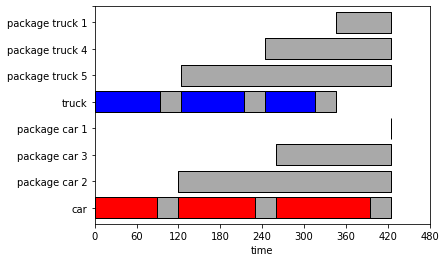

In [18]:
vrv.createGantt(myAssignments)

In [19]:
# If you have saved your Cesium path as an environment variable, you may use `os.environ` to access it:
import os
CESIUM_DIR = os.environ['CESIUMDIR']
# Otherwise, you may specify the patch to Cesium here:
# CESIUM_DIR = '/provide/path/to/Cesium/' 

In [20]:
# Generate a 3D movie of the routes:
vrv.createCesium(assignments = myAssignments, 
                 nodes       = myNodes, 
                 cesiumDir   = CESIUM_DIR, 
                 problemDir  = 'vrv_demo/addAssignment2D_example')

Message: File selector was written to /Users/murray/cesium/vrv_demo/addAssignment2D_example/;vrv_demo;addAssignment2D_example.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/addAssignment2D_example/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/addAssignment2D_example/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/addAssignment2D_example/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/addAssignment2D_example/routes.czml ...


### `addAssignment3D()`
This function appends to an existing `Assignments` dataframe, or creates a new `Assignments` dataframe if `initAssignments` is `None`.  The new rows in this dataframe describe all of the vehicle movements between given starting and ending locations, including timestamps indicating the departure and arrival times for each intermediate point. 
 
- See https://veroviz.org/docs/veroviz.createAssignments.html#veroviz.createAssignments.addAssignment3D for full documentation of this function.

In [21]:
# Import veroviz and check the latest version.
import veroviz as vrv

vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [22]:
# Define 5 node locations, as [lat, lon] pairs:
locs = [[42.8871085, -78.8731949],
        [42.8888311, -78.8649649],
        [42.8802158, -78.8660787],
        [42.8845705, -78.8762794],
        [42.8908031, -78.8770140]]

In [23]:
# Generate a nodes dataframe from these locations:
myNodes = vrv.createNodesFromLocs(locs=locs)
myNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.887108,-78.873195,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.888831,-78.864965,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.880216,-78.866079,0,None,None,3,glyphicon,info-sign,blue,3,pin,blue,3,None
3,4,42.884571,-78.876279,0,None,None,4,glyphicon,info-sign,blue,4,pin,blue,4,None
4,5,42.890803,-78.877014,0,None,None,5,glyphicon,info-sign,blue,5,pin,blue,5,None


In [24]:
# View these nodes on a map:
vrv.createLeaflet(nodes=myNodes)

Example 1 -- Assume a single drone delivers packages from node 1 to all other nodes.

In [25]:
mySolution = {
    'drone': [[1,2,1], [1,3,1], [1,4,1], [1,5,1]]
}

In [26]:
# Define some information about our drone, for later use:
vehicleProperties = {
    'drone': {'modelPackage': 'veroviz/models/drone_package.glb',
              'modelEmpty': 'veroviz/models/drone.glb',
              'color': 'red'},
}

In [27]:
# Build the assignments for the drone deliveries:
myAssignments = vrv.initDataframe('assignments')

endTimeSec = 0.0
for arc in mySolution['drone']:
    # Fly from i to j with a package:
    [myAssignments, endTimeSec] = vrv.addAssignment3D(
        initAssignments    = myAssignments,
        objectID           = 'drone',
        modelFile          = vehicleProperties['drone']['modelPackage'],
        startLoc           = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
        endLoc             = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
        startTimeSec       = endTimeSec,
        takeoffSpeedMPS    = vrv.convertSpeed(30, 'miles', 'hr', 'meters', 'sec'),
        cruiseSpeedMPS     = vrv.convertSpeed(80, 'miles', 'hr', 'meters', 'sec'),
        landSpeedMPS       = vrv.convertSpeed( 5, 'miles', 'hr', 'meters', 'sec'),
        cruiseAltMetersAGL = vrv.convertDistance(350, 'feet', 'meters'),
        routeType          = 'square',
        # climbRateMPS       = None,
        # descentRateMPS     = None,
        # earliestLandTime   = -1,
        # loiterPosition     = 'arrivalAtAlt',
        leafletColor       = vehicleProperties['drone']['color'],
        cesiumColor        = vehicleProperties['drone']['color'])

    # Drop off a package
    myAssignments = vrv.addStaticAssignment(
            initAssignments  = myAssignments,
            objectID         = 'package %d' % (arc[1]),
            modelFile        = '/veroviz/models/box_yellow.gltf',
            loc              = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            endTimeSec       = -1)  
        
    # Fly from j to k empty:
    [myAssignments, endTimeSec] = vrv.addAssignment3D(
        initAssignments    = myAssignments,
        objectID           = 'drone',
        modelFile          = vehicleProperties['drone']['modelEmpty'],
        startLoc           = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
        endLoc             = list(myNodes[myNodes['id'] == arc[2]][['lat', 'lon']].values[0]),
        startTimeSec       = endTimeSec,
        takeoffSpeedMPS    = vrv.convertSpeed(30, 'miles', 'hr', 'meters', 'sec'),
        cruiseSpeedMPS     = vrv.convertSpeed(80, 'miles', 'hr', 'meters', 'sec'),
        landSpeedMPS       = vrv.convertSpeed( 5, 'miles', 'hr', 'meters', 'sec'),
        cruiseAltMetersAGL = vrv.convertDistance(350, 'feet', 'meters'),
        routeType          = 'square',
        # climbRateMPS       = None,
        # descentRateMPS     = None,
        # earliestLandTime   = -1,
        # loiterPosition     = 'arrivalAtAlt',
        leafletColor       = vehicleProperties['drone']['color'],
        cesiumColor        = vehicleProperties['drone']['color'])

myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,drone,/veroviz/models/drone_package.gltf,100,75,0.000000,42.887108,-78.873195,0,7.95457,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,drone,/veroviz/models/drone_package.gltf,100,75,7.954565,42.887108,-78.873195,106.68,27.5,...,darkgray,None,None,None,None,None,None,None,None,None
2,1,drone,/veroviz/models/drone_package.gltf,100,75,27.499981,42.888831,-78.864965,106.68,75.2274,...,darkgray,None,None,None,None,None,None,None,None,None
3,2,package 2,/veroviz/models/box_yellow.gltf,100,75,75.227372,42.888831,-78.864965,0,-1,...,darkgray,None,None,None,None,None,None,None,None,None
4,3,drone,/veroviz/models/drone.gltf,100,75,75.227372,42.888831,-78.864965,0,83.1819,...,darkgray,None,None,None,None,None,None,None,None,None
5,3,drone,/veroviz/models/drone.gltf,100,75,83.181938,42.888831,-78.864965,106.68,102.727,...,darkgray,None,None,None,None,None,None,None,None,None
6,3,drone,/veroviz/models/drone.gltf,100,75,102.727353,42.887108,-78.873195,106.68,150.455,...,darkgray,None,None,None,None,None,None,None,None,None
7,4,drone,/veroviz/models/drone_package.gltf,100,75,150.454745,42.887108,-78.873195,0,158.409,...,darkgray,None,None,None,None,None,None,None,None,None
8,4,drone,/veroviz/models/drone_package.gltf,100,75,158.409310,42.887108,-78.873195,106.68,185.292,...,darkgray,None,None,None,None,None,None,None,None,None
9,4,drone,/veroviz/models/drone_package.gltf,100,75,185.291772,42.880216,-78.866079,106.68,233.019,...,darkgray,None,None,None,None,None,None,None,None,None


In [28]:
# Show the nodes and assignments on a map:
vrv.createLeaflet(nodes=myNodes, arcs=myAssignments, arcCurveType='bezier', arcCurvature=25)

In [29]:
# If you have saved your Cesium path as an environment variable, you may use `os.environ` to access it:
import os
CESIUM_DIR = os.environ['CESIUMDIR']
# Otherwise, you may specify the patch to Cesium here:
# CESIUM_DIR = '/provide/path/to/Cesium/' 

In [30]:
# Create a 3D movie of the drone deliveries:
vrv.createCesium(assignments = myAssignments, 
                 nodes       = myNodes, 
                 cesiumDir   = CESIUM_DIR, 
                 problemDir  = 'vrv_demo/addAssignment3D_example1')

Message: File selector was written to /Users/murray/cesium/vrv_demo/addAssignment3D_example1/;vrv_demo;addAssignment3D_example1.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/addAssignment3D_example1/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/addAssignment3D_example1/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/addAssignment3D_example1/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/addAssignment3D_example1/routes.czml ...


Example 2 -- Coordinate deliveries with a drone launched from a truck

In [31]:
# Hard-code a solution.
# The truck will visit nodes 1->3->5->1
# The drone will launch from the truck at node 1, deliver to node 2, and return to the truck at node 3.
# The drone will then launch from the truck at 1, deliver to 4 and return to 5.
# The drone cannot land at nodes 3 and 5 until the truck has arrived.
mySolution = {
    'drone': [[1,2,3], [3,4,5]],
    'truck': [[1,3], [3,5], [5,1]]
}

In [32]:
# Define some information about our 2 vehicles, for use below:
vehicleProperties = {
    'drone': {'modelPackage': 'veroviz/models/drone_package.glb',
              'modelEmpty': 'veroviz/models/drone.glb',
              'color': 'red'},
    'truck': {'model': 'veroviz/models/ub_truck.glb',
              'color': 'blue'}
}

In [33]:
# This example assumes the use of ORS as the data provider. 
# If you have saved your API key as an environment variable, you may use `os.environ` to access it:
import os
ORS_API_KEY = os.environ['ORSKEY']
# Otherwise, you may specify your key here:
# ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'

In [34]:
# Obtain the travel times for the truck:
[timeSecTruck, distMetersTruck] = vrv.getTimeDist2D(
    nodes            = myNodes,
    routeType        = 'fastest',
    dataProvider     = 'ORS-online',
    dataProviderArgs = {'APIkey': ORS_API_KEY})

In [35]:
# Obtain the travel times for the drone:
[timeSecDrone, groundDist, TotalDist] = vrv.getTimeDist3D(
    nodes            = myNodes,
    takeoffSpeedMPS    = vrv.convertSpeed(30, 'miles', 'hr', 'meters', 'sec'),
    cruiseSpeedMPS     = vrv.convertSpeed(80, 'miles', 'hr', 'meters', 'sec'),
    landSpeedMPS       = vrv.convertSpeed( 5, 'miles', 'hr', 'meters', 'sec'),
    cruiseAltMetersAGL = vrv.convertDistance(350, 'feet', 'meters'),
    routeType          = 'square')

In [36]:
# Find the coordination times for the truck and drone.
# These will be the earliest times that both the truck and drone can arrive at a node.
maxArrivalTime = {}

# 1) The truck travels from 1 to 3; the drone travels from 1 to 2 to 3:
truckArrivalTime = timeSecTruck[1,3]
droneArrivalTime = timeSecDrone[1,2] + timeSecDrone[2,3]
maxArrivalTime[3] = max(truckArrivalTime, droneArrivalTime)

# 2) The truck travels from 3 to 5; the drone travels from 3 to 4 to 5:
truckArrivalTime = maxArrivalTime[3] + timeSecTruck[3,5]
droneArrivalTime = maxArrivalTime[3] + timeSecDrone[3,4] + timeSecDrone[4,5]
maxArrivalTime[5] = max(truckArrivalTime, droneArrivalTime)

# 3) Let's also capture the time at which the truck will return to node 1:
maxArrivalTime[1] = maxArrivalTime[5] + timeSecTruck[5,1]

# maxArrival Time[1] is now the total time required to complete all of the deliveries
maxArrivalTime

{3: 157.79159312243848, 5: 364.9115931224385, 1: 458.4515931224385}

In [37]:
# Build assignments for the drone deliveries:
myAssignments = vrv.initDataframe('assignments')

endTimeSec = 0.0
for arc in mySolution['drone']:
    # Fly from i to j with a package:
    [myAssignments, endTimeSec] = vrv.addAssignment3D(
        initAssignments    = myAssignments,
        objectID           = 'drone',
        modelFile          = vehicleProperties['drone']['modelPackage'],
        startLoc           = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
        endLoc             = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
        startTimeSec       = endTimeSec,
        takeoffSpeedMPS    = vrv.convertSpeed(30, 'miles', 'hr', 'meters', 'sec'),
        cruiseSpeedMPS     = vrv.convertSpeed(80, 'miles', 'hr', 'meters', 'sec'),
        landSpeedMPS       = vrv.convertSpeed( 5, 'miles', 'hr', 'meters', 'sec'),
        cruiseAltMetersAGL = vrv.convertDistance(350, 'feet', 'meters'),
        routeType          = 'square',
        leafletColor       = vehicleProperties['drone']['color'],
        cesiumColor        = vehicleProperties['drone']['color'])

    # Drop off a package
    myAssignments = vrv.addStaticAssignment(
            initAssignments  = myAssignments,
            objectID         = 'package %d' % (arc[1]),
            modelFile        = '/veroviz/models/box_yellow.gltf',
            loc              = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            endTimeSec       = -1)  
    
    # Fly from j to k empty:
    [myAssignments, endTimeSec] = vrv.addAssignment3D(
        initAssignments    = myAssignments,
        objectID           = 'drone',
        modelFile          = vehicleProperties['drone']['modelEmpty'],
        startLoc           = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
        endLoc             = list(myNodes[myNodes['id'] == arc[2]][['lat', 'lon']].values[0]),
        startTimeSec       = endTimeSec,
        takeoffSpeedMPS    = vrv.convertSpeed(30, 'miles', 'hr', 'meters', 'sec'),
        cruiseSpeedMPS     = vrv.convertSpeed(80, 'miles', 'hr', 'meters', 'sec'),
        landSpeedMPS       = vrv.convertSpeed( 5, 'miles', 'hr', 'meters', 'sec'),
        cruiseAltMetersAGL = vrv.convertDistance(350, 'feet', 'meters'),
        routeType          = 'square',
        earliestLandTime   = maxArrivalTime[arc[2]],
        loiterPosition     = 'arrivalAtAlt',
        leafletColor       = vehicleProperties['drone']['color'],
        cesiumColor        = vehicleProperties['drone']['color'])

myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,drone,/veroviz/models/drone_package.gltf,100,75,0.000000,42.887108,-78.873195,0,7.95457,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,drone,/veroviz/models/drone_package.gltf,100,75,7.954565,42.887108,-78.873195,106.68,27.5,...,darkgray,None,None,None,None,None,None,None,None,None
2,1,drone,/veroviz/models/drone_package.gltf,100,75,27.499981,42.888831,-78.864965,106.68,75.2274,...,darkgray,None,None,None,None,None,None,None,None,None
3,2,package 2,/veroviz/models/box_yellow.gltf,100,75,75.227372,42.888831,-78.864965,0,-1,...,darkgray,None,None,None,None,None,None,None,None,None
4,3,drone,/veroviz/models/drone.gltf,100,75,75.227372,42.888831,-78.864965,0,83.1819,...,darkgray,None,None,None,None,None,None,None,None,None
5,3,drone,/veroviz/models/drone.gltf,100,75,83.181938,42.888831,-78.864965,106.68,110.064,...,darkgray,None,None,None,None,None,None,None,None,None
6,3,drone,/veroviz/models/drone.gltf,100,75,110.064202,42.880216,-78.866079,106.68,110.064,...,lightgray,None,None,None,None,None,None,None,None,None
7,3,drone,/veroviz/models/drone.gltf,100,75,110.064202,42.880216,-78.866079,106.68,157.792,...,darkgray,None,None,None,None,None,None,None,None,None
8,4,drone,/veroviz/models/drone_package.gltf,100,75,157.791593,42.880216,-78.866079,0,165.746,...,darkgray,None,None,None,None,None,None,None,None,None
9,4,drone,/veroviz/models/drone_package.gltf,100,75,165.746158,42.880216,-78.866079,106.68,192.69,...,darkgray,None,None,None,None,None,None,None,None,None


In [38]:
# Build assignments for the truck route:
endTimeSec = 0.0
for arc in mySolution['truck']:
    [myAssignments, endTimeSec] = vrv.addAssignment2D(
            initAssignments  = myAssignments,
            objectID         = 'truck',
            modelFile        = vehicleProperties['truck']['model'],
            startLoc         = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
            endLoc           = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            leafletColor     = vehicleProperties['truck']['color'],
            cesiumColor      = vehicleProperties['truck']['color'], 
            routeType        = 'fastest',
            dataProvider     = 'ORS-online', 
            dataProviderArgs = {'APIkey': ORS_API_KEY})
    
    # If necessary, wait for the drone to arrive:
    if (endTimeSec < maxArrivalTime[arc[1]]):
        myAssignments = vrv.addStaticAssignment(
            initAssignments  = myAssignments,
            objectID         = 'truck',
            modelFile        = vehicleProperties['truck']['model'],
            loc              = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            endTimeSec       = maxArrivalTime[arc[1]])

        endTimeSec = maxArrivalTime[arc[1]]  

In [39]:
# Show the nodes and assignments on a map:
vrv.createLeaflet(nodes=myNodes, arcs=myAssignments)

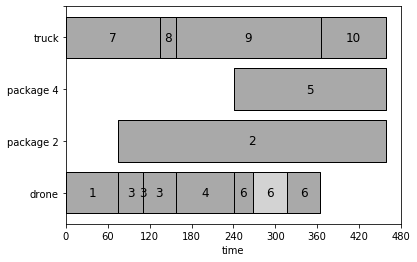

In [40]:
# Create a Gantt chart of the assignments:
vrv.createGantt(assignments=myAssignments, overlayColumn='odID')

In [41]:
# Create a 3D movie of the vehicle routes:
vrv.createCesium(assignments = myAssignments, 
                 nodes       = myNodes, 
                 cesiumDir   = CESIUM_DIR, 
                 problemDir  = 'vrv_demo/addAssignment3D_example2')

Message: File selector was written to /Users/murray/cesium/vrv_demo/addAssignment3D_example2/;vrv_demo;addAssignment3D_example2.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/addAssignment3D_example2/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/addAssignment3D_example2/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/addAssignment3D_example2/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/addAssignment3D_example2/routes.czml ...


### `addStaticAssignment()`
This function adds an "object" to an assignments dataframe.  One use of this function is to add a package or other stationary 3D model to be displayed in Cesium.  This function is also useful for holding a vehicle stationary at a location (e.g., during service or loitering).  

- See https://veroviz.org/docs/veroviz.createAssignments.html#veroviz.createAssignments.addStaticAssignment for full documentation of this function.

In [42]:
# Import veroviz and check the latest version.
>>> import veroviz as vrv
>>> import os

>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

Create two nodes.
- See https://veroviz.org/docs/veroviz.generateNodes.html#veroviz.generateNodes.createNodesFromLocs for more info.

In [43]:
>>> myNodes = vrv.createNodesFromLocs(
...     locs = [[42.1538, -78.4253],
...             [42.6343, -78.1146]])
>>> myNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.1538,-78.4253,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.6343,-78.1146,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None


Move the truck from one node to the other.
- See https://veroviz.org/docs/veroviz.getShapepoints2D.html for more info.    

In [44]:
>>> myAssignments = vrv.getShapepoints2D(
...     odID           = 0,
...     objectID       = 'truck',
...     modelFile      = 'veroviz/models/ub_truck.glb',
...     modelScale     = 80, 
...     modelMinPxSize = 20, 
...     startLoc       = list(myNodes.loc[0][['lat', 'lon']].values),
...     endLoc         = list(myNodes.loc[1][['lat', 'lon']].values),
...     routeType      = 'euclidean2D',
...     dataProvider   = None,
...     speedMPS       = vrv.convertSpeed(55, 'miles', 'hr', 'm', 's'))

>>> myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,0,truck,/veroviz/models/ub_truck.gltf,80,20,0.0,42.1538,-78.4253,0,2407.290832,...,darkgray,None,None,None,None,None,None,None,None,None


Make the truck wait at the destination.

In [45]:
>>> myAssignments = vrv.addStaticAssignment(
...     initAssignments = myAssignments, 
...     odID            = 0, 
...     objectID        = 'truck', 
...     modelFile       = 'veroviz/models/ub_truck.glb', 
...     modelScale      = 80, 
...     modelMinPxSize  = 20, 
...     loc             = list(myAssignments[myAssignments['objectID']=='truck'][['endLat', 'endLon']].values[0]), 
...     startTimeSec    = myAssignments[myAssignments['objectID']=='truck']['endTimeSec'].values[0], 
...     endTimeSec      = myAssignments[myAssignments['objectID']=='truck']['endTimeSec'].values[0] + 30)

>>> myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,0,truck,/veroviz/models/ub_truck.gltf,80,20,0.000000,42.1538,-78.4253,0,2407.290832,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,truck,/veroviz/models/ub_truck.gltf,80,20,2407.290832,42.6343,-78.1146,0,2437.290832,...,darkgray,None,None,None,None,None,None,None,None,None


Drop off a package.

In [46]:
>>> myAssignments = vrv.addStaticAssignment(
...     initAssignments = myAssignments, 
...     odID            = 0, 
...     objectID        = 'package', 
...     modelFile       = 'veroviz/models/box_blue.gltf', 
...     modelScale      = 50, 
...     modelMinPxSize  = 10, 
...     loc             = list(myAssignments[myAssignments['objectID']=='truck'][['endLat', 'endLon']].values[0]), 
...     startTimeSec    = myAssignments[myAssignments['objectID']=='truck']['endTimeSec'].values[0] + 30, 
...     endTimeSec      = -1)

>>> myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,0,truck,/veroviz/models/ub_truck.gltf,80,20,0.000000,42.1538,-78.4253,0,2407.29,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,truck,/veroviz/models/ub_truck.gltf,80,20,2407.290832,42.6343,-78.1146,0,2437.29,...,darkgray,None,None,None,None,None,None,None,None,None
2,2,package,/veroviz/models/box_blue.gltf,50,10,2437.290832,42.6343,-78.1146,0,-1,...,darkgray,None,None,None,None,None,None,None,None,None


View in Leaflet.  
- Note that we can't see the truck waiting. Also, the package doesn't show up in Leaflet.
- See https://veroviz.org/docs/veroviz.createLeaflet.html for more info.

In [47]:
vrv.createLeaflet(nodes=myNodes, arcs=myAssignments)

Create Cesium output, so we can observe our truck and package.
- See https://veroviz.org/docs/veroviz.createCesium.html for more info.

In [48]:
>>> vrv.createCesium(
...     assignments = myAssignments, 
...     nodes       = myNodes, 
...     startTime   = '08:00:00', 
...     cesiumDir   = os.environ['CESIUMDIR'],
...     problemDir  = 'vrv_demo/static_object_demo')

Message: File selector was written to /Users/murray/cesium/vrv_demo/static_object_demo/;vrv_demo;static_object_demo.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/static_object_demo/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/static_object_demo/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/static_object_demo/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/static_object_demo/routes.czml ...


### `createAssignmentsFromArcs2D()`
This function generates an "assignments" dataframe containing all of the "shapepoints" between successive arcs, including timestamps indicating the departure and arrival times for each shapepoint. Shapepoints are pairs of GPS coordinates that are connected by straight lines.  For a particular origin and destination, numerous individual shapepoints can be combined to define a travel route along a road network. 

- This function is for vehicles traveling on a ground plane (2-dimensional).  For vehicles requiring an altitude component (e.g., drones), a 3D version of this function is provided by `createAssignmentsFromArcs3D()`.
	
- This function creates an assignments dataframe from an arcs dataframe.  Similar functions are available to create an assignments dataframe from a sequence of nodes (`createShapepointsFromNodeSeq2D()`) or from a sequence of locations (`createShapepointsFromLocSeq2D()`).

- See https://veroviz.org/docs/veroviz.createAssignments.html#veroviz.createAssignments.createAssignmentsFromArcs2D for full documentation of this function.

In [49]:
# First import veroviz and check if it is the latest version
import veroviz as vrv
vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [50]:
# Generate arcs from a given ordered list of coordinates:
arcs = vrv.createArcsFromLocSeq(
    locSeq=[[42.3561, -78.4279, 30],
            [42.3465, -78.4235, 30],
            [42.3431, -78.4186, 40]])
arcs

,odID,objectID,startLat,startLon,endLat,endLon,leafletColor,leafletWeight,leafletStyle,leafletOpacity,leafletCurveType,leafletCurvature,useArrows,cesiumColor,cesiumWeight,cesiumStyle,cesiumOpacity,popupText,startElevMeters,endElevMeters
0,1,None,42.3561,-78.4279,42.3465,-78.4235,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None
1,2,None,42.3465,-78.4235,42.3431,-78.4186,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None


In [51]:
# Display the arcs on a Leaflet map:
vrv.createLeaflet(arcs=arcs)

In [52]:
# The following examples assume the use of ORS as the data provider. 
# If you have saved your API key as an environment variable, 
# you may use `os.environ` to access it:
import os
ORS_API_KEY = os.environ['ORSKEY']
# Otherwise, you may specify your key here:
# ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'

In [53]:
# Generate an assignments dataframe from the arcs dataframe:
myAssignments = vrv.createAssignmentsFromArcs2D(
    arcs             = arcs, 
    modelFile        = 'veroviz/models/car_blue.gltf', 
    routeType        = 'fastest', 
    dataProvider     = 'ors-online',
    dataProviderArgs = {'APIkey': ORS_API_KEY},
    leafletColor     = 'blue')
myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,None,/veroviz/models/car_blue.gltf,100,75,0.000000,42.356104,-78.427904,0,17.918831,...,darkgray,None,604.5,605.8,Kingsbury Hill Road,No category,Asphalt,Street,0,False
1,1,None,/veroviz/models/car_blue.gltf,100,75,17.918831,42.355231,-78.429280,0,37.936712,...,darkgray,None,605.8,604.8,Kingsbury Hill Road,No category,Asphalt,Street,0,False
2,1,None,/veroviz/models/car_blue.gltf,100,75,37.936712,42.354231,-78.430788,0,102.489367,...,darkgray,None,604.8,566.7,Kingsbury Hill Road,No category,Asphalt,Street,0,False
3,1,None,/veroviz/models/car_blue.gltf,100,75,102.489367,42.351094,-78.435754,0,114.175367,...,darkgray,None,566.7,558.0,Kingsbury Hill Road,No category,Asphalt,Street,-3,False
4,1,None,/veroviz/models/car_blue.gltf,100,75,114.175367,42.350515,-78.436640,0,146.680056,...,darkgray,None,558.0,540.2,Kingsbury Hill Road,No category,Asphalt,Street,-2,False
5,1,None,/veroviz/models/car_blue.gltf,100,75,146.680056,42.348942,-78.439148,0,158.051940,...,darkgray,None,540.2,537.2,Kingsbury Hill Road,No category,Asphalt,Street,-2,False
6,1,None,/veroviz/models/car_blue.gltf,100,75,158.051940,42.348414,-78.440050,0,165.767491,...,darkgray,None,537.2,535.5,Kingsbury Hill Road,No category,Asphalt,Street,-2,False
7,1,None,/veroviz/models/car_blue.gltf,100,75,165.767491,42.348043,-78.440648,0,172.726842,...,darkgray,None,535.5,533.6,Kingsbury Hill Road,No category,Asphalt,Street,-2,False
8,1,None,/veroviz/models/car_blue.gltf,100,75,172.726842,42.347696,-78.441173,0,223.644582,...,darkgray,None,533.6,508.4,Kingsbury Hill Road,No category,Asphalt,Street,-2,False
9,1,None,/veroviz/models/car_blue.gltf,100,75,223.644582,42.345221,-78.445089,0,231.194989,...,darkgray,None,508.4,504.4,Kingsbury Hill Road,No category,Asphalt,Street,-2,False


In [54]:
# Display the assignments on a map:
vrv.createLeaflet(arcs=myAssignments, arrowsPerArc=13)

### `createAssignmentsFromLocSeq2D()`
This function generates an "assignments" dataframe containing all of the "shapepoints" between successive locations, including timestamps indicating the departure and arrival times for each shapepoint. Shapepoints are pairs of GPS coordinates that are connected by straight lines.  For a particular origin and destination, numerous individual shapepoints can be combined to define a travel route along a road network.  

- This function is for vehicles traveling on a ground plane (2-dimensional).  For vehicles requiring an altitude component (e.g., drones), a 3D version of this function is provided by `createAssignmentsFromLocSeq3D()`.
	
- This function creates an assignments dataframe from a sequence of [lat, lon] locations.  Similar functions are available to create an assignments dataframe from an arcs dataframe (`createShapepointsFromArcs2D()`) or from a sequence of nodes (`createShapepointsFromNodeSeq2D()`).

- See https://veroviz.org/docs/veroviz.createAssignments.html#veroviz.createAssignments.createAssignmentsFromLocSeq2D for full documentation of this function.

In [55]:
# Import veroviz and check the latest version.
>>> import veroviz as vrv

>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [56]:
# The following examples assume the use of ORS as the data provider. If you have saved your API key as an environment variable, you may use `os.environ` to access it:
>>> import os
>>> ORS_API_KEY = os.environ['ORSKEY']
>>> # Otherwise, you may specify your key here:
>>> # ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'

In [57]:
# Specify a sequence of [lat, lon] or [lat, lon, alt] locations. 
>>> locs = [
...     [42.1538, -78.4253, 30], 
...     [42.3465, -78.6234, 30], 
...     [42.6343, -78.1146, 40],
...     [42.1538, -78.4253, 30]] 

Example 1 - A simple example using Euclidean travel, and no service times.  The assignments dataframe will have 3 rows.

In [58]:
>>> assignmentsDF = vrv.createAssignmentsFromLocSeq2D(
...     locSeq         = locs, 
...     serviceTimeSec = 0.0, 
...     objectID       = 'Blue Car', 
...     modelFile      = 'veroviz/models/car_blue.gltf', 
...     routeType      = 'euclidean2D',
...     speedMPS       = 10)
>>> assignmentsDF

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,0.000000,42.1538,-78.4253,30,2693.379882,...,darkgray,None,None,None,None,None,None,None,None,None
1,2,Blue Car,/veroviz/models/car_blue.gltf,100,75,2693.379882,42.3465,-78.6234,30,7958.098133,...,darkgray,None,None,None,None,None,None,None,None,None
2,3,Blue Car,/veroviz/models/car_blue.gltf,100,75,7958.098133,42.6343,-78.1146,40,13876.937537,...,darkgray,None,None,None,None,None,None,None,None,None


Example 2 - The vehicle will follow the road network, resulting in an assignments dataframe with significantly more than 3 rows.  The vehicle will remain stationary at the destination locations.  The travel time for each origin/destination pair will be calculated separately.

In [59]:
>>> # Make our car wait for 65 seconds before starting:
>>> assignmentsDF = vrv.addStaticAssignment(
...     odID         = 0, 
...     objectID     = 'Blue Car', 
...     modelFile    = 'veroviz/models/car_blue.gltf', 
...     loc          = locs[0], 
...     startTimeSec = 0.0, 
...     endTimeSec   = 65.0)

In [60]:
>>> # This example includes all of the available input arguments:
>>> newAssignmentsDF = vrv.createAssignmentsFromLocSeq2D(
...     initAssignments  = assignmentsDF, 
...     locSeq           = locs, 
...     serviceTimeSec   = 20.0, 
...     odID             = 1, 
...     objectID         = 'Blue Car', 
...     modelFile        = 'veroviz/models/car_blue.gltf', 
...     modelScale       = 100,
...     modelMinPxSize   = 75,
...     startTimeSec     = 65.0, 
...     expDurationArgs  = {'getTravelTimes': True}, 
...     routeType        = 'fastest',
...     speedMPS         = None,   
...     leafletColor     = 'blue', 
...     leafletWeight    = 3, 
...     leafletStyle     = 'dashed', 
...     leafletOpacity   = 0.8, 
...     useArrows        = True, 
...     cesiumColor      = 'blue', 
...     cesiumWeight     = 3, 
...     cesiumStyle      = 'solid', 
...     cesiumOpacity    = 0.8, 
...     dataProvider     = 'ORS-online',
...     dataProviderArgs = {'APIkey' : ORS_API_KEY})
>>> newAssignmentsDF


Message: The origin point (lat: 42.1538, lon: -78.4253) is 492.9 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.3465, lon: -78.6234) is 254.8 meters away from the road. You might find a gap between destination point and the route.
Message: The origin point (lat: 42.3465, lon: -78.6234) is 254.8 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.6343, lon: -78.1146) is 343.9 meters away from the road. You might find a gap between destination point and the route.
Message: The origin point (lat: 42.6343, lon: -78.1146) is 343.9 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.1538, lon: -78.4253) is 492.9 meters away from the road. You might find a gap between destination point and the route.


,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,0,Blue Car,/veroviz/models/car_blue.gltf,100,75,0.000000,42.153800,-78.425300,30,65.000000,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,65.000000,42.157210,-78.421483,0,79.346516,...,darkgray,None,492,494,Fay Hollow Road,No category,Asphalt,Street,1,False
2,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,79.346516,42.158075,-78.422889,0,81.888900,...,darkgray,None,494,494.2,Fay Hollow Road,No category,Asphalt,Street,1,False
3,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,81.888900,42.158237,-78.423128,0,90.136052,...,darkgray,None,494.2,495,Fay Hollow Road,No category,Asphalt,Street,1,False
4,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,90.136052,42.158812,-78.423837,0,98.799661,...,darkgray,None,495,495.9,Fay Hollow Road,No category,Asphalt,Street,1,False
5,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,98.799661,42.159465,-78.424503,0,114.386397,...,darkgray,None,495.9,498.4,Fay Hollow Road,No category,Asphalt,Street,1,False
6,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,114.386397,42.160656,-78.425672,0,119.183987,...,darkgray,None,498.4,498.5,Fay Hollow Road,No category,Asphalt,Street,1,False
7,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,119.183987,42.161050,-78.425975,0,136.575472,...,darkgray,None,498.5,499.9,Fay Hollow Road,No category,Asphalt,Street,1,False
8,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,136.575472,42.162560,-78.426854,0,147.217045,...,darkgray,None,499.9,500.5,Fay Hollow Road,No category,Asphalt,Street,1,False
9,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,147.217045,42.163508,-78.427310,0,156.917866,...,darkgray,None,500.5,501.6,Fay Hollow Road,No category,Asphalt,Street,1,False


In [61]:
# Generate a `Nodes` dataframe from our first three locations 
# (the fourth location is a duplicate of the first).  
exampleNodes = vrv.createNodesFromLocs(locs=locs[0:3])

In [62]:
# View the assignments in Leaflet:  
>>> vrv.createLeaflet(arcs=newAssignmentsDF, nodes=exampleNodes)

In [63]:
# View the assignments in Cesium:
>>> vrv.createCesium(
...     assignments = newAssignmentsDF, 
...     nodes       = exampleNodes, 
...     startTime   = '08:00:00', 
...     cesiumDir   = os.environ['CESIUMDIR'],
...     problemDir  = 'vrv_demo/createAssignmentsLocSeq_example')

Message: File selector was written to /Users/murray/cesium/vrv_demo/createAssignmentsLocSeq_example/;vrv_demo;createAssignmentsLocSeq_example.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/createAssignmentsLocSeq_example/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/createAssignmentsLocSeq_example/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/createAssignmentsLocSeq_example/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/createAssignmentsLocSeq_example/routes.czml ...


### `createAssignmentsFromNodeSeq2D()`
This function generates an "assignments" dataframe containing all of the "shapepoints" between successive node locations, including timestamps indicating the departure and arrival times for each shapepoint. Shapepoints are pairs of GPS coordinates that are connected by straight lines.  For a particular origin and destination, numerous individual shapepoints can be combined to define a travel route along a road network. 

- This function is for vehicles traveling on a ground plane (2-dimensional).  For vehicles requiring an altitude component (e.g., drones), a 3D version of this function is provided by `createAssignmentsFromLocSeq3D()`.
	
- This function creates an assignments dataframe from a sequence of nodes.  Similar functions are available to create an assignments dataframe from an arcs dataframe (`createShapepointsFromArcs2D()`) or from a sequence of locations (`createShapepointsFromLocSeq2D()`).

- See https://veroviz.org/docs/veroviz.createAssignments.html#veroviz.createAssignments.createAssignmentsFromNodeSeq2D for full documentation of this function.

In [64]:
# Import veroviz and check the latest version.
>>> import veroviz as vrv

>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [65]:
# The following examples assume the use of ORS as the data provider. If you have saved your API key as an environment variable, you may use `os.environ` to access it:
>>> import os
>>> ORS_API_KEY = os.environ['ORSKEY']
>>> # Otherwise, you may specify your key here:
>>> # ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'

In [66]:
# Generate a `Nodes` dataframe from a list of coordinates.  
>>> locs = [
...     [42.1538, -78.4253], 
...     [42.3465, -78.6234], 
...     [42.6343, -78.1146]]
>>> exampleNodes = vrv.createNodesFromLocs(locs=locs)

Example 1 - A simple example using Euclidean travel, and no service times.  The assignments dataframe will have 3 rows.

In [67]:
>>> assignmentsDF = vrv.createAssignmentsFromNodeSeq2D(
...     nodeSeq        = [1, 3, 2, 1], 
...     nodes          = exampleNodes, 
...     serviceTimeSec = 0.0, 
...     objectID       = 'Blue Car', 
...     modelFile      = 'veroviz/models/car_blue.gltf', 
...     routeType      = 'euclidean2D',
...     speedMPS       = 10)
>>> assignmentsDF

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,0.000000,42.1538,-78.4253,0,5918.839403,...,darkgray,None,None,None,None,None,None,None,None,None
1,2,Blue Car,/veroviz/models/car_blue.gltf,100,75,5918.839403,42.6343,-78.1146,0,11183.557655,...,darkgray,None,None,None,None,None,None,None,None,None
2,3,Blue Car,/veroviz/models/car_blue.gltf,100,75,11183.557655,42.3465,-78.6234,0,13876.937537,...,darkgray,None,None,None,None,None,None,None,None,None


Example 2 - The vehicle will follow the road network, resulting in an assignments dataframe with significantly more than 3 rows.  The vehicle will remain stationary at nodes 3, 2, and 1 (the destination nodes).  The travel time for each origin/destination pair will be calculated separately.

In [68]:
>>> assignmentsDF = vrv.createAssignmentsFromNodeSeq2D(
...     initAssignments  = None, 
...     nodeSeq          = [1, 3, 2, 1], 
...     nodes            = exampleNodes, 
...     serviceTimeSec   = 20.0, 
...     odID             = 1, 
...     objectID         = 'Blue Car', 
...     modelFile        = 'veroviz/models/car_blue.gltf', 
...     expDurationArgs  = {'getTravelTimes': True}, 
...     routeType        = 'fastest',
...     dataProvider     = 'ORS-online',
...     dataProviderArgs = {'APIkey' : ORS_API_KEY})
>>> assignmentsDF


Message: The origin point (lat: 42.1538, lon: -78.4253) is 492.9 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.6343, lon: -78.1146) is 343.9 meters away from the road. You might find a gap between destination point and the route.
Message: The origin point (lat: 42.6343, lon: -78.1146) is 343.9 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.3465, lon: -78.6234) is 254.8 meters away from the road. You might find a gap between destination point and the route.
Message: The origin point (lat: 42.3465, lon: -78.6234) is 254.8 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.1538, lon: -78.4253) is 492.9 meters away from the road. You might find a gap between destination point and the route.


,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,0.000000,42.157210,-78.421483,0,2.490166,...,darkgray,None,492,490,Fay Hollow Road,No category,Asphalt,Street,-1,False
1,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,2.490166,42.156979,-78.421107,0,9.603449,...,darkgray,None,490,487.1,Fay Hollow Road,No category,Asphalt,Street,-1,False
2,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,9.603449,42.156253,-78.420113,0,11.155179,...,darkgray,None,487.1,486.4,Fay Hollow Road,No category,Asphalt,Street,-1,False
3,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,11.155179,42.156079,-78.419919,0,13.320820,...,darkgray,None,486.4,485,Fay Hollow Road,No category,Asphalt,Street,-1,False
4,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,13.320820,42.155856,-78.419619,0,15.247837,...,darkgray,None,485,483.7,Fay Hollow Road,No category,Asphalt,Street,-1,False
5,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,15.247837,42.155672,-78.419334,0,18.575035,...,darkgray,None,483.7,481.8,Fay Hollow Road,No category,Asphalt,Street,-1,False
6,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,18.575035,42.155378,-78.418816,0,24.055295,...,darkgray,None,481.8,478,Fay Hollow Road,No category,Asphalt,Street,-1,False
7,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,24.055295,42.154778,-78.418108,0,41.852013,...,darkgray,None,478,468.1,Fay Hollow Road,No category,Asphalt,Street,-1,False
8,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,41.852013,42.152856,-78.415769,0,50.916847,...,darkgray,None,468.1,465.6,Fay Hollow Road,No category,Asphalt,Street,-1,False
9,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,50.916847,42.151901,-78.414543,0,54.978233,...,darkgray,None,465.6,467.4,Fay Hollow Road,No category,Asphalt,Street,-1,False


Example 3 - The vehicle will first wait at the starting location (node 1) for 65 seconds.  It will then visit nodes 3 and 2 before returning to node 1.  At each of those nodes, the vehicle will remain stationary for a 20-second service time.  The travel time between each pair of nodes will be determined by the times in the `timeSec` matrix.

In [69]:
# Generate a matrix of travel times:
>>> [timeSec, distMeters] = vrv.getTimeDist2D(
...     nodes            = exampleNodes,
...     matrixType       = 'all2all',
...     outputDistUnits  = 'meters',
...     outputTimeUnits  = 'seconds',
...     routeType        = 'fastest',
...     speedMPS         = None,   
...     dataProvider     = 'ORS-online',
...     dataProviderArgs = {'APIkey' : ORS_API_KEY})

In [70]:
# Make our car wait for 65 seconds before starting:
>>> assignmentsDF = vrv.addStaticAssignment(
...     odID         = 0, 
...     objectID     = 'Blue Car', 
...     modelFile    = 'veroviz/models/car_blue.gltf', 
...     loc          = [exampleNodes.loc[exampleNodes['id'] == 1]['lat'].values[0],
...                     exampleNodes.loc[exampleNodes['id'] == 1]['lon'].values[0]], 
...     startTimeSec = 0.0, 
...     endTimeSec   = 65.0)

In [71]:
# This example includes all of the available input arguments:
>>> newAssignmentsDF = vrv.createAssignmentsFromNodeSeq2D(
...     initAssignments  = assignmentsDF, 
...     nodeSeq          = [1, 3, 2, 1], 
...     nodes            = exampleNodes, 
...     serviceTimeSec   = 20.0, 
...     odID             = 1, 
...     objectID         = 'Blue Car', 
...     modelFile        = 'veroviz/models/car_blue.gltf', 
...     modelScale       = 100,
...     modelMinPxSize   = 75,
...     startTimeSec     = 65.0, 
...     expDurationArgs  = {'timeSecDict': timeSec}, 
...     routeType        = 'fastest',
...     speedMPS         = None,   
...     leafletColor     = 'blue', 
...     leafletWeight    = 3, 
...     leafletStyle     = 'dashed', 
...     leafletOpacity   = 0.8, 
...     useArrows        = True, 
...     cesiumColor      = 'blue', 
...     cesiumWeight     = 3, 
...     cesiumStyle      = 'solid', 
...     cesiumOpacity    = 0.8, 
...     dataProvider     = 'ORS-online',
...     dataProviderArgs = {'APIkey' : ORS_API_KEY})
>>> newAssignmentsDF


Message: The origin point (lat: 42.1538, lon: -78.4253) is 492.9 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.6343, lon: -78.1146) is 343.9 meters away from the road. You might find a gap between destination point and the route.
Message: The origin point (lat: 42.6343, lon: -78.1146) is 343.9 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.3465, lon: -78.6234) is 254.8 meters away from the road. You might find a gap between destination point and the route.
Message: The origin point (lat: 42.3465, lon: -78.6234) is 254.8 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.1538, lon: -78.4253) is 492.9 meters away from the road. You might find a gap between destination point and the route.


,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,0,Blue Car,/veroviz/models/car_blue.gltf,100,75,0.000000,42.153800,-78.425300,0,65.000000,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,65.000000,42.157210,-78.421483,0,67.490166,...,darkgray,None,492,490,Fay Hollow Road,No category,Asphalt,Street,-1,False
2,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,67.490166,42.156979,-78.421107,0,74.603449,...,darkgray,None,490,487.1,Fay Hollow Road,No category,Asphalt,Street,-1,False
3,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,74.603449,42.156253,-78.420113,0,76.155179,...,darkgray,None,487.1,486.4,Fay Hollow Road,No category,Asphalt,Street,-1,False
4,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,76.155179,42.156079,-78.419919,0,78.320820,...,darkgray,None,486.4,485,Fay Hollow Road,No category,Asphalt,Street,-1,False
5,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,78.320820,42.155856,-78.419619,0,80.247837,...,darkgray,None,485,483.7,Fay Hollow Road,No category,Asphalt,Street,-1,False
6,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,80.247837,42.155672,-78.419334,0,83.575035,...,darkgray,None,483.7,481.8,Fay Hollow Road,No category,Asphalt,Street,-1,False
7,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,83.575035,42.155378,-78.418816,0,89.055295,...,darkgray,None,481.8,478,Fay Hollow Road,No category,Asphalt,Street,-1,False
8,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,89.055295,42.154778,-78.418108,0,106.852013,...,darkgray,None,478,468.1,Fay Hollow Road,No category,Asphalt,Street,-1,False
9,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,106.852013,42.152856,-78.415769,0,115.916847,...,darkgray,None,468.1,465.6,Fay Hollow Road,No category,Asphalt,Street,-1,False


In [72]:
# View the assignments in Leaflet:  
>>> vrv.createLeaflet(arcs=newAssignmentsDF, nodes=exampleNodes)

In [73]:
# View the assignments in Cesium:
>>> vrv.createCesium(
...     assignments = newAssignmentsDF, 
...     nodes       = exampleNodes, 
...     startTime   = '08:00:00', 
...     cesiumDir   = os.environ['CESIUMDIR'],
...     problemDir  = 'vrv_demo/createAssignmentsNodeSeq_example')

Message: File selector was written to /Users/murray/cesium/vrv_demo/createAssignmentsNodeSeq_example/;vrv_demo;createAssignmentsNodeSeq_example.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/createAssignmentsNodeSeq_example/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/createAssignmentsNodeSeq_example/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/createAssignmentsNodeSeq_example/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/createAssignmentsNodeSeq_example/routes.czml ...


--- 

## createCesium Module

This module includes the following function:
- `createCesium()`

### `createCesium()`

This function generates several files required to view a solution in Cesium. The function requires assignments and/or nodes dataframes as input.

- See https://veroviz.org/docs/veroviz.createCesium.html#module-veroviz.createCesium for complete function documentation.
- See https://veroviz.org/downloads/cesium_demo.ipynb.zip for a downloadable example.

In [74]:
# Import veroviz and check the latest version.
>>> import veroviz as vrv
>>> import os

>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [75]:
# Create two nodes.
>>> myNodes = vrv.createNodesFromLocs(
...     locs = [[42.1538, -78.4253],
...             [42.6343, -78.1146]])
>>> myNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.1538,-78.4253,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.6343,-78.1146,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None


In [76]:
# Move the truck from one node to the other.
>>> myAssignments = vrv.getShapepoints2D(
...     odID           = 0,
...     objectID       = 'truck',
...     modelFile      = 'veroviz/models/ub_truck.glb',
...     modelScale     = 80, 
...     modelMinPxSize = 20, 
...     startLoc       = list(myNodes.loc[0][['lat', 'lon']].values),
...     endLoc         = list(myNodes.loc[1][['lat', 'lon']].values),
...     routeType      = 'euclidean2D',
...     dataProvider   = None,
...     speedMPS       = vrv.convertSpeed(55, 'miles', 'hr', 'm', 's'))

In [77]:
# Create Cesium output.
>>> vrv.createCesium(
...     assignments = myAssignments, 
...     nodes       = myNodes, 
...     startTime   = '08:00:00', 
...     cesiumDir   = os.environ['CESIUMDIR'],
...     problemDir  = 'vrv_demo/createCesium_example')

Message: File selector was written to /Users/murray/cesium/vrv_demo/createCesium_example/;vrv_demo;createCesium_example.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/createCesium_example/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/createCesium_example/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/createCesium_example/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/createCesium_example/routes.czml ...


--- 

## createLeaflet Module

This module includes the following functions:
- `addLeafletCircle()`
- `addLeafletIcon()` (new in v0.4.0)
- `addLeafletIsochrones()` (new in v0.4.0)
- `addLeafletMarker()`
- `addLeafletPolygon()`
- `addLeafletPolyline()`
- `addLeafletText()`
- `addLeafletWeather()` (new in v0.4.0)
- `createLeaflet()`



### `addLeafletCircle()`
Add a circle, with a radius specified in [meters], to a Leaflet map.

- See https://veroviz.org/docs/veroviz.createLeaflet.html#veroviz.createLeaflet.addLeafletCircle for complete function documentation.

In [78]:
>>> # Draw a circle of radius 10 meters, centered on the Univ. at Buffalo campus.
>>> # Save this as "a_circle.html".
>>> import veroviz as vrv
>>> myMap = vrv.addLeafletCircle(
...     zoomStart=18,
...     center=[43.00154, -78.7871],
...     radius=100,
...     mapFilename="a_circle.html")
>>> myMap

Message: Map page written to a_circle.html.


In [79]:
>>> # Draw a circle of radius 2000 meters, centered on the Univ. at Buffalo campus.
>>> # This example includes all of the available function arguments.
>>> import veroviz as vrv
>>> myMap = vrv.addLeafletCircle(
...     mapObject     = None,
...     mapFilename   = None,
...     mapBackground = 'OpenStreetMap',
...     mapBoundary   = None,
...     zoomStart     = 13,
...     center        = [43.00154, -78.7871],
...     radius        = 2000,
...     text          = 'UB',
...     fontSize      = 24,
...     fontColor     = 'white',
...     popupText     = 'click circle to see this text',
...     lineWeight    = 6,
...     lineColor     = '#ff66ff',
...     lineOpacity   = 0.7,
...     lineStyle     = 'dotted',
...     fillColor     = 'green',
...     fillOpacity   = 0.4)
>>> myMap

### `addLeafletIcon()`
Add a single icon/pin to a Leaflet map.

In [80]:
# Define a location:
whiteHouse = [38.8977, -77.0365]

In [81]:
# A minimal example, using mostly default parameters:
vrv.addLeafletIcon(location      = whiteHouse)

In [82]:
# Example showing all function parameters:
vrv.addLeafletIcon(mapObject     = None, 
                   mapFilename   = None, 
                   mapBackground = 'arcgis aerial', 
                   mapBoundary   = None, 
                   zoomStart     = None, 
                   location      = whiteHouse, 
                   iconPrefix    = 'custom', 
                   iconType      = '18-yellow-12', 
                   iconColor     = 'purple', 
                   iconText      = 'WH', 
                   popupText     = '<nobr>click icon to see this single-line text</nobr>')

###  `addLeafletIsochrones()`
Easily draw isochrones on a Leaflet map.  Be sure to run the `isochrones()` function first.

In [83]:
# Get isochrone data:
iso = vrv.isochrones(location         = [43.00154, -78.7871], 
                     locationType     = 'start', 
                     travelMode       = 'driving-car', 
                     rangeType        = 'time', 
                     rangeSize        = vrv.convertTime(5, 'minutes', 'seconds'), 
                     interval         = vrv.convertTime(2.5, 'minutes', 'seconds'), 
                     smoothing        = 5, 
                     dataProvider     ='ors-online', 
                     dataProviderArgs = {'APIkey': ORS_API_KEY})

In [84]:
# A minimal working example, using mostly default values:
vrv.addLeafletIsochrones(iso = iso)

In [85]:
# An example using all of the functional parameters:
vrv.addLeafletIsochrones(mapObject          = None, 
                         mapFilename        = None, 
                         mapBackground      = 'cartodb dark_matter', 
                         mapBoundary        = None, 
                         zoomStart          = None, 
                         iso                = iso, 
                         showBoundingRegion = True, 
                         iconPrefix         = 'custom', 
                         iconType           = '12-white-12', 
                         iconColor          = 'red', 
                         iconText           = '1', 
                         popupText          = None, 
                         lineWeight         = 3, 
                         lineOpacity        = 0.8, 
                         lineStyle          = 'solid', 
                         fillOpacity        = 0.3)

### `addLeafletMarker()`
Add a circle-shaped marker, with a radius specified in [pixels], to a Leaflet map.

- See https://veroviz.org/docs/veroviz.createLeaflet.html#veroviz.createLeaflet.addLeafletMarker for complete function documentation.

In [86]:
>>> # Draw a circle of radius 10 pixels, centered on the Univ. at Buffalo campus.
>>> # Save this as "a_marker.html".
>>> import veroviz as vrv
>>> myMap = vrv.addLeafletMarker(
...     center=[43.00154, -78.7871],
...     radius=10,
...     mapFilename="a_marker.html")
>>> myMap

Message: Map page written to a_marker.html.


In [87]:
>>> # Draw a circle of radius 30 pixels, centered on the Univ. at Buffalo campus.
>>> # This example includes all of the available function arguments.
>>> import veroviz as vrv
>>> myMap = vrv.addLeafletMarker(
...     mapObject     = None, 
...     mapFilename   = None, 
...     mapBackground = 'CartoDB positron', 
...     mapBoundary   = None, 
...     zoomStart     = 11, 
...     center        = [43.00154, -78.7871],
...     radius        = 30, 
...     text          = 'UB',
...     fontSize      = 24,
...     fontColor     = 'white',
...     popupText     = 'click marker to see this text',
...     lineWeight    = 3, 
...     lineColor     = 'orange', 
...     lineOpacity   = 0.6, 
...     lineStyle     = 'dashed',
...     fillColor     = 'blue', 
...     fillOpacity   = 0.3)
>>> myMap

### `addLeafletPolygon()`
Add a polygon, as defined by an ordered collection of lat/lon coordinates, to a Leaflet map.

- See https://veroviz.org/docs/veroviz.createLeaflet.html#veroviz.createLeaflet.addLeafletPolygon for complete function documentation.

In [88]:
>>> # Draw a polygon around the Univ. at Buffalo campus.
>>> # Save this as "a_polygon.html".
>>> import veroviz as vrv
>>> campusPoints = [[43.0121, -78.7858],
...                 [43.0024, -78.7977],
...                 [42.9967, -78.7921],
...                 [42.9988, -78.7790]]
>>> myMap = vrv.addLeafletPolygon(
...     points=campusPoints,
...     mapFilename="a_polygon.html")
>>> myMap

Message: Map page written to a_polygon.html.


In [89]:
>>> # Draw a filled polygon around the Univ. at Buffalo campus.
>>> # This example includes all of the available function arguments.
>>> import veroviz as vrv
>>> campusPoints = [[43.0121, -78.7858],
...                 [43.0024, -78.7977],
...                 [42.9967, -78.7921],
...                 [42.9988, -78.7790]]
>>> myMap = vrv.addLeafletPolygon(
...     mapObject     = None, 
...     mapFilename   = None, 
...     mapBackground = 'OpenStreetMap', 
...     mapBoundary   = vrv.getMapBoundary(locs=campusPoints), 
...     zoomStart     = None, 
...     points        = campusPoints, 
...     popupText     = 'click polygon to see this',   
...     lineWeight    = 7, 
...     lineColor     = '#ff00ff', 
...     lineOpacity   = 0.9, 
...     lineStyle     = 'solid', 
...     fillColor     = '#ff66ff', 
...     fillOpacity   = 0.3)    
>>> myMap

### `addLeafletPolyline()`
Add a polyline, as described by an ordered collection of lat/lon coordinates, to a Leaflet map.  The polyline is an "open" shape, in the sense that there's nothing connecting the first and last locations.  By contrast, the "polygon" shape will automatically connect the first and last locations.

- See https://veroviz.org/docs/veroviz.createLeaflet.html#veroviz.createLeaflet.addLeafletPolyline for complete function documentation.

In [90]:
>>> # Draw a polyline around the northern portion of the Univ. at Buffalo campus.
>>> # Save this as "a_polyline.html".
>>> import veroviz as vrv
>>> campusPoints = [[43.0024, -78.7977],
...                 [43.0121, -78.7858],
...                 [42.9988, -78.7790]]
>>> myMap = vrv.addLeafletPolyline(
...     points=campusPoints,
...     mapFilename="a_polyline.html")
>>> myMap

Message: Map page written to a_polyline.html.


In [91]:
>>> # Draw a polyline around the northern portion of the Univ. at Buffalo campus.
>>> # This example includes all of the available function arguments.
>>> import veroviz as vrv
>>> campusPoints = [[43.0024, -78.7977],
...                 [43.0121, -78.7858],
...                 [42.9988, -78.7790]]
>>> myMap = vrv.addLeafletPolyline(
...     mapObject = None, 
...     mapFilename = None, 
...     mapBackground = 'CartoDB positron', 
...     mapBoundary = vrv.getMapBoundary(locs=campusPoints),
...     zoomStart = None, 
...     points = campusPoints,
...     popupText = 'Univ. at Buffalo',
...     lineWeight = 3, 
...     lineColor = '#0055ff', 
...     lineOpacity = 0.8, 
...     lineStyle = 'solid', 
...     lineCurveType = 'bezier',
...     lineCurvature = 30,
...     useArrows = True,
...     arrowsPerArc = 1)
>>> myMap

### `addLeafletText()`
Add a text label to a Leaflet map. 

- See https://veroviz.org/docs/veroviz.createLeaflet.html#veroviz.createLeaflet.addLeafletText for complete function documentation.

In [92]:
>>> # Draw a text label at the location of Bell Hall on the
>>> # Univ. at Buffalo campus.
>>> # Save this as "a_text_label.html".
>>> import veroviz as vrv
>>> myMap = vrv.addLeafletText(
...     anchorPoint=[43.00154, -78.7871],
...     text="Bell Hall",
...     mapFilename="a_text_label.html")
>>> myMap

Message: Map page written to a_text_label.html.


In [93]:
>>> # Draw a text label at the location of Bell Hall on the
>>> # Univ. at Buffalo campus.
>>> # This example includes all of the available function arguments.
>>> import veroviz as vrv
>>> myMap = vrv.addLeafletText(
...     mapObject     = None, 
...     mapFilename   = None, 
...     mapBackground = 'CartoDB positron', 
...     mapBoundary   = None, 
...     zoomStart     = 10, 
...     anchorPoint   = [43.00154, -78.7871],
...     text          = "Bell Hall",
...     fontSize      = 34, 
...     fontColor     = 'black', 
...     horizAlign    = 'left')
>>> myMap

###  `addLeafletWeather()`
Adds map tiles showing weather conditions to a Leaflet map.  Weather tiles are obtained via openweathermap.org (an API key is required).

In [94]:
import os
OPENWEATHER_KEY = os.environ['OPENWEATHERKEY']

In [95]:
# Display a map showing wind conditions.  This example includes all available function arguments.
vrv.addLeafletWeather(mapObject     = None,                          
                      mapType       = 'wind', 
                      APIkey        = OPENWEATHER_KEY, 
                      mapFilename   = None, 
                      mapBackground = 'cartodb dark_matter')

### `createLeaflet()`
This function is used to generate Leaflet objects using folium. The function takes a boundingRegion polygon, `Nodes`, `Arcs`, and `Assignments` dataframes as inputs, and creates a folium/leaflet map showing boundings, nodes and/or arcs.

- See https://veroviz.org/docs/veroviz.createLeaflet.html#veroviz.createLeaflet.createLeaflet for complete function documentation.

In [96]:
# First, import veroviz and check the latest version
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [97]:
# Now, generate some example nodes inside a bounding region
>>> bounding = [
...     [42.98355351219673, -78.90518188476564],
...     [43.04731443361136, -78.83857727050783],
...     [43.02221961002041, -78.7108612060547],
...     [42.92777124914475, -78.68957519531251],
...     [42.866402688514626, -78.75343322753908],
...     [42.874957707517865, -78.82415771484375],
...     [42.90111863978987, -78.86878967285158],
...     [42.92224052343343, -78.8921356201172]]

>>> exampleNodes = vrv.generateNodes(
...     nodeType         = 'customer', 
...     nodeDistrib      = 'normalBB', 
...     nodeDistribArgs  = {
...         'center' : [42.90, -78.80], 
...         'stdDev' : 10000,
...         'boundingRegion' : bounding
...     },
...     numNodes         = 3,
...     leafletColor = 'orange')

>>> exampleNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.880126,-78.832418,0.0,None,customer,1,glyphicon,info-sign,orange,1,pin,blue,1,None
1,2,42.904449,-78.804679,0.0,None,customer,2,glyphicon,info-sign,orange,2,pin,blue,2,None
2,3,42.899932,-78.800538,0.0,None,customer,3,glyphicon,info-sign,orange,3,pin,blue,3,None


The first example is using all default values for creating a Leaflet map of the nodes in the `exampleNodes` dataframe.

In [98]:
>>> vrv.createLeaflet(nodes=exampleNodes)

In [99]:
# Define some arcs based on the nodes we just generated:
>>> exampleArcs = vrv.createArcsFromNodeSeq(
...     nodes=exampleNodes,
...     nodeSeq=[1, 2, 3])
>>> exampleArcs

,odID,objectID,startLat,startLon,endLat,endLon,leafletColor,leafletWeight,leafletStyle,leafletOpacity,leafletCurveType,leafletCurvature,useArrows,cesiumColor,cesiumWeight,cesiumStyle,cesiumOpacity,popupText,startElevMeters,endElevMeters
0,1,None,42.880126,-78.832418,42.904449,-78.804679,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None
1,2,None,42.904449,-78.804679,42.899932,-78.800538,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None


In [100]:
# Display the nodes, arcs, and bounding region simultaneously:
>>> vrv.createLeaflet(
...     nodes          = exampleNodes,
...     arcs           = exampleArcs,
...     boundingRegion = bounding)

In [101]:
# The createLeaflet function provides options to override styles
# that were defined in the input nodes and/or arcs dataframes.
# Note:  These overrides will not change the contents in the dataframes.
nodesAndArcsMap = vrv.createLeaflet(nodes      = exampleNodes,
                                    iconPrefix = 'fa',
                                    iconType   = 'car',
                                    iconColor  = 'blue',
                                    arcs       = exampleArcs,
                                    arcStyle   = 'dotted')
nodesAndArcsMap

In [102]:
# If you already have a folium map object, you can add more into it.
# Here, we add a bounding region to the `nodesAndArcsMap` object defined above.
nodesAndArcsMap = vrv.createLeaflet(mapObject      = nodesAndArcsMap,
                                    boundingRegion = bounding)
nodesAndArcsMap

In [103]:
# A new collection of nodes is defined here:
>>> newNodes = vrv.generateNodes(
...     nodeType        = 'customer', 
...     nodeDistrib     = 'uniformBB', 
...     nodeDistribArgs = {
...         'boundingRegion' : bounding
...     },
...     numNodes        = 4,
...     leafletColor    = 'red')
>>> newNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,43.015175,-78.725251,0,None,customer,1,glyphicon,info-sign,red,1,pin,blue,1,None
1,2,42.921724,-78.779726,0,None,customer,2,glyphicon,info-sign,red,2,pin,blue,2,None
2,3,42.983907,-78.799626,0,None,customer,3,glyphicon,info-sign,red,3,pin,blue,3,None
3,4,42.900684,-78.798606,0,None,customer,4,glyphicon,info-sign,red,4,pin,blue,4,None


In [104]:
# We will add these nodes to our existing map,
# but we're overriding these new nodes with a green color.
# Notice that the addition of new entities will not change 
# the style of previous entities that were already added into the map.
newMapWithArcsAndMoreNodes = vrv.createLeaflet(
     mapObject = nodesAndArcsMap,
     nodes     = newNodes,
     iconColor = 'green')
newMapWithArcsAndMoreNodes

### All functional arguments

In [105]:
>>> # This example includes all of the available function arguments.
>>> import veroviz as vrv
>>> vrv.createLeaflet(
...     mapObject       = None, 
...     mapFilename     = 'example.html', 
...     mapBackground   = 'CartoDB positron', 
...     mapBoundary     = None, 
...     zoomStart       = 10, 
...     nodes           = exampleNodes, 
...     iconPrefix      = 'fa', 
...     iconType        = 'flag', 
...     iconColor       = 'red', 
...     iconText        = 'Here are some nodes', 
...     arcs            = exampleArcs, 
...     arcWeight       = 5, 
...     arcStyle        = 'dashed', 
...     arcOpacity      = 1, 
...     arcColor        = 'green', 
...     useArrows       = True, 
...     boundingRegion  = bounding, 
...     boundingWeight  = 1, 
...     boundingOpacity = 0.8, 
...     boundingStyle   = 'dotted', 
...     boundingColor   = 'black')

Message: Map page written to example.html.


## generateArcs Module

This module includes the following functions:
- `createArcsFromLocSeq()`
- `createArcsFromNodeSeq()`

### `createArcsFromLocSeq()`
Create an "arcs" dataframe from an ordered list of coordinates.

- See https://veroviz.org/docs/veroviz.generateArcs.html#veroviz.generateArcs.createArcsFromLocSeq for complete function documentation.

In [106]:
# Generate arcs from a given ordered list of coordinates:
>>> import veroviz as vrv
>>> vrv.checkVersion()

>>> arcs = vrv.createArcsFromLocSeq(
...     locSeq=[
...         [42.1325, -78.2134],
...         [42.5341, -78.3252],
...         [42.3424, -78.6424]
...     ])

>>> arcs

,odID,objectID,startLat,startLon,endLat,endLon,leafletColor,leafletWeight,leafletStyle,leafletOpacity,leafletCurveType,leafletCurvature,useArrows,cesiumColor,cesiumWeight,cesiumStyle,cesiumOpacity,popupText,startElevMeters,endElevMeters
0,1,None,42.1325,-78.2134,42.5341,-78.3252,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None
1,2,None,42.5341,-78.3252,42.3424,-78.6424,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None


In [107]:
# Display the arcs on a Leaflet map:
>>> vrv.createLeaflet(arcs=arcs)

In [108]:
>>> # This example includes all of the available function arguments.
>>> arcs = vrv.createArcsFromLocSeq(
...     locSeq         = [[42.1325, -78.2134],
...                       [42.5341, -78.3252],
...                       [42.3424, -78.6424]],
...     initArcs       = None, 
...     startArc       = 1, 
...     objectID       = 'car', 
...     leafletColor   = 'orange', 
...     leafletWeight  = 5, 
...     leafletStyle   = 'dashed', 
...     leafletOpacity = 0.6, 
...     useArrows      = False, 
...     cesiumColor    = 'orange', 
...     cesiumWeight   = 5, 
...     cesiumStyle    = 'dashed', 
...     cesiumOpacity  = 0.6)
>>> vrv.createLeaflet(arcs=arcs)

### `createArcsFromNodeSeq()`
Create an "arcs" dataframe from an ordered list of node IDs.  The "nodes" dataframe from which these node IDs are drawn must also be specified.

- See https://veroviz.org/docs/veroviz.generateArcs.html#veroviz.generateArcs.createArcsFromNodeSeq for complete function documentation.

In [109]:
# Import veroviz and check if it is the latest version
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [110]:
# Create a collection of 20 nodes:
>>> myNodes = vrv.generateNodes(
...     numNodes        = 20,
...     nodeType        = 'depot', 
...     nodeDistrib     = 'normal', 
...     nodeDistribArgs = {
...         'center' : [42.30, 78.00], 
...         'stdDev' : 1000
...     })
>>> myNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.305498,78.006022,0.0,None,depot,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.291623,77.991330,0.0,None,depot,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.298618,78.001939,0.0,None,depot,3,glyphicon,info-sign,blue,3,pin,blue,3,None
3,4,42.302096,77.998772,0.0,None,depot,4,glyphicon,info-sign,blue,4,pin,blue,4,None
4,5,42.300504,78.000827,0.0,None,depot,5,glyphicon,info-sign,blue,5,pin,blue,5,None
5,6,42.300041,78.000583,0.0,None,depot,6,glyphicon,info-sign,blue,6,pin,blue,6,None
6,7,42.299136,78.004582,0.0,None,depot,7,glyphicon,info-sign,blue,7,pin,blue,7,None
7,8,42.303809,77.987491,0.0,None,depot,8,glyphicon,info-sign,blue,8,pin,blue,8,None
8,9,42.280143,77.996366,0.0,None,depot,9,glyphicon,info-sign,blue,9,pin,blue,9,None
9,10,42.304805,77.986184,0.0,None,depot,10,glyphicon,info-sign,blue,10,pin,blue,10,None


In [111]:
# Generate arcs from nodes 2-to-15 and from 15-to-8.  
# These node IDs are found in the `id` column of the given Nodes dataframe.
myArcs = vrv.createArcsFromNodeSeq(
            nodeSeq = [2, 15, 8],
            nodes   = myNodes)
myArcs

,odID,objectID,startLat,startLon,endLat,endLon,leafletColor,leafletWeight,leafletStyle,leafletOpacity,leafletCurveType,leafletCurvature,useArrows,cesiumColor,cesiumWeight,cesiumStyle,cesiumOpacity,popupText,startElevMeters,endElevMeters
0,1,None,42.291623,77.991330,42.292175,78.006229,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None
1,2,None,42.292175,78.006229,42.303809,77.987491,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None


In [112]:
# Display the nodes and arcs on a Leaflet map:
>>> myMap = vrv.createLeaflet(arcs=myArcs, nodes=myNodes)
>>> myMap

In [113]:
# This example includes all of the available function arguments:
>>> moreArcs = vrv.createArcsFromNodeSeq(
...     nodeSeq        = [3, 16, 9],
...     nodes          = myNodes, 
...     initArcs       = myArcs, 
...     startArc       = 7, 
...     objectID       = 'car',
...     leafletColor   = 'cadetblue', 
...     leafletWeight  = 3, 
...     leafletStyle   = 'dotted', 
...     leafletOpacity = 0.8, 
...     useArrows      = False, 
...     cesiumColor    = 'cadetblue', 
...     cesiumWeight   = 3, 
...     cesiumStyle    = 'dotted', 
...     cesiumOpacity  = 0.8)
>>> moreArcs

,odID,objectID,startLat,startLon,endLat,endLon,leafletColor,leafletWeight,leafletStyle,leafletOpacity,leafletCurveType,leafletCurvature,useArrows,cesiumColor,cesiumWeight,cesiumStyle,cesiumOpacity,popupText,startElevMeters,endElevMeters
0,1,None,42.291623,77.991330,42.292175,78.006229,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None
1,2,None,42.292175,78.006229,42.303809,77.987491,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None
2,7,car,42.298618,78.001939,42.305113,78.001644,cadetblue,3,dotted,0.8,straight,0,False,cadetblue,3,dotted,0.8,None,None,None
3,8,car,42.305113,78.001644,42.280143,77.996366,cadetblue,3,dotted,0.8,straight,0,False,cadetblue,3,dotted,0.8,None,None,None


In [114]:
# Display the nodes and arcs on a Leaflet map:
>>> vrv.createLeaflet(mapObject=myMap, arcs=moreArcs)

---
## generateNodes Module

This module includes the following functions:
- `generateNodes()`
- `createNodesFromLocs()`

### `generateNodes()`
This function generates a collection of nodes (locations).

- See https://veroviz.org/docs/veroviz.generateNodes.html#veroviz.generateNodes.generateNodes for complete function documentation.

In [115]:
# Import veroviz and check if it is the latest version:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [116]:
# This first example will generate 20 nodes, normally distributed. 
# The distribution is centered at lat 42.30, lon 78.00. 
# The distribution has a standard deviation of 1000 meters.
myNodes = vrv.generateNodes(
    numNodes        = 20,
    nodeType        = 'depot', 
    nodeDistrib     = 'normal', 
    nodeDistribArgs = {
        'center' : [42.30, -78.00], 
        'stdDev' : 1000
    })
myNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.316610,-78.010744,0.0,None,depot,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.299201,-78.001507,0.0,None,depot,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.291897,-77.996747,0.0,None,depot,3,glyphicon,info-sign,blue,3,pin,blue,3,None
3,4,42.299405,-78.002292,0.0,None,depot,4,glyphicon,info-sign,blue,4,pin,blue,4,None
4,5,42.304840,-78.014030,0.0,None,depot,5,glyphicon,info-sign,blue,5,pin,blue,5,None
5,6,42.301294,-77.999038,0.0,None,depot,6,glyphicon,info-sign,blue,6,pin,blue,6,None
6,7,42.306199,-77.993435,0.0,None,depot,7,glyphicon,info-sign,blue,7,pin,blue,7,None
7,8,42.291666,-77.976439,0.0,None,depot,8,glyphicon,info-sign,blue,8,pin,blue,8,None
8,9,42.297225,-78.011294,0.0,None,depot,9,glyphicon,info-sign,blue,9,pin,blue,9,None
9,10,42.304528,-77.986495,0.0,None,depot,10,glyphicon,info-sign,blue,10,pin,blue,10,None


In [117]:
# View the center point, 1 std dev, 3 std devs, and resulting nodes on a Leaflet map:
>>> myMap = vrv.addLeafletMarker(center      = [42.30, -78.00], 
...                              fillOpacity = 1)
>>> myMap = vrv.addLeafletCircle(mapObject = myMap, 
...                              center    = [42.30, -78.00], 
...                              radius    = 1000, 
...                              fillColor = 'green')
>>> myMap = vrv.addLeafletCircle(mapObject = myMap, 
...                              center    = [42.30, -78.00], 
...                              radius    = 3*1000)
>>> myMap = vrv.createLeaflet(mapObject = myMap, 
...                           nodes     = myNodes)
>>> myMap

In [118]:
# The following examples require a bounding region. For example:
>>> bounding = [
...     [42.98355351219673, -78.90518188476564], 
...     [43.04731443361136, -78.83857727050783], 
...     [43.02221961002041, -78.7108612060547], 
...     [42.92777124914475, -78.68957519531251], 
...     [42.866402688514626, -78.75343322753908], 
...     [42.874957707517865, -78.82415771484375], 
...     [42.90111863978987, -78.86878967285158], 
...     [42.92224052343343, -78.8921356201172]]

In [119]:
# The second example will give us 20 nodes, normally-distributed, 
# centered at [42.30, 78.00], with a standard deviation of 4000 meters 
# about the center.  However, the nodes must also fall within the bounding region.
myNodes2 = vrv.generateNodes(
    numNodes        = 200,
    nodeType        = 'depot', 
    nodeDistrib     = 'normal', 
    nodeDistribArgs = {
        'center' : [42.90, -78.80], 
        'stdDev' : 4000,
        'boundingRegion' : bounding
    })

myNodes2

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.921818,-78.744739,0.0,None,depot,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.887942,-78.766774,0.0,None,depot,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.947335,-78.785644,0.0,None,depot,3,glyphicon,info-sign,blue,3,pin,blue,3,None
3,4,42.913482,-78.817730,0.0,None,depot,4,glyphicon,info-sign,blue,4,pin,blue,4,None
4,5,42.899893,-78.777333,0.0,None,depot,5,glyphicon,info-sign,blue,5,pin,blue,5,None
5,6,42.899024,-78.809342,0.0,None,depot,6,glyphicon,info-sign,blue,6,pin,blue,6,None
6,7,42.910681,-78.753479,0.0,None,depot,7,glyphicon,info-sign,blue,7,pin,blue,7,None
7,8,42.906132,-78.783664,0.0,None,depot,8,glyphicon,info-sign,blue,8,pin,blue,8,None
8,9,42.896222,-78.811417,0.0,None,depot,9,glyphicon,info-sign,blue,9,pin,blue,9,None
9,10,42.896096,-78.792623,0.0,None,depot,10,glyphicon,info-sign,blue,10,pin,blue,10,None


In [120]:
# View the center point, 1 std dev, 3 std devs, bounding region, and resulting nodes on a Leaflet map:
>>> myMap2 = vrv.addLeafletMarker(center      = [42.90, -78.80], 
...                               fillOpacity = 1)
>>> myMap2 = vrv.addLeafletCircle(mapObject = myMap2, 
...                               center    = [42.90, -78.80], 
...                               radius    = 4000, 
...                               fillColor = 'green')
>>> myMap2 = vrv.addLeafletCircle(mapObject = myMap2, 
...                               center    = [42.90, -78.80], 
...                               radius    = 3*4000)
>>> myMap2 = vrv.createLeaflet(mapObject      = myMap2, 
...                            nodes          = myNodes2,
...                            boundingRegion = bounding)
>>> myMap2

In [121]:
# The third example will generate 20 nodes uniformly distributed in a given bounding region:
>>> myNodes3 = vrv.generateNodes(
...     numNodes        = 20, 
...     nodeDistrib     = 'uniformBB', 
...     nodeDistribArgs = {
...         'boundingRegion' : bounding
...     })
>>> myNodes3

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.943257,-78.713604,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.983590,-78.767107,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.897945,-78.840946,0,None,None,3,glyphicon,info-sign,blue,3,pin,blue,3,None
3,4,43.031277,-78.853804,0,None,None,4,glyphicon,info-sign,blue,4,pin,blue,4,None
4,5,42.973398,-78.842879,0,None,None,5,glyphicon,info-sign,blue,5,pin,blue,5,None
5,6,42.951879,-78.743676,0,None,None,6,glyphicon,info-sign,blue,6,pin,blue,6,None
6,7,42.980637,-78.861895,0,None,None,7,glyphicon,info-sign,blue,7,pin,blue,7,None
7,8,43.016556,-78.806795,0,None,None,8,glyphicon,info-sign,blue,8,pin,blue,8,None
8,9,42.959491,-78.895130,0,None,None,9,glyphicon,info-sign,blue,9,pin,blue,9,None
9,10,43.015081,-78.714662,0,None,None,10,glyphicon,info-sign,blue,10,pin,blue,10,None


In [122]:
# View the bounding region and generated nodes on a Leaflet map:
>>> myMap3 = vrv.createLeaflet(nodes          = myNodes3,
...                            boundingRegion = bounding)
>>> myMap3

In [123]:
# The final example includes all available function arguments:
>>> myNodes4 = vrv.generateNodes(
...     initNodes         = None,
...     nodeType          = 'warehouse',
...     nodeName          = 'WH ',  
...     numNodes          = 5,
...     startNode         = 101,
...     incrementName     = True,
...     incrementStart    = 1,
...     nodeDistrib       = 'uniformBB',
...     nodeDistribArgs   = {
...         'boundingRegion' : bounding
...     },
...     snapToRoad        = True,
...     leafletIconPrefix = 'fa',
...     leafletIconType   = 'star',
...     leafletColor      = 'darkred',
...     leafletIconText   = 'These nodes are used for demo',
...     cesiumIconType    = 'pin',
...     cesiumColor       = 'darkred',
...     cesiumIconText    = None,
...     dataProvider      = 'OSRM-online',
...     dataProviderArgs  = None)

>>> myNodes4

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,101,42.904400,-78.717701,0,WH 1,warehouse,101,fa,star,darkred,These nodes are used for demo,pin,darkred,101,None
1,102,42.983832,-78.743071,0,WH 2,warehouse,102,fa,star,darkred,These nodes are used for demo,pin,darkred,102,None
2,103,42.946374,-78.848998,0,WH 3,warehouse,103,fa,star,darkred,These nodes are used for demo,pin,darkred,103,None
3,104,43.013235,-78.725162,0,WH 4,warehouse,104,fa,star,darkred,These nodes are used for demo,pin,darkred,104,None
4,105,42.874507,-78.749114,0,WH 5,warehouse,105,fa,star,darkred,These nodes are used for demo,pin,darkred,105,None


In [124]:
# View the bounding region and generated nodes on a Leaflet map:
>>> myMap4 = vrv.createLeaflet(nodes          = myNodes4,
...                            boundingRegion = bounding)
>>> myMap4

### `createNodesFromLocs()`
This function generates a "nodes" dataframe from a given collection of [lat, lon], or [lat, lon, alt],  coordinates. 

- See https://veroviz.org/docs/veroviz.generateNodes.html#veroviz.generateNodes.createNodesFromLocs for complete function documentation.

In [125]:
# Import veroviz and check if it is the latest version:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [126]:
# Generate nodes from a list of [lat, lon] pairs (no altitude specified):
>>> nodes2D = vrv.createNodesFromLocs(
...     locs=[
...         [42.1538, -78.4253],
...         [42.3465, -78.6234],
...         [42.6343, -78.1146]])
>>> nodes2D

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.1538,-78.4253,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.3465,-78.6234,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.6343,-78.1146,0,None,None,3,glyphicon,info-sign,blue,3,pin,blue,3,None


In [127]:
# Generate nodes from a list of [lat, lon, alt] pairs:
>>> nodes3D = vrv.createNodesFromLocs(
...     locs=[
...         [42.1538, -78.4253, 200],
...         [42.3465, -78.6234, 400],
...         [42.6343, -78.1146, 200]])
>>> nodes3D

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.1538,-78.4253,200,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.3465,-78.6234,400,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.6343,-78.1146,200,None,None,3,glyphicon,info-sign,blue,3,pin,blue,3,None


In [128]:
# This example includes all function arguments:
>>> myLocs = [[42.1538, -78.4253],
...           [42.3465, -78.6234],
...           [42.6343, -78.1146]]

>>> myNodes = vrv.createNodesFromLocs(
...     locs              = myLocs, 
...     initNodes         = None, 
...     nodeType          = 'customers', 
...     nodeName          = 'cust', 
...     startNode         = 1, 
...     incrementName     = True, 
...     incrementStart    = 7, 
...     snapToRoad        = False, 
...     dataProvider      = None, 
...     dataProviderArgs  = None,
...     leafletIconPrefix = 'fa', 
...     leafletIconType   = 'user', 
...     leafletColor      = 'lightgreen', 
...     leafletIconText   = None, 
...     cesiumIconType    = 'pin', 
...     cesiumColor       = 'lightgreen', 
...     cesiumIconText    = None)
>>> myNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.1538,-78.4253,0,cust7,customers,1,fa,user,lightgreen,1,pin,lightgreen,1,None
1,2,42.3465,-78.6234,0,cust8,customers,2,fa,user,lightgreen,2,pin,lightgreen,2,None
2,3,42.6343,-78.1146,0,cust9,customers,3,fa,user,lightgreen,3,pin,lightgreen,3,None


In [129]:
# Display the nodes on a Leaflet map:
>>> vrv.createLeaflet(nodes = myNodes)

## getShapepoints2D Module

This module contains the following function:
- `getShapepoints2D()`

### `getShapepoints2D()`
This function generates all of the "shapepoints" between two given GPS coordinates, including timestamps indicating the departure and arrival times for each shapepoint. Shapepoints are pairs of GPS coordinates that are connected by  straight lines.  For a given origin and destination, numerous individual shapepoints can be combined to define a travel route along a road network.

- See https://veroviz.org/docs/veroviz.getShapepoints2D.html#veroviz.getShapepoints2D.getShapepoints2D for complete function documentation.

In [130]:
# Import veroviz and check if it's the latest version:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [131]:
# The following examples assume the use of ORS as the data provider.
# If you have saved your API key as an environment variable,
# you may use `os.environ` to access it:
import os
ORS_API_KEY = os.environ['ORSKEY']

# Otherwise, you may specify your key here:
# ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'

In [132]:
# Example 1 - A minimal example, using the fastest car route.  
# The ORS-online data provider requires an API key.
shapepoints2D = vrv.getShapepoints2D(
     odID             = 1,
     startLoc         = [42.80, -78.80],
     endLoc           = [42.90, -78.80],
     routeType        = 'fastest',
     dataProvider     = 'ORS-online',
     dataProviderArgs = {'APIkey': ORS_API_KEY})
shapepoints2D


Message: The origin point (lat: 42.8, lon: -78.8) is 266.2 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.9, lon: -78.8) is 145.1 meters away from the road. You might find a gap between destination point and the route.


,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,None,None,100,75,0.000000,42.801336,-78.802702,0,6.472694,...,darkgray,None,195.0,195.0,-,No category,Asphalt,Street,0,False
1,1,None,None,100,75,6.472694,42.801209,-78.803107,0,12.100000,...,darkgray,None,195.0,195.0,-,No category,Asphalt,Street,0,False
2,1,None,None,100,75,12.100000,42.801465,-78.803267,0,24.120738,...,darkgray,None,195.0,194.5,-,No category,Asphalt,Street,0,False
3,1,None,None,100,75,24.120738,42.801217,-78.804011,0,44.638127,...,darkgray,None,194.5,193.6,-,No category,Asphalt,Street,0,False
4,1,None,None,100,75,44.638127,42.802007,-78.804901,0,48.187452,...,darkgray,None,193.6,193.5,-,No category,Asphalt,Street,0,False
5,1,None,None,100,75,48.187452,42.802176,-78.804975,0,52.757532,...,darkgray,None,193.5,193.3,-,No category,Asphalt,Street,0,False
6,1,None,None,100,75,52.757532,42.802402,-78.805022,0,74.155109,...,darkgray,None,193.3,193.0,-,No category,Asphalt,Street,0,False
7,1,None,None,100,75,74.155109,42.803472,-78.804978,0,95.500000,...,darkgray,None,193.0,192.3,-,No category,Asphalt,Street,0,False
8,1,None,None,100,75,95.500000,42.804539,-78.804920,0,95.682040,...,darkgray,None,192.3,192.3,Willet Road,No category,Asphalt,Road,0,False
9,1,None,None,100,75,95.682040,42.804539,-78.804889,0,129.791631,...,darkgray,None,192.3,196.0,Willet Road,No category,Asphalt,Road,0,False


In [133]:
# View the route in Leaflet.  The green marker is the start, the red marker is the end:
>>> myMap = vrv.createLeaflet(arcs=shapepoints2D)
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=[42.80, -78.80], fillColor='green')
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=[42.90, -78.80], fillColor='red')
>>> myMap

In [134]:
# Example 2 - Shapepoints with Euclidean travel can also be generated:
shapepoints2D = vrv.getShapepoints2D(
     odID             = 1,
     startLoc         = [42.80, -78.80],
     endLoc           = [42.90, -78.80],
     routeType        = 'euclidean2D',
     speedMPS         = vrv.convertSpeed(55, 'mi', 'hr', 'm', 's'),
     dataProvider     = None,
     dataProviderArgs = None)
shapepoints2D

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,None,None,100,75,0.0,42.8,-78.8,0,451.820827,...,darkgray,None,None,None,None,None,None,None,None,None


In [135]:
# View the route in Leaflet.  The green marker is the start, the red marker is the end:
>>> myMap = vrv.createLeaflet(arcs=shapepoints2D)
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=[42.80, -78.80], fillColor='green')
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=[42.90, -78.80], fillColor='red')
>>> myMap

In [136]:
# Example 3 - Generate an Assignments dataframe that starts from 520 seconds and 
# assumes the vehicle is driving at a constant constant speed of 16 m/s (or 35.8 mph).  
# The OSRM-online data provider does not require an API key.
shapepoints2D = vrv.getShapepoints2D(
     odID         = 1, 
     startLoc     = [42.80, -78.80], 
     endLoc       = [42.90, -78.80], 
     startTimeSec = 520,
     routeType    = 'fastest',
     dataProvider = 'OSRM-online',
     speedMPS     = 16)
shapepoints2D


Message: The origin point (lat: 42.8, lon: -78.8) is 266.2 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.9, lon: -78.8) is 144.9 meters away from the road. You might find a gap between destination point and the route.


,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,None,None,100,75,520,42.801336,-78.802702,0,523.024338,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,None,None,100,75,523.024,42.801465,-78.803267,0,545.986015,...,darkgray,None,None,None,None,None,None,None,None,None
2,1,None,None,100,75,545.986,42.804540,-78.804920,0,585.163466,...,darkgray,None,None,None,None,None,None,None,None,None
3,1,None,None,100,75,585.163,42.804378,-78.797260,0,591.965711,...,darkgray,None,None,None,None,None,None,None,None,None
4,1,None,None,100,75,591.966,42.805334,-78.797551,0,597.975689,...,darkgray,None,None,None,None,None,None,None,None,None
5,1,None,None,100,75,597.976,42.806179,-78.797806,0,598.879718,...,darkgray,None,None,None,None,None,None,None,None,None
6,1,None,None,100,75,598.88,42.806306,-78.797845,0,606.775620,...,darkgray,None,None,None,None,None,None,None,None,None
7,1,None,None,100,75,606.776,42.807416,-78.798181,0,612.880363,...,darkgray,None,None,None,None,None,None,None,None,None
8,1,None,None,100,75,612.88,42.808274,-78.798442,0,613.030495,...,darkgray,None,None,None,None,None,None,None,None,None
9,1,None,None,100,75,613.03,42.808295,-78.798449,0,617.846357,...,darkgray,None,None,None,None,None,None,None,None,None


In [137]:
# View the route in Leaflet.  The green marker is the start, the red marker is the end:
>>> myMap = vrv.createLeaflet(arcs=shapepoints2D)
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=[42.80, -78.80], fillColor='green')
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=[42.90, -78.80], fillColor='red')
>>> myMap

In [138]:
# Example 4 - The `expDurationSec` argument ensures that the vehicle reaches 
# the ending location at time `startTimeSec + expDurationSec`. This is useful 
# when you are using data from different sources (e.g., time matrix data from 
# pgRouting and shapepoints created by ORS) and you want to maintain consistency 
# in timing. If `expDurationSec` and `speedMPS` are both provided, 
# `expDurationSec` will override the `speedMPS`.
[travelTimeSec, travelDistMeters]  = vrv.getTimeDistScalar2D(
     startLoc         = [42.80, -78.80],
     endLoc           = [42.90, -78.80],
     outputDistUnits  = 'meters',
     outputTimeUnits  = 'seconds',
     routeType        = 'fastest',
     dataProvider     = 'ORS-online',
     dataProviderArgs = {'APIkey' : ORS_API_KEY})
shapepoints2D = vrv.getShapepoints2D(
     odID             = 1, 
     startLoc         = [42.80, -78.80], 
     endLoc           = [42.90, -78.80], 
     startTimeSec     = 520,
     routeType        = 'fastest',
     dataProvider     = 'ORS-online',
     dataProviderArgs = {'APIkey' : ORS_API_KEY},
     expDurationSec   = travelTimeSec)
shapepoints2D


Message: The origin point (lat: 42.8, lon: -78.8) is 266.2 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.9, lon: -78.8) is 145.1 meters away from the road. You might find a gap between destination point and the route.


,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,None,None,100,75,520,42.801336,-78.802702,0,522.954350,...,darkgray,None,195.0,195.0,-,No category,Asphalt,Street,0,False
1,1,None,None,100,75,522.954,42.801209,-78.803107,0,525.522837,...,darkgray,None,195.0,195.0,-,No category,Asphalt,Street,0,False
2,1,None,None,100,75,525.523,42.801465,-78.803267,0,531.003946,...,darkgray,None,195.0,194.5,-,No category,Asphalt,Street,0,False
3,1,None,None,100,75,531.004,42.801217,-78.804011,0,540.359283,...,darkgray,None,194.5,193.6,-,No category,Asphalt,Street,0,False
4,1,None,None,100,75,540.359,42.802007,-78.804901,0,541.977673,...,darkgray,None,193.6,193.5,-,No category,Asphalt,Street,0,False
5,1,None,None,100,75,541.978,42.802176,-78.804975,0,544.061497,...,darkgray,None,193.5,193.3,-,No category,Asphalt,Street,0,False
6,1,None,None,100,75,544.061,42.802402,-78.805022,0,553.818175,...,darkgray,None,193.3,193.0,-,No category,Asphalt,Street,0,False
7,1,None,None,100,75,553.818,42.803472,-78.804978,0,563.550829,...,darkgray,None,193.0,192.3,-,No category,Asphalt,Street,0,False
8,1,None,None,100,75,563.551,42.804539,-78.804920,0,563.758874,...,darkgray,None,192.3,192.3,Willet Road,No category,Asphalt,Road,0,False
9,1,None,None,100,75,563.759,42.804539,-78.804889,0,602.741252,...,darkgray,None,192.3,196.0,Willet Road,No category,Asphalt,Road,0,False


In [139]:
# Example 5 - Note that `getShapepoints2D()` sometimes displays messages like 
# "The origin/destination point is XXX meters away from the road".  
# This occurs if the start and/or end location provided is too far away from 
# the nearest road.  VeRoViz does not attempt to find a path from an arbitrary l
# ocation to the nearest road.  To avoid these warnings, one option is to snap 
# the start/end locations to the road network before attempting to get the 
# shapepoints.  In this case, it is highly recommended to use the same data provider
# for both the snapping and shapepoint activities.
startLoc = vrv.getSnapLoc(loc              = [42.80, -78.80], 
                          dataProvider     = 'ORS-online',
                          dataProviderArgs = {'APIkey': ORS_API_KEY})
endLoc   = vrv.getSnapLoc(loc              = [42.90, -78.80], 
                          dataProvider     = 'ORS-online',
                          dataProviderArgs = {'APIkey': ORS_API_KEY})

shapepoints2D = vrv.getShapepoints2D(
     odID             = 1, 
     startLoc         = startLoc,
     endLoc           = endLoc,
     startTimeSec     = 520,
     routeType        = 'fastest',
     dataProvider     = 'ORS-online',
     dataProviderArgs = {'APIkey': ORS_API_KEY})

shapepoints2D

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,None,None,100,75,520,42.801336,-78.802702,0,526.472694,...,darkgray,None,195.0,195.0,-,No category,Asphalt,Street,0,False
1,1,None,None,100,75,526.473,42.801209,-78.803107,0,532.100000,...,darkgray,None,195.0,195.0,-,No category,Asphalt,Street,0,False
2,1,None,None,100,75,532.1,42.801465,-78.803267,0,544.120738,...,darkgray,None,195.0,194.5,-,No category,Asphalt,Street,0,False
3,1,None,None,100,75,544.121,42.801217,-78.804011,0,564.638127,...,darkgray,None,194.5,193.6,-,No category,Asphalt,Street,0,False
4,1,None,None,100,75,564.638,42.802007,-78.804901,0,568.187452,...,darkgray,None,193.6,193.5,-,No category,Asphalt,Street,0,False
5,1,None,None,100,75,568.187,42.802176,-78.804975,0,572.757532,...,darkgray,None,193.5,193.3,-,No category,Asphalt,Street,0,False
6,1,None,None,100,75,572.758,42.802402,-78.805022,0,594.155109,...,darkgray,None,193.3,193.0,-,No category,Asphalt,Street,0,False
7,1,None,None,100,75,594.155,42.803472,-78.804978,0,615.500000,...,darkgray,None,193.0,192.3,-,No category,Asphalt,Street,0,False
8,1,None,None,100,75,615.5,42.804539,-78.804920,0,615.682040,...,darkgray,None,192.3,192.3,Willet Road,No category,Asphalt,Road,0,False
9,1,None,None,100,75,615.682,42.804539,-78.804889,0,649.791631,...,darkgray,None,192.3,196.0,Willet Road,No category,Asphalt,Road,0,False


In [140]:
# View the route in Leaflet.  
# The green filled marker is the original start, 
# the green outlined marker is the snapped start.
# The red filled marker is the original end,
# the red outlined marker is the snapped end.
myMap = vrv.createLeaflet(arcs=shapepoints2D)
myMap = vrv.addLeafletMarker(mapObject=myMap, center=[42.80, -78.80], 
                             fillColor='green')
myMap = vrv.addLeafletMarker(mapObject=myMap, center=[42.90, -78.80], 
                             fillColor='red')
myMap = vrv.addLeafletMarker(mapObject=myMap, center=startLoc, 
                             fillColor=None, lineColor='green')
myMap = vrv.addLeafletMarker(mapObject=myMap, center=endLoc, 
                             fillColor=None, lineColor='red')
myMap

In [141]:
# Example 6 - If you are constructing the Assignments dataframe for use 
# with Cesium, then the `objectID` and `modelFile` arguments are required. 
# If you are just using it to generate Leaflet maps, those arguments can 
# be left as default (None).
shapepoints2D = vrv.getShapepoints2D(
    odID             = 1, 
    objectID         = 'Blue Car',
    modelFile        = '/veroviz/models/car_blue.gltf',
    startLoc         = vrv.getSnapLoc(
                         loc          = [42.80, -78.80], 
                         dataProvider = 'OSRM-online'),
    endLoc           = vrv.getSnapLoc(
                         loc          = [42.90, -78.80], 
                         dataProvider = 'OSRM-online'),
    startTimeSec     = 520,
    routeType        = 'shortest',
    dataProvider     = 'MapQuest',
    dataProviderArgs = {'APIkey': os.environ['MAPQUESTKEY']},
    expDurationSec   = 1500)
shapepoints2D


Message: The origin point (lat: 42.801336, lon: -78.802702) is 94.0 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.898714, lon: -78.7997) is 14.1 meters away from the road. You might find a gap between destination point and the route.


,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,520,42.801113,-78.803810,0,522.124422,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,522.124,42.801224,-78.803986,0,526.786801,...,darkgray,None,None,None,None,None,None,None,None,None
2,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,526.787,42.801495,-78.804337,0,530.256070,...,darkgray,None,None,None,None,None,None,None,None,None
3,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,530.256,42.801708,-78.804581,0,533.094370,...,darkgray,None,None,None,None,None,None,None,None,None
4,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,533.094,42.801888,-78.804771,0,535.217233,...,darkgray,None,None,None,None,None,None,None,None,None
5,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,535.217,42.802036,-78.804886,0,537.292313,...,darkgray,None,None,None,None,None,None,None,None,None
6,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,537.292,42.802193,-78.804962,0,539.033145,...,darkgray,None,None,None,None,None,None,None,None,None
7,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,539.033,42.802330,-78.805000,0,554.611708,...,darkgray,None,None,None,None,None,None,None,None,None
8,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,554.612,42.803581,-78.804962,0,566.402465,...,darkgray,None,None,None,None,None,None,None,None,None
9,1,Blue Car,/veroviz/models/car_blue.gltf,100,75,566.402,42.804527,-78.804901,0,575.638318,...,darkgray,None,None,None,None,None,None,None,None,None


In [142]:
# Example 7 - This example includes all of the functional arguments:
>>> start = [42.80, -78.80]
>>> end   = [42.90, -78.80]

>>> shapepoints2D = vrv.getShapepoints2D(
...     odID             = 1, 
...     objectID         = 'Blue Car', 
...     modelFile        = 'veroviz/models/car_blue.gltf', 
...     modelScale       = 100,
...     modelMinPxSize   = 75,
...     startLoc         = start, 
...     endLoc           = end, 
...     startTimeSec     = 30.0, 
...     expDurationSec   = 90, 
...     routeType        = 'shortest', 
...     speedMPS         = 5.2, 
...     leafletColor     = 'blue', 
...     leafletWeight    = 3, 
...     leafletStyle     = 'dashed', 
...     leafletOpacity   = 0.8, 
...     useArrows        = True, 
...     cesiumColor      = 'blue', 
...     cesiumWeight     = 3, 
...     cesiumStyle      = 'solid', 
...     cesiumOpacity    = 0.8, 
...     dataProvider     = 'MapQuest',
...     dataProviderArgs = {'APIkey': os.environ['MAPQUESTKEY']})
 
>>> myMap = vrv.createLeaflet(arcs = shapepoints2D)
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=start, fillColor='green', lineColor='green')
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=end, fillColor='red', lineColor='red')
>>> myMap


Message: The origin point (lat: 42.8, lon: -78.8) is 225.6 meters away from the road. You might find a gap between the origin point and the route.
Message: The destination point (lat: 42.9, lon: -78.8) is 149.0 meters away from the road. You might find a gap between destination point and the route.


In [143]:
# Generate a Cesium movie:
>>> vrv.createCesium(
...     assignments = shapepoints2D, 
...     cesiumDir   = os.environ['CESIUMDIR'],
...     problemDir  = 'vrv_demo/shapepoints_examples')

Message: File selector was written to /Users/murray/cesium/vrv_demo/shapepoints_examples/;vrv_demo;shapepoints_examples.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/shapepoints_examples/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/shapepoints_examples/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/shapepoints_examples/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/shapepoints_examples/routes.czml ...


## getShapepoints3D Module
This module contains the following function:
- `getShapepoints3D()`

### `getShapepoints3D()`
This function generates 3-dimensional "shapepoints" between two given GPS coordinates, including timestamps indicating the departure and arrival times for each shapepoint. Shapepoints are pairs of GPS coordinates (and altitudes) that are connected by  straight lines.  For a given origin and destination, numerous individual shapepoints can be combined to define movement in three dimensions.

- See https://veroviz.org/docs/veroviz.getShapepoints3D.html#module-veroviz.getShapepoints3D for complete function documentation.

In [144]:
# Import veroviz and check if a newer version exists:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [145]:
# Example 1 - Square profile (takeoff and land vertically, like a quadcopter).
>>> shapepoints3D_1 = vrv.getShapepoints3D(
...     odID               = 1,
...     objectID           = 'square flight', 
...     modelFile          = '/veroviz/models/drone.glb',
...     startLoc           = [42.80, -78.80],
...     endLoc             = [42.80, -78.77],
...     cruiseAltMetersAGL = 220,
...     takeoffSpeedMPS    = 15,
...     cruiseSpeedMPS     = 20,
...     landSpeedMPS       = 10,
...     climbRateMPS       = None,
...     descentRateMPS     = None,    
...     routeType          = 'square',
...     cesiumColor        = 'red')
>>> shapepoints3D_1

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,square flight,/veroviz/models/drone.gltf,100,75,0.000000,42.8,-78.80,0,14.666667,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,square flight,/veroviz/models/drone.gltf,100,75,14.666667,42.8,-78.80,220,137.374072,...,darkgray,None,None,None,None,None,None,None,None,None
2,1,square flight,/veroviz/models/drone.gltf,100,75,137.374072,42.8,-78.77,220,159.374072,...,darkgray,None,None,None,None,None,None,None,None,None


In [146]:
# Example 2 - Straight profile (fly directly from start to end).
>>> shapepoints3D_2 = vrv.getShapepoints3D(
...     odID               = 2,
...     objectID           = 'straight flight', 
...     modelFile          = '/veroviz/models/drone.glb',
...     startLoc           = [42.80, -78.80],
...     endLoc             = [42.80, -78.77, 219],
...     cruiseAltMetersAGL = None, 
...     takeoffSpeedMPS    = None, 
...     cruiseSpeedMPS     = 20,
...     landSpeedMPS       = None, 
...     climbRateMPS       = None,
...     descentRateMPS     = None,    
...     routeType          = 'straight',
...     cesiumColor        = 'green')
>>> shapepoints3D_2

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,2,straight flight,/veroviz/models/drone.gltf,100,75,0.0,42.8,-78.8,0,123.195008,...,darkgray,None,None,None,None,None,None,None,None,None


In [147]:
# Example 3 - Trapezoidal profiles (with different climb/descent rates).
>>> shapepoints3D_3a = vrv.getShapepoints3D(
...     odID               = 3,
...     objectID           = 'trapezoid a', 
...     modelFile          = '/veroviz/models/drone.glb',
...     startLoc           = [42.80, -78.80],
...     endLoc             = [42.80, -78.77],
...     cruiseAltMetersAGL = 220,
...     takeoffSpeedMPS    = 15,
...     cruiseSpeedMPS     = 20,
...     landSpeedMPS       = 10,
...     climbRateMPS       = 10,
...     descentRateMPS     = 5,    
...     routeType          = 'trapezoidal',
...     cesiumColor        = 'black')
>>> shapepoints3D_3a

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,3,trapezoid a,/veroviz/models/drone.gltf,100,75,0.000000,42.8,-78.800000,0,22.000000,...,darkgray,None,None,None,None,None,None,None,None,None
1,3,trapezoid a,/veroviz/models/drone.gltf,100,75,22.000000,42.8,-78.796993,220,113.356473,...,darkgray,None,None,None,None,None,None,None,None,None
2,3,trapezoid a,/veroviz/models/drone.gltf,100,75,113.356473,42.8,-78.774658,220,157.356473,...,darkgray,None,None,None,None,None,None,None,None,None


In [148]:
>>> shapepoints3D_3b = vrv.getShapepoints3D(
...     odID               = 4,
...     objectID           = 'trapezoid b', 
...     modelFile          = '/veroviz/models/drone.glb',
...     startLoc           = [42.80, -78.80],
...     endLoc             = [42.80, -78.77],
...     cruiseAltMetersAGL = 220,
...     takeoffSpeedMPS    = 15,
...     cruiseSpeedMPS     = 20,
...     landSpeedMPS       = 10,
...     climbRateMPS       = 5,
...     descentRateMPS     = 1,    
...     routeType          = 'trapezoidal',
...     cesiumColor        = 'black',
...     cesiumStyle        = 'dashed')
>>> shapepoints3D_3b

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,4,trapezoid b,/veroviz/models/drone.gltf,100,75,0.000000,42.8,-78.80,0,245.414811,...,darkgray,None,None,None,None,None,None,None,None,None
1,4,trapezoid b,/veroviz/models/drone.gltf,100,75,245.414811,42.8,-78.77,0,319.703048,...,darkgray,None,None,None,None,None,None,None,None,None


In [149]:
# Example 4 - Triangular profile
>>> shapepoints3D_4 = vrv.getShapepoints3D(
...     odID               = 5,
...     objectID           = 'triangle', 
...     modelFile          = '/veroviz/models/drone.glb',
...     startLoc           = [42.80, -78.80],
...     endLoc             = [42.80, -78.77],
...     cruiseAltMetersAGL = 220,
...     takeoffSpeedMPS    = None,
...     cruiseSpeedMPS     = 20,
...     landSpeedMPS       = None,
...     climbRateMPS       = None,
...     descentRateMPS     = None,    
...     routeType          = 'triangular',
...     cesiumColor        = 'lightpink')
>>> shapepoints3D_4

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,5,triangle,/veroviz/models/drone.gltf,100,75,0.000000,42.8,-78.800,0,62.331989,...,darkgray,None,None,None,None,None,None,None,None,None
1,5,triangle,/veroviz/models/drone.gltf,100,75,62.331989,42.8,-78.785,220,186.995968,...,darkgray,None,None,None,None,None,None,None,None,None


In [150]:
# Example 5 - Compare the profiles from Examples 1-4.

# We'll need pandas to concatenate all of our dataframes.
import pandas as pd

# Initialize an empty "assignments" dataframe:
assignmentsDF = vrv.initDataframe('assignments')

# Append to the assignments dataframe.
# The assignments dataframe will hold all shapepoints for all vehicles.
assignmentsDF = pd.concat([assignmentsDF, shapepoints3D_1], ignore_index=True, sort=False)
assignmentsDF = pd.concat([assignmentsDF, shapepoints3D_2], ignore_index=True, sort=False)
assignmentsDF = pd.concat([assignmentsDF, shapepoints3D_3a], ignore_index=True, sort=False)
assignmentsDF = pd.concat([assignmentsDF, shapepoints3D_3b], ignore_index=True, sort=False)
assignmentsDF = pd.concat([assignmentsDF, shapepoints3D_4], ignore_index=True, sort=False)
assignmentsDF

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,square flight,/veroviz/models/drone.gltf,100,75,0.000000,42.8,-78.800000,0,14.666667,...,darkgray,None,None,None,None,None,None,None,None,None
1,1,square flight,/veroviz/models/drone.gltf,100,75,14.666667,42.8,-78.800000,220,137.374072,...,darkgray,None,None,None,None,None,None,None,None,None
2,1,square flight,/veroviz/models/drone.gltf,100,75,137.374072,42.8,-78.770000,220,159.374072,...,darkgray,None,None,None,None,None,None,None,None,None
3,2,straight flight,/veroviz/models/drone.gltf,100,75,0.000000,42.8,-78.800000,0,123.195008,...,darkgray,None,None,None,None,None,None,None,None,None
4,3,trapezoid a,/veroviz/models/drone.gltf,100,75,0.000000,42.8,-78.800000,0,22.000000,...,darkgray,None,None,None,None,None,None,None,None,None
5,3,trapezoid a,/veroviz/models/drone.gltf,100,75,22.000000,42.8,-78.796993,220,113.356473,...,darkgray,None,None,None,None,None,None,None,None,None
6,3,trapezoid a,/veroviz/models/drone.gltf,100,75,113.356473,42.8,-78.774658,220,157.356473,...,darkgray,None,None,None,None,None,None,None,None,None
7,4,trapezoid b,/veroviz/models/drone.gltf,100,75,0.000000,42.8,-78.800000,0,245.414811,...,darkgray,None,None,None,None,None,None,None,None,None
8,4,trapezoid b,/veroviz/models/drone.gltf,100,75,245.414811,42.8,-78.770000,0,319.703048,...,darkgray,None,None,None,None,None,None,None,None,None
9,5,triangle,/veroviz/models/drone.gltf,100,75,0.000000,42.8,-78.800000,0,62.331989,...,darkgray,None,None,None,None,None,None,None,None,None


In [151]:
# Generate Cesium materials to view all flight profiles:
>>> vrv.createCesium(
...     assignments = assignmentsDF, 
...     cesiumDir   = os.environ['CESIUMDIR'],
...     problemDir  = 'vrv_demo/shapepoints3D_example')

Message: File selector was written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/;vrv_demo;shapepoints3D_example.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/routes.czml ...


In [152]:
# Example 6 - This example includes all of the functional arguments.

shapepoints3D = vrv.getShapepoints3D(
    odID               = 1,
    objectID           = 'drone', 
    modelFile          = '/veroviz/models/drone.glb', 
    startTimeSec       = 120.0, 
    startLoc           = [42.80, -78.90], 
    endLoc             = [42.85, -78.95], 
    takeoffSpeedMPS    = 25, 
    cruiseSpeedMPS     = 25, 
    landSpeedMPS       = 25, 
    cruiseAltMetersAGL = 120, 
    routeType          = 'trapezoidal', 
    climbRateMPS       = 6, 
    descentRateMPS     = 6, 
    earliestLandTime   = 500, 
    loiterPosition     = 'arrivalAtAlt', 
    leafletColor       = 'orange', 
    leafletWeight      = 3, 
    leafletStyle       = 'solid', 
    leafletOpacity     = 0.8, 
    useArrows          = True, 
    cesiumColor        = 'orange', 
    cesiumWeight       = 3, 
    cesiumStyle        = 'solid', 
    cesiumOpacity      = 0.8)

vrv.createCesium(
    assignments = shapepoints3D, 
    cesiumDir   = os.environ['CESIUMDIR'],
    problemDir  = 'vrv_demo/shapepoints3D_ex6')

Message: File selector was written to /Users/murray/cesium/vrv_demo/shapepoints3D_ex6/;vrv_demo;shapepoints3D_ex6.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/shapepoints3D_ex6/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/shapepoints3D_ex6/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/shapepoints3D_ex6/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/shapepoints3D_ex6/routes.czml ...


### 3D Shapepoints Demo
This final example combines several VeRoViz functions.

In this example, a truck and a drone start at the same location (node 1).  The drone will travel to nodes 2 and 3; the truck will travel directly to node 3.  The drone cannot land at node 3 until the truck arrives.

In [153]:
# Define 3 nodes
nodes = vrv.createNodesFromLocs(
    locs             = [[42.80, -78.80], 
                        [42.83, -78.75], 
                        [42.80, -78.70]], 
    snapToRoad       = True, 
    dataProvider     = 'ORS-online',
    dataProviderArgs = {'APIkey': os.environ['ORSKEY']})
nodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.801336,-78.802702,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.830042,-78.749774,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.801279,-78.700005,0,None,None,3,glyphicon,info-sign,blue,3,pin,blue,3,None


In [154]:
# Find the truck's travel time from node 1 to node 3
[truckTimeSec, truckDistMeters] = vrv.getTimeDistScalar2D(
            startLoc         = list(nodes[nodes['id']==1][['lat', 'lon']].values[0]),
            endLoc           = list(nodes[nodes['id']==3][['lat', 'lon']].values[0]),
            routeType        = 'fastest',
            dataProvider     = 'ORS-online',
            dataProviderArgs = {'APIkey': os.environ['ORSKEY']})
truckTimeSec

846.3

In [155]:
# Get the truck shapepoints, using expected duration
truckShapepoints = vrv.getShapepoints2D(
        odID             = 1,
        objectID         = 'truck', 
        modelFile        = 'veroviz/models/ub_truck.glb', 
        modelScale       = 100,
        modelMinPxSize   = 75,
        startTimeSec     = 0,
        startLoc         = list(nodes[nodes['id']==1][['lat', 'lon']].values[0]),
        endLoc           = list(nodes[nodes['id']==3][['lat', 'lon']].values[0]),
        expDurationSec   = truckTimeSec, 
        routeType        = 'fastest', 
        dataProvider     = 'ORS-online',
        dataProviderArgs = {'APIkey': os.environ['ORSKEY']}, 
        leafletColor     = 'blue', 
        cesiumColor      = 'blue')

# Make the truck stay idle when it arrives at node 3:
truckShapepoints = vrv.addStaticAssignment(
    initAssignments = truckShapepoints, 
    odID            = 1, 
    objectID        = 'truck', 
    modelFile       = 'veroviz/models/ub_truck.glb', 
    modelScale      = 100,
    modelMinPxSize  = 75,
    loc             = list(nodes[nodes['id']==3][['lat', 'lon']].values[0]), 
    startTimeSec    = max(truckShapepoints['endTimeSec']),
    endTimeSec      = -1)

In [156]:
# Route the drone from 1 to 2:
droneShapepoints_1 = vrv.getShapepoints3D(
        odID               = 2,
        objectID           = 'drone', 
        modelFile          = '/veroviz/models/drone.glb',
        startTimeSec       = 0,
        startLoc           = list(nodes[nodes['id']==1][['lat', 'lon']].values[0]),
        endLoc             = list(nodes[nodes['id']==2][['lat', 'lon']].values[0]),
        cruiseAltMetersAGL = 220,
        takeoffSpeedMPS    = 15,
        cruiseSpeedMPS     = 20,
        landSpeedMPS       = 10,
        climbRateMPS       = None,
        descentRateMPS     = None,    
        routeType          = 'square',
        earliestLandTime   = -1,      # Can land as soon as it arrives.
        cesiumColor        = 'orange')

# Route the drone from 2 to 3, but wait for the truck before landing:
droneShapepoints_2 = vrv.getShapepoints3D(
        odID               = 2,
        objectID           = 'drone', 
        modelFile          = '/veroviz/models/drone.glb',
        startTimeSec       = max(droneShapepoints_1['endTimeSec']),
        startLoc           = list(nodes[nodes['id']==2][['lat', 'lon']].values[0]),
        endLoc             = list(nodes[nodes['id']==3][['lat', 'lon']].values[0]),
        cruiseAltMetersAGL = 220,
        takeoffSpeedMPS    = 15,
        cruiseSpeedMPS     = 20,
        landSpeedMPS       = 10,
        climbRateMPS       = None,
        descentRateMPS     = None,    
        routeType          = 'square',
        earliestLandTime   = truckTimeSec,    # Must wait for truck to arrive.
        loiterPosition     = 'arrivalAtAlt',
        cesiumColor        = 'orange')

In [157]:
# Initialize an empty "assignments" dataframe:
assignmentsDF = vrv.initDataframe('assignments')

# Append to the assignments dataframe.
# The assignments dataframe will hold all shapepoints for both vehicles.
assignmentsDF = pd.concat([truckShapepoints, droneShapepoints_1, droneShapepoints_2], 
                          ignore_index=True, sort=False)
assignmentsDF

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,truck,/veroviz/models/ub_truck.gltf,100,75,0,42.801336,-78.802702,0,2.92585,...,darkgray,None,195,195,-,No category,Asphalt,Street,0,False
1,1,truck,/veroviz/models/ub_truck.gltf,100,75,2.92585,42.801209,-78.803107,0,5.46956,...,darkgray,None,195,195,-,No category,Asphalt,Street,0,False
2,1,truck,/veroviz/models/ub_truck.gltf,100,75,5.46956,42.801465,-78.803267,0,10.8978,...,darkgray,None,195,194.5,-,No category,Asphalt,Street,0,False
3,1,truck,/veroviz/models/ub_truck.gltf,100,75,10.8978,42.801217,-78.804011,0,20.1629,...,darkgray,None,194.5,193.6,-,No category,Asphalt,Street,0,False
4,1,truck,/veroviz/models/ub_truck.gltf,100,75,20.1629,42.802007,-78.804901,0,21.7657,...,darkgray,None,193.6,193.5,-,No category,Asphalt,Street,0,False
5,1,truck,/veroviz/models/ub_truck.gltf,100,75,21.7657,42.802176,-78.804975,0,23.8294,...,darkgray,None,193.5,193.3,-,No category,Asphalt,Street,0,False
6,1,truck,/veroviz/models/ub_truck.gltf,100,75,23.8294,42.802402,-78.805022,0,33.4919,...,darkgray,None,193.3,193,-,No category,Asphalt,Street,0,False
7,1,truck,/veroviz/models/ub_truck.gltf,100,75,33.4919,42.803472,-78.804978,0,43.1307,...,darkgray,None,193,192.3,-,No category,Asphalt,Street,0,False
8,1,truck,/veroviz/models/ub_truck.gltf,100,75,43.1307,42.804539,-78.804920,0,43.3367,...,darkgray,None,192.3,192.3,Willet Road,No category,Asphalt,Road,0,False
9,1,truck,/veroviz/models/ub_truck.gltf,100,75,43.3367,42.804539,-78.804889,0,81.9431,...,darkgray,None,192.3,196,Willet Road,No category,Asphalt,Road,0,False


In [158]:
# Look at the routes in Leaflet.
# We can't see timing or altitude changes here.
vrv.createLeaflet(nodes=nodes, arcs=assignmentsDF)

In [159]:
# Generate Cesium materials so we can watch the vehicle movements:
>>> vrv.createCesium(
...     assignments = assignmentsDF, 
...     cesiumDir   = os.environ['CESIUMDIR'],
...     problemDir  = 'vrv_demo/shapepoints3D_example')

Message: File selector was written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/;vrv_demo;shapepoints3D_example.vrv ...
Message: Configs were written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/config.js ...
Message: Nodes were written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/displayNodes.js ...
Message: Assignments (.js) were written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/displayPaths.js ...
Message: Assignments (.czml) were written to /Users/murray/cesium/vrv_demo/shapepoints3D_example/routes.czml ...


## getTimeDist2D Module

This module contains the following function:
- `getTimeDist2D()`

### `getTimeDist2D()`
Generates two dictionaries; one for distance, one for time.  This is for vehicles that travel only on the ground (2-dimensional movement).

- See https://veroviz.org/docs/veroviz.getTimeDist2D.html#veroviz.getTimeDist2D.getTimeDist2D for complete function documentation.

In [160]:
# Import veroviz and check if the version is up-to-date
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [161]:
# Generate a "nodes" dataframe from a collection of locations:
>>> locs = [
...     [42.1538, -78.4253],
...     [42.3465, -78.6234],
...     [42.6343, -78.1146]]
>>> exampleNodes = vrv.createNodesFromLocs(locs=locs)

In [162]:
# Example 1 - Generate time and distance matrices that only 
# consider Euclidean travel (default), 
# and assume the speed is a constant at 15 m/s. 
# No data provider is required/used in this case.
[timeSec, distMeters] = vrv.getTimeDist2D(
     nodes        = exampleNodes,
     routeType    = 'euclidean2D',
     speedMPS     = 15)
print("Travel time from node 1 to 2 is %.2f seconds" % (timeSec[1, 2]))
print("Travel distance from node 1 to 2 is %.2f meters" % (distMeters[1, 2]))

Travel time from node 1 to 2 is 1795.59 seconds
Travel distance from node 1 to 2 is 26933.80 meters


In [163]:
>>> # Example 2 - Use a data provider to find the time and distance matrices
>>> # according to the 'fastest' travel time metric. 
>>> import os
>>> ORS_API_KEY = os.environ['ORSKEY']   
>>> # If you don't have environment variables configured, uncomment and try the following line:   
>>> # ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'
>>> [timeSec, distMeters] = vrv.getTimeDist2D(
...     nodes        = exampleNodes,
...     routeType    = 'fastest',
...     dataProvider = 'ORS-online',
...     dataProviderArgs = { 'APIkey' : ORS_API_KEY })
>>> print("Travel time from node 1 to 2 is %.2f seconds" % (timeSec[1, 2]))
>>> print("Travel distance from node 1 to 2 is %.2f meters" % (distMeters[1, 2]))

Travel time from node 1 to 2 is 4326.18 seconds
Travel distance from node 1 to 2 is 45438.73 meters


In [164]:
>>> # Example 3 - Sometimes you don't need the full square matrix of travel data.  
>>> # Here, we find the time/distance information associated with traveling 
>>> # from node 3 to all other nodes:
>>> [timeSec, distMeters] = vrv.getTimeDist2D(
...     nodes            = exampleNodes,
...     matrixType       = 'one2many',
...     fromNodeID       = 3,
...     toNodeID         = None,
...     routeType        = 'fastest',
...     dataProvider     = 'ORS-online',
...     dataProviderArgs = { 'APIkey' : ORS_API_KEY })
>>> [timeSec, distMeters]

[{(3, 1): 4906.91, (3, 2): 5265.62, (3, 3): 0.0},
 {(3, 1): 79415.35, (3, 2): 77389.64, (3, 3): 0.0}]

In [165]:
>>> # Example 4 - Similarly, we can find the time/distance information 
>>> # for travel from all nodes to node 3:
>>> [timeSec, distMeters] = vrv.getTimeDist2D(
...     nodes            = exampleNodes,
...     matrixType       = 'many2one',
...     fromNodeID       = None,
...     toNodeID         = 3,
...     routeType        = 'fastest',
...     dataProvider     = 'ORS-online',
...     dataProviderArgs = { 'APIkey' : ORS_API_KEY })
>>> [timeSec, distMeters]

[{(1, 3): 4909.22, (2, 3): 5265.62, (3, 3): 0.0},
 {(1, 3): 79409.89, (2, 3): 77389.64, (3, 3): 0.0}]

In [166]:
>>> # Example 5 - As with the `getShapepoints2D()` function, you can 
>>> # provide the speed of the vehicle to override the speed data from a data provider.  
>>> # Here, we set a constant vehicle speed of 35 MPH (and convert to meters per second).
>>> # We also specify that we want time and distance outputs to be in Hours and Miles, respectively.
>>> # This example includes all functional arguments:
>>> [timeHours, distMiles] = vrv.getTimeDist2D(
...     nodes            = exampleNodes, 
...     matrixType       = 'all2all',
...     fromNodeID       = None, 
...     toNodeID         = None, 
...     outputTimeUnits  = 'hours',
...     outputDistUnits  = 'miles',
...     routeType        = 'fastest',
...     speedMPS         = vrv.convertSpeed(35, 'miles', 'hour', 'meters', 'second'),   # (MPH to m/s)
...     dataProvider     = 'ORS-online',
...     dataProviderArgs = {
...         'APIkey': ORS_API_KEY})
>>> [timeHours, distMiles]

[{(1, 1): 0.0,
  (1, 2): 0.8066968002854764,
  (1, 3): 1.4098040190388608,
  (2, 1): 0.8066968002854764,
  (2, 2): 0.0,
  (2, 3): 1.3739374970040956,
  (3, 1): 1.4099009531857782,
  (3, 2): 1.3739374970040956,
  (3, 3): 0.0},
 {(1, 1): 0.0,
  (1, 2): 28.23438800999168,
  (1, 3): 49.34314066636013,
  (2, 1): 28.23438800999168,
  (2, 2): 0.0,
  (2, 3): 48.08781239514336,
  (3, 1): 49.34653336150224,
  (3, 2): 48.08781239514336,
  (3, 3): 0.0}]

## getTimeDist3D Module
This module contains the following function:
- `getTimeDist3D()`

### `getTimeDist3D()`
This function calculates travel time and distance for vehicles that travel in 3-dimensional space (e.g., drones).  The function returns three dictionaries; one for time, one for ground distance, and one for overall (3D) travel distance.

- See https://veroviz.org/docs/veroviz.getTimeDist3D.html#veroviz.getTimeDist3D.getTimeDist3D for complete function documentation.

In [167]:
# Import veroviz and check if the version is up-to-date
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [168]:
# Generate a "nodes" dataframe from a collection of locations:
>>> locs = [
...     [42.1538, -78.4253],
...     [42.3465, -78.6234],
...     [42.6343, -78.1146]]
>>> exampleNodes = vrv.createNodesFromLocs(locs=locs)

In [169]:
>>> # Example 1 - Calculate 'all2all' travel matrices for a drone with a 
>>> # 'square' flight profile.  There are 3 nodes, so the matrices will be 3x3.  
>>> [totalTime, totalGroundDistance, totalFlightDistance] = vrv.getTimeDist3D(
...     nodes              = exampleNodes,
...     routeType          = 'square',
...     cruiseAltMetersAGL = 120,
...     takeoffSpeedMPS    = 5,
...     cruiseSpeedMPS     = 12,
...     landSpeedMPS       = 2, 
...     outputDistUnits    = 'meters', 
...     outputTimeUnits    = 'seconds')
>>> print("Travel time from node 2 to node 3 is %.2f seconds" % (totalTime[2, 3]))
>>> print("Ground distance from node 2 to node 3 is %.2f meters" % (totalGroundDistance[2, 3]))
>>> print("Total flight distance from node 2 to node 3 is %.2f meters" % (totalFlightDistance[2, 3]))

Travel time from node 2 to node 3 is 4471.27 seconds
Ground distance from node 2 to node 3 is 52647.18 meters
Total flight distance from node 2 to node 3 is 52887.18 meters


In [170]:
>>> # Example 2 - Calculate 'one2many' travel matrices for a drone with a 
>>> # 'trapezoidal' flight profile, starting from node 2.  All functional 
>>> # arguments are included in this example.
>>> [timeSec, groundDist, totalDist] = vrv.getTimeDist3D(
...     nodes              = exampleNodes,
...     matrixType         = 'one2many', 
...     fromNodeID         = 2, 
...     toNodeID           = None, 
...     takeoffSpeedMPS    = 5, 
...     cruiseSpeedMPS     = 12, 
...     landSpeedMPS       = 5, 
...     cruiseAltMetersAGL = 120, 
...     routeType          = 'trapezoidal', 
...     climbRateMPS       = 1, 
...     descentRateMPS     = 1, 
...     outputDistUnits    = 'meters', 
...     outputTimeUnits    = 'seconds')
>>> print("Travel time from node 2 to node 3 is %.2f seconds" % (timeSec[2, 3]))
>>> print("Ground distance from node 2 to node 3 is %.2f meters" % (groundDist[2, 3]))
>>> print("Total flight distance from node 2 to node 3 is %.2f meters" % (totalDist[2, 3]))

Travel time from node 2 to node 3 is 4529.29 seconds
Ground distance from node 2 to node 3 is 52647.18 meters
Total flight distance from node 2 to node 3 is 52671.44 meters


---
## getTimeDistScalar2D Module
This module contains the following function:
- `getTimeDistScalar2D()`

### `getTimeDistScalar2D()`
Returns scalar values of time and distance between 2 points in 2 dimensions.

- See https://veroviz.org/docs/veroviz.getTimeDistScalar2D.html#veroviz.getTimeDistScalar2D.getTimeDistScalar2D for complete function documentation.

In [171]:
# Import veroviz and check if the version is up-to-date
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [172]:
# Example 1 
>>> import os
>>>
>>> [timeSec, distMeters] = vrv.getTimeDistScalar2D(
...     startLoc         = [42.80, -78.80],
...     endLoc           = [42.90, -78.80],
...     routeType        = 'fastest',
...     dataProvider     = 'ORS-online',
...     dataProviderArgs = {'APIkey': os.environ['ORSKEY']})
>>> print("Travel time in seconds: %.2f" % (timeSec))
>>> print("Distance in meters: %.2f" % (distMeters))

Travel time in seconds: 1139.81
Distance in meters: 13891.69


In [173]:
# Example 2 - This example includes all functional arguments:
>>> [timeMin, distMiles] = vrv.getTimeDistScalar2D(
...     startLoc        = [42.80, -78.80], 
...     endLoc          = [42.90, -78.80],
...     outputTimeUnits = 'minutes',
...     outputDistUnits = 'miles',
...     routeType       = 'fastest',
...     speedMPS        = None,
...     dataProvider    = 'ORS-online',
...     dataProviderArgs = {'APIkey': os.environ['ORSKEY']})
>>> [timeMin, distMiles]

[18.99683333333333, 8.631917431990756]

---
## getTimeDistScalar3D Module
This module contains the following function:
- `getTimeDistScalar3D()`

### `getTimeDistScalar3D()`
Returns scalar values of time, ground distance, and total distance between 2 points in 3 dimensions.

- See https://veroviz.org/docs/veroviz.getTimeDistScalar3D.html#veroviz.getTimeDistScalar3D.getTimeDistScalar3D for complete function documentation.

In [174]:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [175]:
# Example 1 
>>> [timeSec, grndDistMeters, totalDistMeters] = vrv.getTimeDistScalar3D(
...     startLoc           = [42.80, -78.90],
...     endLoc             = [42.85, -78.95],
...     cruiseAltMetersAGL = 120,
...     takeoffSpeedMPS    = 15,
...     cruiseSpeedMPS     = 20,
...     landSpeedMPS       = 10,
...     routeType          = 'square')
>>> [timeSec, grndDistMeters, totalDistMeters]

[364.85047765232866, 6897.009553046573, 7137.009553046573]

In [176]:
# Example 2 - This example includes all functional arguments:
>>> [timeMin, grndDistMiles, totalDistMiles] = vrv.getTimeDistScalar3D(
...     startLoc           = [42.80, -78.90],
...     endLoc             = [42.85, -78.95],
...     routeType          = 'trapezoidal',
...     cruiseAltMetersAGL = 120,
...     takeoffSpeedMPS    = 25,
...     climbRateMPS       = 6,
...     cruiseSpeedMPS     = 25,
...     landSpeedMPS       = 25,
...     descentRateMPS     = 6,
...     outputTimeUnits    = 'minutes',
...     outputDistUnits    = 'miles')
>>> [timeMin, grndDistMiles, totalDistMiles]

[4.617491177183978, 4.28561370067641, 4.303774693834719]

---
## snapNodesToRoad Module
This module contains the following functions:
- `snapNodesToRoad()`
- `getSnapLoc()`
- `getSnapLocBatch()`

### `snapNodesToRoad()`
Updates the locations of nodes within a dataframe, such that each node becomes located on a road network.

- See https://veroviz.org/docs/veroviz.snapNodesToRoad.html#veroviz.snapNodesToRoad.snapNodesToRoad for complete function documentation.

In [177]:
# Import veroviz and check if the version is up-to-date:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [178]:
# Also, import os so we can use environment variables for data provider API keys:
>>> import os

In [179]:
# Create a nodes dataframe with 2 nodes that happen to be off of the road network:
>>> exampleNodes = vrv.createNodesFromLocs(
...     locs = [[42.80, -78.00],
...             [42.81, -78.004]],
...     leafletColor = 'red')

These nodes are not aligned with the road network.  The following examples demonstrate how to move the nodes to lat/lon locations that correspond to roads.

In [180]:
>>> # Use OSRM as data provider, and change node colors to green:
>>> snappedNodesOSRM = vrv.snapNodesToRoad(
...     nodes        = exampleNodes,
...     dataProvider = 'OSRM-online')
>>> snappedNodesOSRM['leafletColor'] = 'green'

In [181]:
# Display the original (red) and OSRM-snapped (green) nodes:
>>> myMap = vrv.createLeaflet(nodes=exampleNodes, mapBackground='Stamen Toner')
>>> myMap = vrv.createLeaflet(nodes=snappedNodesOSRM, mapObject=myMap)
>>> myMap

In [182]:
>>> # Use MapQuest as data provider, and change node colors to purple:
>>> snappedNodesMQ = vrv.snapNodesToRoad(
...     nodes            = exampleNodes,
...     dataProvider     = 'MapQuest',
...     dataProviderArgs = { 'APIkey' : os.environ['MAPQUESTKEY']})
>>> snappedNodesMQ['leafletColor'] = 'purple'

In [183]:
>>> # Add the MapQuest-snapped (purple) nodes to our map:
>>> myMap = vrv.createLeaflet(nodes=snappedNodesMQ, mapObject=myMap)
>>> myMap

In [184]:
>>> # Use ORS as data provider, and change node colors to blue:
>>> snappedNodesORS = vrv.snapNodesToRoad(
...     nodes            = exampleNodes[exampleNodes['id'] == 1],
...     dataProvider     = 'ORS-online',
...     dataProviderArgs = {'APIkey': os.environ['ORSKEY']})
>>> snappedNodesORS['leafletColor'] = 'blue'

In [185]:
>>> # Add the ORS-snapped (blue) nodes to our map:
>>> myMap = vrv.createLeaflet(nodes=snappedNodesORS, mapObject=myMap)
>>> myMap

### `getSnapLoc()`
Snap a given single location, given by [lat, lon] coordinates, to the nearest location on a road network.

- See https://veroviz.org/docs/veroviz.snapNodesToRoad.html#veroviz.snapNodesToRoad.getSnapLoc for complete function documentation.

In [186]:
# Import veroviz and check if the version is up-to-date:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [187]:
# Snap a given location to the nearest street:
>>> loc = [42.00, -78.00]
>>> snapLoc = vrv.getSnapLoc(
...     loc          = loc,
...     dataProvider = 'OSRM-online')
>>> snapLoc

[41.999401, -78.003876]

In [188]:
# View the original (red) and snapped (green) locations on a map
>>> myMap = vrv.addLeafletMarker(center=loc, fillColor='red')
>>> myMap = vrv.addLeafletMarker(center=snapLoc, fillColor='green', mapObject=myMap)
>>> myMap

NOTE: This function returns only latitude and longitude.  Any altitude values provided as inputs in the `loc` parameter will be lost in the return.

In [189]:
# Snap a given location, with altitude, to the nearest street:
>>> loc3D = [42.00, -78.00, 100]
>>> snapLoc = vrv.getSnapLoc(
...     loc          = loc3D,
...     dataProvider = 'OSRM-online')
>>> snapLoc

[41.999401, -78.003876, 100]

### `getSnapLocBatch()`
Snap multiple locations, each given by [lat, lon] coordinates, to their nearest locations on a road network.

- See https://veroviz.org/docs/veroviz.snapNodesToRoad.html#veroviz.snapNodesToRoad.getSnapLocBatch for complete function documentation.

In [190]:
# Import veroviz and check if the version is up-to-date:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [191]:
# Also, import os so we can use environment variables for data provider API keys:
>>> import os

In [192]:
# Snap a given list of location to their nearest streets:
>>> locs = [
...     [42.00, -78.00],
...     [42.10, -78.00],
...     [42.20, -78.00]]
>>> snapLocs = vrv.getSnapLocBatch(
...     locs             = locs,
...     dataProvider     = 'MapQuest',
...     dataProviderArgs = {'APIkey': os.environ['MAPQUESTKEY']})
>>> snapLocs

[[41.998485, -77.998512], [42.100039, -77.995549], [42.199078, -78.000731]]

In [193]:
>>> locs3D = [
...     [42.00, -78.00, 200],
...     [42.10, -78.00, 300],
...     [42.20, -78.00, 400]]
>>> snapLocs = vrv.getSnapLocBatch(
...     locs             = locs3D,
...     dataProvider     = 'MapQuest',
...     dataProviderArgs = {'APIkey': os.environ['MAPQUESTKEY']})
>>> snapLocs

[[41.998485, -77.998512, 200],
 [42.100039, -77.995549, 300],
 [42.199078, -78.000731, 400]]

---
## utilities Module
This module contains the following functions:

- Unit Conversions
    - `convertArea()`
    - `convertDistance()`
    - `convertSpeed()`
    - `convertTime()`
    
- Geometry
    - `calcArea()` *(new in v0.4.0)*
    - `closestPointLoc2Path()` *(new in v0.4.0)*
    - `closestNode2Loc()` *(new in v0.4.0)*
    - `distance2D()`
    - `distance3D()`
    - `distancePath2D()`
    - `findLocsAtTime()`
    - `geocode()`
    - `reverseGeocode()`
    - `getHeading()`
    - `getMapBoundary()`
    - `getConvexHull()`
    - `isochrones()` *(new in v0.4.0)*
    - `isPointInPoly()`
    - `isPathInPoly()`
    - `isPathCrossPoly()`
    - `isPassPath()`
    - `lengthFromNodeSeq()` *(new in v0.4.0)*
    - `minDistLoc2Path()`
    - `pointInDistance()`

- Dataframes
    - `initDataframe()`
    - `convertMatricesDataframeToDictionary()` and `convertMatricesDictionaryToDataframe()`

- File Import/Export
    - `exportDataToCSV()` and `importDataFromCSV()`
    - `exportDataframe()` and `importDataframe()`
    
- Weather 
    - `getWeather()`    *(new in v0.4.0)*

- Elevation
    - `getElevationLocs()` *(new in v0.4.0)*
    - `getElevationDF()` *(new in v0.4.0)*

- Gantt Chart
    - `createGantt()` *(new in v0.4.0)*

### `convertArea()`
Convert an area to different units.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.convertArea for complete function documentation.

In [194]:
>>> import veroviz as vrv
>>> areaSQKM = 1.0
>>> areaSqMiles = vrv.convertArea(50, 'sqkm', 'sqmi')
>>> areaSqMiles

19.305

### `convertDistance()`
Convert a distance to different units.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.convertDistance for complete function documentation.

In [195]:
>>> import veroviz as vrv
>>> distanceMiles = 1.0
>>> distanceKilometers = vrv.convertDistance(distanceMiles, 'miles', 'km')
>>> distanceKilometers

1.60934

### `convertSpeed()`
Convert a speed to different units.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.convertSpeed for complete function documentation.

In [196]:
>>> import veroviz as vrv
>>> speedFPS = 10
>>> speedMPH = vrv.convertSpeed(speedFPS, 'ft', 's', 'mi', 'h')
>>> speedMPH

6.818198764711

### `convertTime()`
Convert a time to different units.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.convertTime for complete function documentation.

In [197]:
>>> import veroviz as vrv
>>> timeHours = 1.5
>>> timeMinutes = vrv.convertTime(timeHours, 'h', 'min')
>>> timeMinutes

90.0

### `calcArea()`
Calculate the area, in square meters, of a polygon.

In [198]:
# Define a sequence of locations:
locs = [[42.82, -78.80, 0], [42.86, -78.82, 0], [42.84, -78.84, 0]]

# Calculate the area of the polygon formed by these locations:
area = vrv.calcArea(locs)
area

5449365.537915299

In [199]:
# Draw the polygon:
myNodes = vrv.createNodesFromLocs(locs)
myMap = vrv.addLeafletPolygon(points=locs, fillColor='red')
myMap = vrv.createLeaflet(mapObject=myMap, nodes=myNodes)
myMap

###  `closestPointLoc2Path()`
Finds the point along a given line that is closest to a given location.  Returns the [lat, lon] coordinates of the point, and the corresponding distance (in [meters]) from that point to the line.

In [200]:
# Prepare some sample data
path = [[42.50, -78.65], [42.50, -78.40]]
loc1 = [42.50, -78.50]
loc2 = [42.51, -78.50]

In [201]:
# Draw the line and the 2 points on the map:
myMap = vrv.addLeafletPolyline(points = path)
myMap = vrv.addLeafletMarker(mapObject = myMap,
                             center = loc1, 
                             radius = 14,
                             text='1', fontColor='black')
myMap = vrv.addLeafletMarker(mapObject = myMap,
                             center = loc2, 
                             radius = 14,
                             text='2', fontColor='black')
myMap

In [202]:
# Example 1 - The location is on the path:
vrv.closestPointLoc2Path(loc1, path)

([42.5, -78.5], 0.0)

In [203]:
# Example 2 - The minimum distance is between points on the path:
vrv.closestPointLoc2Path(loc2, path)

([42.5, -78.50000397522506], 1103.5612443321572)

In [204]:
# Example 3 - The location and path include altitudes (which are ignored):
path2 = [[42.50, -78.40, 100],
         [42.50, -78.60, 200],
         [42.40, -78.70, 100]]
loc3  = [42.51, -78.38, 300]
#loc3  = [42.50, -78.40, 100]

[nearestPt, distMeters] = vrv.closestPointLoc2Path(loc3, path2)
nearestPt, distMeters

([42.5, -78.4, 0], 1983.9823096544242)

In [205]:
# Draw the line, the reference point, and the nearest point on the map:
myMap = vrv.addLeafletPolyline(points = path2)
myMap = vrv.addLeafletMarker(mapObject = myMap,
                             center = loc3, 
                             radius = 14,
                             text='3', fontColor='black')
myMap = vrv.addLeafletMarker(mapObject = myMap, center = nearestPt, radius = 12)
myMap

### `closestNode2Loc()`
Returns the closest node in the dataframe to the given location.

In [206]:
# We'll prepare some sample data.

# A single location:
loc1 = [42.885, -78.861]

# A collection of locations, which we'll
# convert to a "nodes" dataframe:
locs = [[42.8871085, -78.8731949],
        [42.8888311, -78.8649649],
        [42.8802158, -78.8660787],
        [42.8845705, -78.8762794],
        [42.8908031, -78.8770140]]

myNodes = vrv.createNodesFromLocs(locs = locs, 
                                  leafletIconPrefix = "custom", 
                                  leafletIconType   = "12-white-12")
myNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.887108,-78.873195,0,None,None,1,custom,12-white-12,blue,1,pin,blue,1,None
1,2,42.888831,-78.864965,0,None,None,2,custom,12-white-12,blue,2,pin,blue,2,None
2,3,42.880216,-78.866079,0,None,None,3,custom,12-white-12,blue,3,pin,blue,3,None
3,4,42.884571,-78.876279,0,None,None,4,custom,12-white-12,blue,4,pin,blue,4,None
4,5,42.890803,-78.877014,0,None,None,5,custom,12-white-12,blue,5,pin,blue,5,None


In [207]:
# Now, find the closest node to the single location:
[nearestNode, distMeters] = vrv.closestNode2Loc(loc=loc1, nodes=myNodes)
nearestNode, distMeters

(2, 534.828771310757)

### `distance2D()`
Calculates the geodesic distance between two locations, using the geopy library.  Altitude is ignored.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.distance2D for complete function documentation.

In [208]:
>>> import veroviz as vrv
>>> loc1 = [42.80, -78.90]
>>> loc2 = [42.82, -78.92]
>>> dist2D = vrv.distance2D(loc1, loc2)
>>> dist2D

2759.0335974131926

### `distance3D()`
Estimates the distance between two point, including changes in altitude.  The calculation combines geopy's geodesic distance (along the surface of an ellipsoidal model of the earth) with a simple estimate of additional travel distance due to altitude changes.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.distance3D for complete function documentation.

In [209]:
>>> import veroviz as vrv
>>> loc1 = [42.80, -78.90, 0]
>>> loc2 = [42.82, -78.92, 300]
>>> dist3D = vrv.distance3D(loc1, loc2)
>>> dist3D

2775.2957304861734

###  `distancePath2D()`
Calculate the total geodesic distance along a path defined by [lat, lon] coordinates.  

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.distancePath2D for complete function documentation.

In [210]:
>>> import veroviz as vrv
>>> locs = [[42.80, -78.90], [42.82, -78.92], [42.84, -78.94]]
>>> path = vrv.distancePath2D(locs)
>>> path

5517.760959358346

###  `findLocsAtTime()`
Finds the estimated location of each unique `objectID` in an input `assignments` dataframe at the given time.  The output is a dictionary, where the keys are unique objectIDs.  The corresponding value for each `objectID` key will be `None` if the object is not defined at the given value of `timeSec`, the value will be a list of the form [lat, lon, alt] if a single match is found, or the value will be a list of lists of the form [[lat1, lon1, alt1], ..., [latn, lonn, altn]] if n matches are found.  In the latter case, this is typically indicative of duplicate entries in the assignments dataframe (as each object should not appear in multiple locations simultaneously).

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.findLocsAtTime for complete function documentation.

In [211]:
# Import veroviz and check if it's the latest version:
import veroviz as vrv
vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [212]:
# Define 5 node locations, as [lat, lon] pairs:
locs = [[42.8871085, -78.8731949],
        [42.8888311, -78.8649649],
        [42.8802158, -78.8660787],
        [42.8845705, -78.8762794],
        [42.8908031, -78.8770140]]

In [213]:
# Generate a nodes dataframe from these locations:
myNodes = vrv.createNodesFromLocs(locs=locs)

In [214]:
# Construct an assignments dataframe for two vehicles, a drone and a truck.
# The truck will visit nodes 1 -> 2 -> 3 -> 1.
# The drone will visit nodes 1 -> 4 -> 5 -> 1.
mySolution = {
    'truck': [[1,2], [2,3], [3,1]],
    'drone': [[1,4], [4,5], [5,1]]
}

In [215]:
# Define some information about our 2 vehicles, for use below:
vehicleProperties = {
    'drone': {'model': 'veroviz/models/drone.glb',
              'leafletColor': 'red',
              'cesiumColor': 'red'},
    'truck': {'model': 'veroviz/models/ub_truck.glb',
              'leafletColor': 'blue',
              'cesiumColor': 'blue'}
}

In [216]:
# This example assumes the use of ORS as the data provider. 
# If you have saved your API key as an environment variable, you may use `os.environ` to access it:
import os
ORS_API_KEY = os.environ['ORSKEY']
# Otherwise, you may specify your key here:
# ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'

In [217]:
# Initialize an empty assignments dataframe:
myAssignments = vrv.initDataframe('assignments')

In [218]:
# Build assignments for the truck route:
endTimeSec = 0.0
for arc in mySolution['truck']:
    [myAssignments, endTimeSec] = vrv.addAssignment2D(
            initAssignments  = myAssignments,
            objectID         = 'truck',
            modelFile        = vehicleProperties['truck']['model'],
            startLoc         = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
            endLoc           = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec     = endTimeSec,
            leafletColor     = vehicleProperties['truck']['leafletColor'],
            cesiumColor      = vehicleProperties['truck']['cesiumColor'], 
            routeType        = 'fastest',
            dataProvider     = 'ORS-online', 
            dataProviderArgs = {'APIkey': ORS_API_KEY})
myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,truck,/veroviz/models/ub_truck.gltf,100,75,0.000000,42.887083,-78.873203,0,4.549189,...,darkgray,None,198.0,197.0,East Mohawk Street,No category,Asphalt,Street,-1,False
1,1,truck,/veroviz/models/ub_truck.gltf,100,75,4.549189,42.887044,-78.872978,0,6.800000,...,darkgray,None,197.0,196.7,East Mohawk Street,No category,Asphalt,Street,-1,False
2,1,truck,/veroviz/models/ub_truck.gltf,100,75,6.800000,42.887031,-78.872865,0,7.466153,...,darkgray,None,196.7,196.5,Washington Street,No category,Asphalt,Road,-1,False
3,1,truck,/veroviz/models/ub_truck.gltf,100,75,7.466153,42.887075,-78.872851,0,11.430232,...,darkgray,None,196.5,196.3,Washington Street,No category,Asphalt,Road,-1,False
4,1,truck,/veroviz/models/ub_truck.gltf,100,75,11.430232,42.887336,-78.872763,0,27.616986,...,darkgray,None,196.3,196.1,Washington Street,No category,Asphalt,Road,-1,False
5,1,truck,/veroviz/models/ub_truck.gltf,100,75,27.616986,42.888402,-78.872405,0,28.300000,...,darkgray,None,196.1,196.1,Washington Street,No category,Asphalt,Road,-1,False
6,1,truck,/veroviz/models/ub_truck.gltf,100,75,28.300000,42.888447,-78.872390,0,28.851903,...,darkgray,None,196.1,196.1,East Huron Street,No category,Asphalt,Road,-1,False
7,1,truck,/veroviz/models/ub_truck.gltf,100,75,28.851903,42.888434,-78.872315,0,36.240001,...,darkgray,None,196.1,194.9,East Huron Street,No category,Asphalt,Road,-1,False
8,1,truck,/veroviz/models/ub_truck.gltf,100,75,36.240001,42.888260,-78.871311,0,37.151394,...,darkgray,None,194.9,194.6,East Huron Street,No category,Asphalt,Road,-1,False
9,1,truck,/veroviz/models/ub_truck.gltf,100,75,37.151394,42.888239,-78.871187,0,37.835489,...,darkgray,None,194.6,194.4,East Huron Street,No category,Asphalt,Road,-1,False


In [219]:
# Build assignments for the drone deliveries:
endTimeSec = 0.0
for arc in mySolution['drone']:
    [myAssignments, endTimeSec] = vrv.addAssignment3D(
        initAssignments    = myAssignments,
        objectID           = 'drone',
        modelFile          = vehicleProperties['drone']['model'],
        startLoc           = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
        endLoc             = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
        startTimeSec       = endTimeSec,
        takeoffSpeedMPS    = vrv.convertSpeed(30, 'miles', 'hr', 'meters', 'sec'),
        cruiseSpeedMPS     = vrv.convertSpeed(80, 'miles', 'hr', 'meters', 'sec'),
        landSpeedMPS       = vrv.convertSpeed( 5, 'miles', 'hr', 'meters', 'sec'),
        cruiseAltMetersAGL = vrv.convertDistance(350, 'feet', 'meters'),
        routeType          = 'square',
        leafletColor       = vehicleProperties['drone']['leafletColor'],
        cesiumColor        = vehicleProperties['drone']['cesiumColor'])
myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,truck,/veroviz/models/ub_truck.gltf,100,75,0.000000,42.887083,-78.873203,0,4.549189,...,darkgray,None,198,197,East Mohawk Street,No category,Asphalt,Street,-1,False
1,1,truck,/veroviz/models/ub_truck.gltf,100,75,4.549189,42.887044,-78.872978,0,6.800000,...,darkgray,None,197,196.7,East Mohawk Street,No category,Asphalt,Street,-1,False
2,1,truck,/veroviz/models/ub_truck.gltf,100,75,6.800000,42.887031,-78.872865,0,7.466153,...,darkgray,None,196.7,196.5,Washington Street,No category,Asphalt,Road,-1,False
3,1,truck,/veroviz/models/ub_truck.gltf,100,75,7.466153,42.887075,-78.872851,0,11.430232,...,darkgray,None,196.5,196.3,Washington Street,No category,Asphalt,Road,-1,False
4,1,truck,/veroviz/models/ub_truck.gltf,100,75,11.430232,42.887336,-78.872763,0,27.616986,...,darkgray,None,196.3,196.1,Washington Street,No category,Asphalt,Road,-1,False
5,1,truck,/veroviz/models/ub_truck.gltf,100,75,27.616986,42.888402,-78.872405,0,28.300000,...,darkgray,None,196.1,196.1,Washington Street,No category,Asphalt,Road,-1,False
6,1,truck,/veroviz/models/ub_truck.gltf,100,75,28.300000,42.888447,-78.872390,0,28.851903,...,darkgray,None,196.1,196.1,East Huron Street,No category,Asphalt,Road,-1,False
7,1,truck,/veroviz/models/ub_truck.gltf,100,75,28.851903,42.888434,-78.872315,0,36.240001,...,darkgray,None,196.1,194.9,East Huron Street,No category,Asphalt,Road,-1,False
8,1,truck,/veroviz/models/ub_truck.gltf,100,75,36.240001,42.888260,-78.871311,0,37.151394,...,darkgray,None,194.9,194.6,East Huron Street,No category,Asphalt,Road,-1,False
9,1,truck,/veroviz/models/ub_truck.gltf,100,75,37.151394,42.888239,-78.871187,0,37.835489,...,darkgray,None,194.6,194.4,East Huron Street,No category,Asphalt,Road,-1,False


In [220]:
# Show the nodes and assignments on a map:
vrv.createLeaflet(nodes=myNodes, arcs=myAssignments)

In [221]:
# Find the location of each vehicle at time 30.0:
currentLocs = vrv.findLocsAtTime(assignments=myAssignments, timeSec=30.0)

# Or, we can just find the location of the drone at time 30.0:
# currentLocs = vrv.findLocsAtTime(
#    assignments=myAssignments[myAssignments['objectID'] == 'drone'], 
#    timeSec=30.0)

currentLocs

{'truck': [42.88840686865293, -78.87215900966022, 0.0],
 'drone': [42.8845705, -78.8762794, 81.03772620847927]}

In [222]:
# Display the estimated locations on a map:
myMap = vrv.createLeaflet(nodes=myNodes, arcs=myAssignments)
for objectID in currentLocs:
    if (type(currentLocs[objectID]) is list):
        # This objectID has at least 1 location at this time:
        if (type(currentLocs[objectID][0]) is list):
            # There were multiple matches for this objectID:
            for i in currentLocs[objectID]:
                myMap = vrv.addLeafletMarker(mapObject=myMap, center=i)
        else:
            # We only have one location for this objectID:
            myMap = vrv.addLeafletMarker(mapObject=myMap, 
                                         center=currentLocs[objectID], 
                                         radius=9, 
                                         fillOpacity=0.7, 
                                         fillColor='black')
myMap

###  `geocode()`
Convert a street address, city, state, or zip code to GPS coordinates ([lat, lon] format).

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.geocode for complete function documentation.

In [223]:
# Import veroviz and check if the version is up-to-date:
import veroviz as vrv
vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [224]:
# The following examples assume the use of ORS or MapQuest as the data provider.  
# If you have saved your API keys as environment variables, you may use `os.environ` to access them:
import os
ORS_API_KEY = os.environ['ORSKEY']
MQ_API_KEY = os.environ['MAPQUESTKEY']

# Otherwise, you may specify your keys here:
# ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'
# MQ_API_KEY = 'YOUR_MAPQUEST_KEY_GOES_HERE'

In [225]:
# Example 1 - Find [lat, lon] of Buckingham Palace, without specifying a data provider:
myLoc = vrv.geocode(location='Westminster, London SW1A 1AA, United Kingdom')
myLoc

[51.5008719, -0.1252387]

In [226]:
# Example 2 - Find [lat, lon] of Buckingham Palace, using ORS-online as the data provider:
myLoc = vrv.geocode(location         ='Westminster, London SW1A 1AA, United Kingdom', 
                    dataProvider     ='ors-online', 
                    dataProviderArgs = {'APIkey': ORS_API_KEY})
myLoc

[51.497991, -0.12875]

In [227]:
# Example 3 - Find [lat, lon] of Seattle, Washington, USA:
myLoc = vrv.geocode(location         ='seattle, wa', 
                    dataProvider     ='mapquest', 
                    dataProviderArgs = {'APIkey': MQ_API_KEY})
myLoc

[47.603229, -122.33028]

In [228]:
# Example 4 - Find [lat, lon] of the state of Florida, USA:
myLoc = vrv.geocode(location         ='florida', 
                    dataProvider     ='ors-ONLINE', 
                    dataProviderArgs = {'APIkey': ORS_API_KEY})
myLoc

[27.97762, -81.769611]

In [229]:
# Example 5 - Find [lat, lon] of the Space Needle (in Seattle, WA):
myLoc = vrv.geocode(location         ='space needle', 
                    dataProvider     ='ors-ONLINE', 
                    dataProviderArgs = {'APIkey': ORS_API_KEY})
myLoc

[47.620336, -122.349314]

In [230]:
# Draw the geocoded location as a red dot on a Leaflet map:
vrv.addLeafletMarker(center=myLoc)

###  `reverseGeocode()`
Convert a GPS coordinate (of the form [lat, lon] or [lat, lon, alt]) to an address.  If altitude is provided it will be ignored.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.reverseGeocode for complete function documentation.

In [231]:
# The following examples assume the use of ORS or MapQuest as the data provider.  
# If you have saved your API keys as environment variables, you may use `os.environ` to access them:
import os
ORS_API_KEY = os.environ['ORSKEY']
MQ_API_KEY = os.environ['MAPQUESTKEY']

# Otherwise, you may specify your keys here:
# ORS_API_KEY = 'YOUR_ORS_KEY_GOES_HERE'
# MQ_API_KEY = 'YOUR_MAPQUEST_KEY_GOES_HERE'

In [232]:
# Example 1 -- Without specifying a dataProvider:
[loc, addr] = vrv.reverseGeocode(location=[47.603229, -122.33028])
loc

[47.60323245265234, -122.33027607005793]

In [233]:
addr

{'place_id': 184658571,
 'licence': 'Data © OpenStreetMap contributors, ODbL 1.0. https://osm.org/copyright',
 'osm_type': 'way',
 'osm_id': 428243941,
 'lat': '47.60323245265234',
 'lon': '-122.33027607005793',
 'display_name': '4th Avenue, West Edge, International District/Chinatown, Seattle, King County, Washington, 98104, United States of America',
 'address': {'road': '4th Avenue',
  'neighbourhood': 'West Edge',
  'suburb': 'International District/Chinatown',
  'city': 'Seattle',
  'county': 'King County',
  'state': 'Washington',
  'postcode': '98104',
  'country': 'United States of America',
  'country_code': 'us'},
 'boundingbox': ['47.6030171', '47.6032433', '-122.3302856', '-122.3300865']}

In [234]:
# Example 2 -- Using MapQuest:
[loc, addr] = vrv.reverseGeocode(location         = [47.603229, -122.33028], 
                                 dataProvider     = 'MapQuest', 
                                 dataProviderArgs = {'APIkey': MQ_API_KEY})
loc

[47.603229, -122.33028]

In [235]:
addr

{'street': '502 4th Ave',
 'adminArea6': '',
 'adminArea6Type': 'Neighborhood',
 'adminArea5': 'Seattle',
 'adminArea5Type': 'City',
 'adminArea4': 'King',
 'adminArea4Type': 'County',
 'adminArea3': 'WA',
 'adminArea3Type': 'State',
 'adminArea1': 'US',
 'adminArea1Type': 'Country',
 'postalCode': '98104-2310',
 'geocodeQualityCode': 'L1AAA',
 'geocodeQuality': 'ADDRESS',
 'dragPoint': False,
 'sideOfStreet': 'R',
 'linkId': '0',
 'unknownInput': '',
 'type': 's',
 'latLng': {'lat': 47.603229, 'lng': -122.33028},
 'displayLatLng': {'lat': 47.603229, 'lng': -122.33028},
 'nearestIntersection': {'streetDisplayName': 'James St',
  'distanceMeters': '0.0',
  'latLng': {'longitude': -122.33028, 'latitude': 47.603229},
  'label': '4th Ave & James St'},
 'roadMetadata': {'speedLimitUnits': 'mph',
  'tollRoad': None,
  'speedLimit': 25}}

In [236]:
# Example 3 -- Using OpenRouteService:
[loc, addr] = vrv.reverseGeocode(location         = [47.603229, -122.33028], 
                                 dataProvider     = 'ORS-online', 
                                 dataProviderArgs = {'APIkey': ORS_API_KEY})
loc

[47.603077, -122.330139]

In [237]:
addr

{'id': 'node/4491511984',
 'gid': 'openstreetmap:venue:node/4491511984',
 'layer': 'venue',
 'source': 'openstreetmap',
 'source_id': 'node/4491511984',
 'name': '4th Ave & James St',
 'confidence': 0.8,
 'distance': 0.02,
 'accuracy': 'point',
 'country': 'United States',
 'country_gid': 'whosonfirst:country:85633793',
 'country_a': 'USA',
 'region': 'Washington',
 'region_gid': 'whosonfirst:region:85688623',
 'region_a': 'WA',
 'county': 'King County',
 'county_gid': 'whosonfirst:county:102086191',
 'county_a': 'KN',
 'locality': 'Seattle',
 'locality_gid': 'whosonfirst:locality:101730401',
 'neighbourhood': 'Pioneer Square',
 'neighbourhood_gid': 'whosonfirst:neighbourhood:85866047',
 'continent': 'North America',
 'continent_gid': 'whosonfirst:continent:102191575',
 'label': '4th Ave & James St, Seattle, WA, USA'}

### `getHeading()`
Finds the heading required to travel from a current location to a goal location.  North is 0-degrees, east is 90-degrees, south is 180-degrees, west is 270-degrees.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.getHeading for complete function documentation.

In [238]:
>>> import veroviz as vrv
>>> locCurrent = [42.80, -78.90]
>>> locGoal    = [42.85, -78.85]
>>> heading = vrv.getHeading(locCurrent, locGoal)
>>> heading

36.24057197338239

In [239]:
>>> # View the arc from the current location to the goal:
>>> arc = vrv.createArcsFromLocSeq(locSeq = [locCurrent, locGoal])
>>> vrv.createLeaflet(arcs=arc)

### `getMapBoundary()`
Find the smallest rectangle that encloses a collection of nodes, arcs, assignments, and/or locations.  This function returns a list of lists, of the form [minLat, maxLon], [maxLat, minLon]].  This is equivalent to finding the southeast and northwest corners of the rectangle.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.getMapBoundary for complete function documentation.

In [240]:
>>> import veroviz as vrv
>>>
>>> # Create 3 nodes, with blue pin markers (default):
>>> myNodes = vrv.createNodesFromLocs(
...     locs = [[42.1343, -78.1234], 
...             [42.5323, -78.2534], 
...             [42.9812, -78.1353]])
>>> 
>>> # Create 1 arc, with orange arrows (default):
>>> myArc = vrv.createArcsFromLocSeq(locSeq = [[42.62, -78.20], 
...                                            [42.92, -78.30]])
>>> 
>>> # Define 2 locations, with altitude.  (We'll color these purple later):
>>> myLocs = [[42.03, -78.26, 100], [42.78, -78.25, 200]] 
>>>
>>> # Find the boundary of these objects:
>>> myBoundary = vrv.getMapBoundary(nodes = myNodes,
...                                 arcs  = myArc,
...                                 locs  = myLocs)
>>> myBoundary

[[42.02, -78.1134], [42.9912, -78.31]]

In [241]:
>>> # Initialize a map with nodes (blue) and an arc (orange):
>>> myMap = vrv.createLeaflet(nodes = myNodes, 
...                           arcs  = myArc)
>>>
>>> # Add red (default) circle markers for the locations:
>>> for i in range(0, len(myLocs)):
...    myMap = vrv.addLeafletMarker(mapObject = myMap, 
...                                 center    = myLocs[i])    
>>>
>>> # Convert myBoundary to a 4-point polygon:
>>> myBoundingRegion = [myBoundary[0], 
...                     [myBoundary[0][0], myBoundary[1][1]], 
...                     myBoundary[1], 
...                     [myBoundary[1][0], myBoundary[0][1]]]
>>>
>>> # Add the bounding region to the map:
>>> myMap = vrv.createLeaflet(mapObject      = myMap, 
...                           boundingRegion = myBoundingRegion)
>>> # Display the map:
>>> myMap

### `getConvexHull()`
Find the convex hull of a set of points.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.getConvexHull for complete function documentation.

In [242]:
>>> # Find the convex hull of 5 locs that straddle the Prime Meridian:
>>> import veroviz as vrv
>>> locs = [[51.4865,  0.0008], 
...         [51.4777, -0.0002], 
...         [51.4801,  0.0029], 
...         [51.4726, -0.0161], 
...         [51.4752,  0.0158]]
>>> convexHull = vrv.getConvexHull(locs)
>>> convexHull

[[51.4726, -0.0161], [51.4865, 0.0008], [51.4752, 0.0158]]

In [243]:
>>> # Display the 5 locations and the convex hull on a map:
>>> myMap = None
>>> for loc in locs:
...     myMap = vrv.addLeafletMarker(mapObject=myMap, center=loc)
>>> myMap = vrv.addLeafletPolygon(mapObject=myMap, points=convexHull)
>>> myMap

###  `isochrones()`
Finds isochrones (lines corresponding to points of equal distance or time from a given location) to or from a given location.  

In [244]:
# Get distance-based isochrones from a given location:
iso = vrv.isochrones(location         = [43.00154, -78.7871],
                     rangeType        = 'distance', 
                     rangeSize        = 4000, 
                     dataProvider     = 'ors-online', 
                     dataProviderArgs = {'APIkey': ORS_API_KEY})
iso

{'location': [43.00154, -78.7871],
 'boundingRegion': [[42.970807, -78.822747],
  [43.023956, -78.822747],
  [43.023956, -78.75045],
  [42.970807, -78.75045],
  [42.970807, -78.822747]],
 'isochrones': [{'value': 4000.0,
   'valueUnits': 'meters',
   'area': 22785156.63,
   'pop': 24714.0,
   'reachfactor': 0.4533,
   'poly': [[[42.990389, -78.822747],
     [42.985234, -78.820425],
     [42.982608, -78.817692],
     [42.980989, -78.815432],
     [42.979131, -78.81134],
     [42.978721, -78.810572],
     [42.971718, -78.805052],
     [42.970808, -78.799091],
     [42.970807, -78.798302],
     [42.972003, -78.796136],
     [42.973876, -78.792663],
     [42.973905, -78.783909],
     [42.973905, -78.783883],
     [42.973905, -78.783858],
     [42.973907, -78.783622],
     [42.974577, -78.782092],
     [42.975668, -78.77393],
     [42.975461, -78.771004],
     [42.976333, -78.769393],
     [42.979933, -78.769363],
     [42.984456, -78.763039],
     [42.984721, -78.760333],
     [42.986596, 

In [245]:
# Draw the result on a Leaflet map:
vrv.addLeafletIsochrones(iso=iso)

# Click on the shaded area of the map for additional info

In [246]:
# Example 2 - This example includes all function arguments:
iso2 = vrv.isochrones(location         = [43.00154, -78.7871], 
                      locationType     = 'start', 
                      travelMode       = 'driving-car', 
                      rangeType        = 'time', 
                      rangeSize        = vrv.convertTime(5, 'minutes', 'seconds'), 
                      interval         = vrv.convertTime(1, 'minutes', 'seconds'), 
                      smoothing        = 5, 
                      dataProvider     ='ors-online', 
                      dataProviderArgs = {'APIkey': ORS_API_KEY})

In [247]:
vrv.addLeafletIsochrones(iso=iso2)

In [248]:
# Customize the map by using the `addLeafletPolygon()` function:
myColors = ['red', 'blue', 'green']

myMap = vrv.addLeafletIcon(location=iso2['location'])

for i in range(len(iso2['isochrones'])-1, -1, -1):
    lineColor = myColors[i % len(myColors)]
    fillColor = lineColor
    for j in range(0, len(iso2['isochrones'][i]['poly'])):
        myMap = vrv.addLeafletPolygon(mapObject = myMap,
                                      points    = iso2['isochrones'][i]['poly'][j],
                                      lineColor = lineColor,
                                      fillColor = fillColor)

myMap  

### `isPointInPoly()`
Determine if a point is inside a polygon.  Points that are along the perimeter of the polygon (including vertices) are considered to be "inside".

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.isPointInPoly for complete function documentation.

In [249]:
>>> import veroviz as vrv

In [250]:
# Example 1 - Location is inside polygon:
>>> loc = [42.03, -78.05]
>>> poly = [[42.00, -78.00], [42.10, -78.10], [42.00, -78.10]]
>>> vrv.isPointInPoly(loc, poly)

True

In [251]:
>>> myMap = vrv.addLeafletMarker(center = loc)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [252]:
# Example 2 - Location is outside polygon:
>>> loc = [42.07, -78.05]
>>> poly = [[42.00, -78.00], [42.10, -78.10], [42.00, -78.10]]
>>> vrv.isPointInPoly(loc, poly)

False

In [253]:
>>> myMap = vrv.addLeafletMarker(center = loc)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [254]:
# Example 3 - Location is on the polygon boundary:
>>> loc = [42.05, -78.10]
>>> poly = [[42.00, -78.00], [42.10, -78.10], [42.00, -78.10]]
>>> vrv.isPointInPoly(loc, poly)

True

In [255]:
>>> myMap = vrv.addLeafletMarker(center = loc)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [256]:
# Example 4 - Location is on a polygon vertex:
>>> loc = [42.10, -78.10]
>>> poly = [[42.00, -78.00], [42.10, -78.10], [42.00, -78.10]]
>>> vrv.isPointInPoly(loc, poly)

True

In [257]:
>>> myMap = vrv.addLeafletMarker(center = loc)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [258]:
# Example 5 - Non-convex poly region:
>>> loc = [42.50, -78.90]
>>> poly = [[42.00, -78.00], [43.00, -78.00], [42.2, -78.5], [43.00, -79.00], [42.00, -79.00]]
>>> vrv.isPointInPoly(loc, poly)

True

In [259]:
>>> myMap = vrv.addLeafletMarker(center = loc)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [260]:
# Example 6 - Altitudes are included (but ignored):
>>> loc = [42.05, -78.10, 100]
>>> poly = [[42.00, -78.00, 200], [42.10, -78.10, 300], [42.00, -78.10, 200]]
>>> vrv.isPointInPoly(loc, poly)

True

In [261]:
>>> myMap = vrv.addLeafletMarker(center = loc)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

### `isPathInPoly()`
Determine if a given path is completely within the boundary of a polygon.  

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.isPathInPoly for complete function documentation.

In [262]:
>>> import veroviz as vrv

In [263]:
# Example 1 - Entire path is inside polygon:
>>> path = [[42.50, -78.10], [42.50, -78.50], [42.50, -78.90]]
>>> poly = [[42.00, -78.00], [43.00, -78.00], [43.00, -79.00], [42.00, -79.00]]
>>> vrv.isPathInPoly(path, poly)

True

In [264]:
>>> myMap = vrv.addLeafletPolyline(points = path)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [265]:
# Example 2 - One of the vertices is on the edge of the polygon:
>>> path = [[42.50, -78.10], [43.00, -78.50], [42.50, -78.90]]
>>> poly = [[42.00, -78.00], [43.00, -78.00], [43.00, -79.00], [42.00, -79.00]]
>>> vrv.isPathInPoly(path, poly)

False

In [266]:
>>> myMap = vrv.addLeafletPolyline(points = path)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [267]:
# Example 3 - Part of the path is outside of the polygon:
>>> path = [[42.50, -78.10], [43.10, -78.50], [42.50, -78.90]]
>>> poly = [[42.00, -78.00], [43.00, -78.00], [43.00, -79.00], [42.00, -79.00]]
>>> vrv.isPathInPoly(path, poly)

False

In [268]:
>>> myMap = vrv.addLeafletPolyline(points = path)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [269]:
# Example 4 - Endpoints are in the polygon, but the poly isn't convex:
>>> path = [[42.50, -78.10], [42.50, -78.90]]
>>> poly = [[42.00, -78.00], [43.00, -78.00], [42.2, -78.5], [43.00, -79.00], [42.00, -79.00]]
>>> vrv.isPathInPoly(path, poly)

False

In [270]:
>>> myMap = vrv.addLeafletPolyline(points = path)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [271]:
# Example 5 - Path and poly coordinates include altitude (which is ignored):
>>> path = [[42.50, -78.10, 100], [42.50, -78.90, 200]]
>>> poly = [[42.00, -78.00, 100], 
...         [43.00, -78.00, 100], 
...         [42.2, -78.5, 100], 
...         [43.00, -79.00, 200], 
...         [42.00, -79.00, 200]]
>>> vrv.isPathInPoly(path, poly)

False

In [272]:
>>> myMap = vrv.addLeafletPolyline(points = path)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

### `isPathCrossPoly()`

Determine if a given path crosses the boundary of a polygon.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.isPathCrossPoly for complete function documentation.

In [273]:
>>> import veroviz as vrv

In [274]:
# Example 1 - Entire path is inside poly:
>>> path = [[42.50, -78.10], [42.50, -78.50], [42.50, -78.90]]
>>> poly = [[42.00, -78.00], [43.00, -78.00], [43.00, -79.00], [42.00, -79.00]]
>>> vrv.isPathCrossPoly(path, poly)

False

In [275]:
>>> myMap = vrv.addLeafletPolyline(points = path)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [276]:
# Example 2 - One of the vertices is on the edge of poly:
>>> path = [[42.50, -78.10], [43.00, -78.50], [42.50, -78.90]]
>>> poly = [[42.00, -78.00], [43.00, -78.00], [43.00, -79.00], [42.00, -79.00]]
>>> vrv.isPathCrossPoly(path, poly)

True

In [277]:
>>> myMap = vrv.addLeafletPolyline(points = path)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [278]:
# Example 3 - Part of the path is outside of poly:
>>> path = [[42.50, -78.10], [43.10, -78.50], [42.50, -78.90]]
>>> poly = [[42.00, -78.00], [43.00, -78.00], [43.00, -79.00], [42.00, -79.00]]
>>> vrv.isPathCrossPoly(path, poly)

True

In [279]:
>>> myMap = vrv.addLeafletPolyline(points = path)
>>> myMap = vrv.addLeafletPolygon(mapObject = myMap, points = poly)
>>> myMap

In [280]:
# Example 4 - Endpoints are in poly, but poly isn't convex:
>>> path = [[42.50, -78.10], [42.50, -78.90]]
>>> poly = [[42.00, -78.00], 
...         [43.00, -78.00], 
...         [42.2, -78.5], 
...         [43.00, -79.00], 
...         [42.00, -79.00]]
>>> vrv.isPathCrossPoly(path, poly)

True

In [281]:
# Example 5 - Path and poly include altitudes (which are ignored):
>>> path = [[42.50, -78.10, 100], [42.50, -78.90, 300]]
>>> poly = [[42.00, -78.00, 100], 
...         [43.00, -78.00, 200], 
...         [42.2, -78.5, 100], 
...         [43.00, -79.00, 300], 
...         [42.00, -79.00, 100]]
>>> vrv.isPathCrossPoly(path, poly)

True

### `isPassPath()`
Determine if any point along a path is within tolerance meters of a stationary point.  (Did our path pass by the target?)

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.isPassPath for complete function documentation.

In [282]:
>>> import veroviz as vrv
>>> path = [[42.50, -78.40], [42.50, -78.60], [42.40, -78.70]]

In [283]:
# Example 1 - The distance from the location to the path exceeds the tolerance.
>>> awayLoc = [42.51, -78.50]
>>> vrv.isPassPath(awayLoc, path, 1000)

False

In [284]:
# Find the minimum distance, in meters, from the location to the path:
vrv.minDistLoc2Path(awayLoc, path)

1105.9845259826711

In [285]:
>>> myMap = vrv.addLeafletMarker(center = awayLoc)
>>> myMap = vrv.addLeafletPolyline(mapObject = myMap, points = path)
>>> myMap

In [286]:
# Example 2 - The distance from the location to the path is within the tolerance.
>>> closeLoc = [42.505, -78.50]
>>> vrv.isPassPath(closeLoc, path, 1000)

True

In [287]:
# Find the minimum distance, in meters, from the location to the path:
vrv.minDistLoc2Path(closeLoc, path)

550.5689415111023

In [288]:
>>> myMap = vrv.addLeafletMarker(center = closeLoc)
>>> myMap = vrv.addLeafletPolyline(mapObject = myMap, points = path)
>>> myMap

In [289]:
# Example 3 - Location and path include altitudes (which are ignored):
>>> loc  = [42.505, -78.50, 100]
>>> path = [[42.50, -78.40, 100], 
...         [42.50, -78.60, 200], 
...         [42.40, -78.70, 100]]
>>> vrv.isPassPath(loc, path, 1000)

True

###  `lengthFromNodeSeq()`
Calculate the total "length" (either in time or distance) along a path defined by a sequence of node IDs.

In [290]:
# Define some sample locations and create a nodes dataframe:
locs = [[42.8871085, -78.8731949],
        [42.8888311, -78.8649649],
        [42.8802158, -78.8660787],
        [42.8845705, -78.8762794],
        [42.8908031, -78.8770140]]
myNodes = vrv.createNodesFromLocs(locs=locs)

In [291]:
# Calculate time and distance matrices:
[timeSecDict, distMetersDict] = vrv.getTimeDist2D(nodes = myNodes, routeType = 'euclidean2D', speedMPS = 15)

In [292]:
# Define a sequence of nodes to visit:
nodeSeq = [1, 3, 2]

In [293]:
# Find the total travel time to visit the nodes:
totalTimeSec = vrv.lengthFromNodeSeq(nodeSeq, timeSecDict)
totalTimeSec

128.18625959871764

In [294]:
# Find the total length of the node sequence:
totalDistMeters = vrv.lengthFromNodeSeq(nodeSeq, distMetersDict)
totalDistMeters

1922.793893980765

### `minDistLoc2Path()`
Calculate the minimum distance, in [meters], from a single stationary location (target) to any point along a path.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.minDistLoc2Path for complete function documentation.

In [295]:
>>> import veroviz
>>> path = [[42.50, -78.40], [42.50, -78.60], [42.40, -78.70]]
>>> loc1 = [42.50, -78.50]
>>> loc2 = [42.51, -78.50]
>>> loc3 = [42.51, -78.3]

In [296]:
# Example 1 - The location is on the path:
>>> vrv.minDistLoc2Path(loc1, path)

0.0

In [297]:
# Example 2 - The minimum distance is between points on the path:
>>> vrv.minDistLoc2Path(loc2, path)

1105.9845259826711

In [298]:
# Example 3 - The minimum distance is to an endpoint of the path:
>>> vrv.minDistLoc2Path(loc3, path)

8293.970453010765

In [299]:
>>> myMap = vrv.addLeafletMarker(center=loc1, fillColor='blue')
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=loc2, fillColor='green')
>>> myMap = vrv.addLeafletMarker(mapObject=myMap, center=loc3, fillColor='purple')
>>> myMap = vrv.addLeafletPolyline(mapObject=myMap, points=path)
>>> myMap

In [300]:
# Example 4 - The location and path include altitudes (which are ignored):
>>> path2 = [[42.50, -78.40, 100], 
...          [42.50, -78.60, 200], 
...          [42.40, -78.70, 100]]
>>> loc4  = [42.51, -78.3, 300]
>>> vrv.minDistLoc2Path(loc4, path2)

8293.970453010765

### `pointInDistance2D()`
Find the [lat, lon, alt] coordinate of a point that is a given distance away from a current location at a given heading.  This can be useful for determining where a vehicle may be in the future (assuming constant velocity and straight-line travel).

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.pointInDistance2D for complete function documentation.

In [301]:
>>> import veroviz as vrv
>>> startPt  = [42.80, -78.30, 200]
>>> heading  = 45 # degrees. travel northeast.
>>> distance = 300 # meters.
>>> 
>>> endPt = vrv.pointInDistance2D(startPt, heading, distance)
>>> endPt

[42.801909541371096, -78.2974067756287, 200]

In [302]:
myArc = vrv.createArcsFromLocSeq(locSeq = [startPt, endPt])
myMap = vrv.createLeaflet(arcs=myArc)
myMap = vrv.addLeafletMarker(mapObject=myMap, center=startPt, fillColor='red')
myMap = vrv.addLeafletMarker(mapObject=myMap, center=endPt, fillColor='green')
myMap

### Dataframes

### `initDataframe()`
Return an empty dataframe of a given type.  The options are 'Nodes', 'Arcs', and 'Assignments'.  These options are case insensitive.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.initDataframe for complete function documentation.

In [303]:
>>> import veroviz as vrv
>>> newNodes = vrv.initDataframe('Nodes')
>>> newNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters


### `convertMatricesDictionaryToDataframe()`
This function is intended for use with time/distance matrices, which are stored in veroviz as Python dictionaries. This function transforms a matrix dictionary into a pandas dataframe.  The dictionary is assumed to have 2-tuple indices (the first index represents the ID of the "from" location, the second index is the ID of the "to" location).  In the resulting pandas dataframe, the row indices will represent the "from" location, the column indices the "to" location.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.convertMatricesDictionaryToDataframe for complete function documentation.

### `convertMatricesDataframeToDictionary()` 
This function is intended for use with time/distance matrices, which are stored in veroviz as Python dictionaries. This function transforms a matrix dataframe into  a dictionary, such that the indices of columns and rows become a tuple key for the dictionary.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.convertMatricesDataframeToDictionary for complete function documentation.

In [304]:
>>> import veroviz as vrv
>>> locs = [
...     [42.1538, -78.4253], 
...     [42.3465, -78.6234], 
...     [42.6343, -78.1146]]
>>> exampleNodes = vrv.createNodesFromLocs(locs=locs)
>>> [timeDict, distDict] = vrv.getTimeDist2D(
...     nodes        = exampleNodes, 
...     routeType    = 'fastest', 
...     dataProvider = 'OSRM-online')
>>> [timeDict]

[{(1, 1): 0.0,
  (1, 2): 2972.7,
  (1, 3): 3910.2,
  (2, 1): 2996.2,
  (2, 2): 0.0,
  (2, 3): 4135.6,
  (3, 1): 3930.4,
  (3, 2): 4027.0,
  (3, 3): 0.0}]

In [305]:
>>> print("The travel time from node 1 to node 2 is %.2f seconds" % (timeDict[1, 2]))

The travel time from node 1 to node 2 is 2972.70 seconds


In [306]:
>>> # timeDict is a dictionary.  Convert to a dataframe:
>>> timeDF = vrv.convertMatricesDictionaryToDataframe(timeDict)
>>> timeDF

,1,2,3
1,0.0,2972.7,3910.2
2,2996.2,0.0,4135.6
3,3930.4,4027.0,0.0


In [307]:
>>> # NOTE:  The travel time from 1 to 2 is NOT found by timeDF[1][2].
>>> # INSTEAD, you must use timeDF[2][1]
>>> # Pandas uses the form timeDF[COLUMN_INDEX][ROW_INDEX]
>>> timeDF[1][2], timeDF[2][1], timeDict[1, 2], timeDict[2, 1]

(2996.2, 2972.7, 2972.7, 2996.2)

In [308]:
>>> timeDict2 = vrv.convertMatricesDataframeToDictionary(timeDF)
>>> timeDict2
>>> # This should be the same as `timeDict`

{(1, 1): 0.0,
 (1, 2): 2972.7,
 (1, 3): 3910.2,
 (2, 1): 2996.2,
 (2, 2): 0.0,
 (2, 3): 4135.6,
 (3, 1): 3930.4,
 (3, 2): 4027.0,
 (3, 3): 0.0}

In [309]:
>>> # Find the travel time *from* 1 *to* 3:
>>> timeDict2[1,3]

3910.2

### File Import/Export

### `exportDataToCSV()`  
Export a dataframe or python time/distance matrix dictionary to a `.csv` file.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.exportDataToCSV for complete function documentation.

### `importDataFromCSV()`
Import from a `.csv` file into a dataframe or python time/distance matrix dictionary.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.importDataFromCSV for complete function documentation.

In [310]:
# Import veroviz and check if it is the latest version:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [311]:
# Create a nodes dataframe:
>>> nodesDF = vrv.createNodesFromLocs(
...              locs = [[42.1538, -78.4253], 
...                      [42.3465, -78.6234], 
...                      [42.6343, -78.1146]])
>>> nodesDF

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.1538,-78.4253,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.3465,-78.6234,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.6343,-78.1146,0,None,None,3,glyphicon,info-sign,blue,3,pin,blue,3,None


In [312]:
# Save the nodesDF dataframe as a .csv file in a subdirectory named "test":
>>> vrv.exportDataToCSV(nodesDF, 'test/nodes.csv')    

Message: Data written to test/nodes.csv.


In [313]:
# Import the dataframe we just saved:
>>> importedNodes = vrv.importDataFromCSV(
...     dataType = 'nodes',
...     filename = 'test/nodes.csv')
>>> importedNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.1538,-78.4253,0,NaN,NaN,1,glyphicon,info-sign,blue,1,pin,blue,1,NaN
1,2,42.3465,-78.6234,0,NaN,NaN,2,glyphicon,info-sign,blue,2,pin,blue,2,NaN
2,3,42.6343,-78.1146,0,NaN,NaN,3,glyphicon,info-sign,blue,3,pin,blue,3,NaN


In [314]:
>>> # If the data type is inconsistent with the data, 
>>> # an error message will be thrown and nothing will be imported.
>>> importedArcs = vrv.importDataFromCSV(
...     dataType = 'arcs', 
...     filename = 'test/nodes.csv')

Error: odID is missing from arcs dataframe.  To see all required columns, call 'initDataframe('arcs')'.  test/nodes.csv was not successfully imported.


Similarly we can import and export an 'arcs' or 'assignments' dataframe.

For time/distance matrices, they are saved as dictionaries in VeRoViz.  Here is an example of how to import/export them.

In [315]:
# Get travel time/distance matrices using the nodes we just created:
>>> [timeDict, distDict] = vrv.getTimeDist2D(
...           nodes        = nodesDF, 
...           routeType    = 'fastest', 
...           dataProvider = 'OSRM-online')
>>> timeDict

{(1, 1): 0.0,
 (1, 2): 2972.7,
 (1, 3): 3910.2,
 (2, 1): 2996.2,
 (2, 2): 0.0,
 (2, 3): 4135.6,
 (3, 1): 3930.4,
 (3, 2): 4027.0,
 (3, 3): 0.0}

In [316]:
# Export the time dictionary to a .csv file in a subdirectory named "test":
>>> vrv.exportDataToCSV(data = timeDict, filename = 'test/timeMatrix.csv')

Message: Data written to test/timeMatrix.csv.


In [317]:
# Import the saved dictionary
>>> importedTime = vrv.importDataFromCSV(
...     dataType = 'matrix',
...     filename = 'test/timeMatrix.csv')
>>> importedTime

{(1, 1): 0.0,
 (1, 2): 2972.7,
 (1, 3): 3910.2,
 (2, 1): 2996.2,
 (2, 2): 0.0,
 (2, 3): 4135.6,
 (3, 1): 3930.4,
 (3, 2): 4027.0,
 (3, 3): 0.0}

### `exportDataframe()` 
Exports a nodes, arcs, or assignments dataframe to a `.csv` file.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.exportDataframe for complete function documentation.

### `importDataframe()`
Imports a VeRoViz nodes, arcs, or assignments dataframe from a .csv file.  This function returns a pandas dataframe.

- See https://veroviz.org/docs/veroviz.utilities.html#veroviz.utilities.importDataframe for complete function documentation.

In [318]:
# Import veroviz and check if it is the latest version:
>>> import veroviz as vrv
>>> vrv.checkVersion()

'Your current installed version of veroviz is 0.4.0, the latest version available is 0.3.1. To update to the latest version, type `pip install --upgrade veroviz` at a command-line prompt.'

In [319]:
# Create a nodes dataframe:
>>> nodesDF = vrv.createNodesFromLocs(locs=[
...     [42.1538, -78.4253], 
...     [42.3465, -78.6234], 
...     [42.6343, -78.1146]])
>>> nodesDF

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.1538,-78.4253,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.3465,-78.6234,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.6343,-78.1146,0,None,None,3,glyphicon,info-sign,blue,3,pin,blue,3,None


In [320]:
# Save the nodesDF dataframe as a .csv file in a subdirectory named "test":
>>> vrv.exportDataframe(dataframe = nodesDF, filename = 'test/nodes.csv')

Message: Data written to test/nodes.csv.


In [321]:
# Import the saved dataframe:
>>> importedNodesDF = vrv.importDataframe('test/nodes.csv')
>>> importedNodesDF

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.1538,-78.4253,0,NaN,NaN,1,glyphicon,info-sign,blue,1,pin,blue,1,NaN
1,2,42.3465,-78.6234,0,NaN,NaN,2,glyphicon,info-sign,blue,2,pin,blue,2,NaN
2,3,42.6343,-78.1146,0,NaN,NaN,3,glyphicon,info-sign,blue,3,pin,blue,3,NaN


### `getWeather()`
Get weather information (current and forecasted) for a specified [lat, lon] location.

In [322]:
# Example 1: A simple example using the minium input arguments.
myDF = vrv.getWeather(location         = [42, -78], 
                      dataProvider     = 'openweather', 
                      dataProviderArgs = {'APIkey': OPENWEATHER_KEY})
myDF

,id,lat,lon,timezone,class,dt,sunrise,sunset,temp,feels_like,...,temp_day,temp_min,temp_max,temp_night,temp_eve,temp_morn,feels_like_day,feels_like_night,feels_like_eve,feels_like_morn
0,1,42,-78,America/New_York,current,2020-04-30 20:17:11,2020-04-30 10:08:30,2020-05-01 00:09:35,53.60,48.97,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,42,-78,America/New_York,hourly,2020-04-30 20:00:00,NaT,NaT,53.60,49.12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,42,-78,America/New_York,hourly,2020-04-30 21:00:00,NaT,NaT,51.67,47.30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,42,-78,America/New_York,hourly,2020-04-30 22:00:00,NaT,NaT,50.40,46.33,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,42,-78,America/New_York,hourly,2020-04-30 23:00:00,NaT,NaT,49.19,44.74,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1,42,-78,America/New_York,hourly,2020-05-01 00:00:00,NaT,NaT,47.95,43.34,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1,42,-78,America/New_York,hourly,2020-05-01 01:00:00,NaT,NaT,47.21,42.87,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1,42,-78,America/New_York,hourly,2020-05-01 02:00:00,NaT,NaT,46.44,40.21,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1,42,-78,America/New_York,hourly,2020-05-01 03:00:00,NaT,NaT,44.08,38.16,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1,42,-78,America/New_York,hourly,2020-05-01 04:00:00,NaT,NaT,43.34,38.08,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [323]:
# Example 2: Append to the dataframe created above.  This example uses all of the functional arguments.
myDF = vrv.getWeather(location         = [40, -80], 
                      id               = 2, 
                      initDF           = myDF, 
                      metricUnits      = False, 
                      dataProvider     = 'openweather', 
                      dataProviderArgs = {'APIkey': OPENWEATHER_KEY})
myDF

,id,lat,lon,timezone,class,dt,sunrise,sunset,temp,feels_like,...,temp_min,temp_max,temp_night,temp_eve,temp_morn,feels_like_day,feels_like_night,feels_like_eve,feels_like_morn,wind_gust
0,1,42,-78,America/New_York,current,2020-04-30 20:17:11,2020-04-30 10:08:30,2020-05-01 00:09:35,53.60,48.97,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,42,-78,America/New_York,hourly,2020-04-30 20:00:00,NaT,NaT,53.60,49.12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,42,-78,America/New_York,hourly,2020-04-30 21:00:00,NaT,NaT,51.67,47.30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,42,-78,America/New_York,hourly,2020-04-30 22:00:00,NaT,NaT,50.40,46.33,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,42,-78,America/New_York,hourly,2020-04-30 23:00:00,NaT,NaT,49.19,44.74,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1,42,-78,America/New_York,hourly,2020-05-01 00:00:00,NaT,NaT,47.95,43.34,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1,42,-78,America/New_York,hourly,2020-05-01 01:00:00,NaT,NaT,47.21,42.87,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1,42,-78,America/New_York,hourly,2020-05-01 02:00:00,NaT,NaT,46.44,40.21,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1,42,-78,America/New_York,hourly,2020-05-01 03:00:00,NaT,NaT,44.08,38.16,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1,42,-78,America/New_York,hourly,2020-05-01 04:00:00,NaT,NaT,43.34,38.08,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### `getElevationLocs()`
Finds the elevation, in units of meters above mean sea level (MSL), for a given location or list of locations. 

In [324]:
# Define a set of locations:
locs = [[42.8871085, -78.8731949],
        [42.8888311, -78.8649649],
        [42.8802158, -78.8660787],
        [42.8845705, -78.8762794],
        [42.8908031, -78.8770140]]

In [325]:
# Use ORS to find the elevations of all locations:
vrv.getElevationLocs(locs             = locs, 
                     dataProvider     = 'ors-online', 
                     dataProviderArgs = {'APIkey': ORS_API_KEY})

[[42.887108, -78.873195, 196.0],
 [42.888831, -78.864965, 185.0],
 [42.880216, -78.866079, 183.0],
 [42.884571, -78.876279, 200.0],
 [42.890803, -78.877014, 187.0]]

In [326]:
# Use ORS to find the elevation of a single location, with a starting elevation/altitude:
vrv.getElevationLocs(locs             = [[42.888, -78.864, 100]], 
                     dataProvider     = 'ors-online', 
                     dataProviderArgs = {'APIkey': ORS_API_KEY})

[[42.888, -78.864, 284.0]]

In [327]:
# Use the US Geological Survey data:
vrv.getElevationLocs(locs             = locs, 
                     dataProvider     = 'usgs')

[[42.8871085, -78.8731949, 187.66],
 [42.8888311, -78.8649649, 185.15],
 [42.8802158, -78.8660787, 181.1],
 [42.8845705, -78.8762794, 185.64],
 [42.8908031, -78.877014, 186.25]]

In [328]:
# Use Elevation-API:
vrv.getElevationLocs(locs             = [[42.888, -78.864, 100]], 
                     dataProvider     = 'elevapi',
                     dataProviderArgs = {'APIkey': ELEV_API_KEY})

[[42.888, -78.864, 292.0]]

### `getElevationDF()`

Replaces missing (`None`) values for elevation columns of the provided dataframe.  New values are in units of meters above mean sea level (MSL).

In [329]:
import os

ELEV_API_KEY    = os.environ['ELEVAPIKEY']

In [330]:
# Create a Nodes dataframe.  Note that, by default, there is no elevation data:
>>> myNodes = vrv.generateNodes(
...     numNodes        = 4,
...     nodeType        = 'depot', 
...     nodeDistrib     = 'normal', 
...     nodeDistribArgs = {
...         'center' : [42.30, -78.00], 
...         'stdDev' : 1000
...     })
>>> myNodes['elevMeters']

0    None
1    None
2    None
3    None
Name: elevMeters, dtype: object

In [331]:
# Find missing elevation data using ORS-online:
myNodesORS = vrv.getElevationDF(dataframe        = myNodes, 
                                dataProvider     = 'ors-online',
                                dataProviderArgs = {'APIkey': ORS_API_KEY})
myNodesORS['elevMeters']

0    478
1    480
2    452
3    505
Name: elevMeters, dtype: int64

In [332]:
# Find missing elevation data using USGS:
myNodesUSGS = vrv.getElevationDF(dataframe    = myNodes, 
                                 dataProvider = 'usgs')
myNodesUSGS['elevMeters']

0    477.61
1    473.97
2    443.78
3    494.01
Name: elevMeters, dtype: object

In [333]:
# Find missing elevation data using Elevation-API:
myNodesElevAPI = vrv.getElevationDF(dataframe        = myNodes, 
                                    dataProvider     = 'elevAPI',
                                    dataProviderArgs = {'APIkey': ELEV_API_KEY})
myNodesElevAPI['elevMeters']

0    550
1    477
2    550
3    477
Name: elevMeters, dtype: int64

In [334]:
# Create an Arcs dataframe from a sequence of nodes:
myArcs = vrv.createArcsFromNodeSeq(
    nodeSeq = [1, 2, 3, 4],
    nodes   = myNodes)
myArcs

,odID,objectID,startLat,startLon,endLat,endLon,leafletColor,leafletWeight,leafletStyle,leafletOpacity,leafletCurveType,leafletCurvature,useArrows,cesiumColor,cesiumWeight,cesiumStyle,cesiumOpacity,popupText,startElevMeters,endElevMeters
0,1,None,42.296807,-77.999909,42.298147,-78.006789,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None
1,2,None,42.298147,-78.006789,42.300024,-77.999882,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None
2,3,None,42.300024,-77.999882,42.295799,-78.006561,orange,3,solid,0.8,straight,0,True,orange,3,solid,0.8,None,None,None


In [335]:
# Find missing start/end elevations in the arcs dataframe, using USGS data:
myArcsUSGS = vrv.getElevationDF(dataframe        = myArcs, 
                                dataProvider     = 'usgs')
myArcsUSGS[['startElevMeters', 'endElevMeters']]

,startElevMeters,endElevMeters
0,477.61,473.97
1,473.97,443.78
2,443.78,494.01


In [336]:
# Find missing start/end elevations in the arcs dataframe, using ORS-online:
myArcsORS = vrv.getElevationDF(dataframe        = myArcs, 
                               dataProvider     = 'ors-online',
                               dataProviderArgs = {'APIkey': ORS_API_KEY})
myArcsORS[['startElevMeters', 'endElevMeters']]

,startElevMeters,endElevMeters
0,478,480
1,480,452
2,452,505


In [337]:
# Find missing start/end elevations in the arcs dataframe, using Elevation-API:
myArcsElevAPI = vrv.getElevationDF(dataframe        = myArcs, 
                                   dataProvider     = 'elevAPI',
                                   dataProviderArgs = {'APIkey': ELEV_API_KEY})
myArcsElevAPI[['startElevMeters', 'endElevMeters']]

,startElevMeters,endElevMeters
0,550,477
1,477,550
2,550,477


### `createGantt()`
Draws a Gantt chart from an `Assignments` dataframe.  This has the appearance of a horizontal bar chart.  The x-axis indicates the elapsed time.  Each `objectID` forms a horizontal bar.

In [338]:
# Start by defining some locations for our vehicles to visit:
locs = [[42.8871085, -78.8731949],
        [42.8888311, -78.8649649],
        [42.8802158, -78.8660787],
        [42.8845705, -78.8762794],
        [42.8908031, -78.8770140]]

In [339]:
# Convert these locations into a `Nodes` dataframe:
myNodes = vrv.createNodesFromLocs(locs=locs)
myNodes

,id,lat,lon,altMeters,nodeName,nodeType,popupText,leafletIconPrefix,leafletIconType,leafletColor,leafletIconText,cesiumIconType,cesiumColor,cesiumIconText,elevMeters
0,1,42.887108,-78.873195,0,None,None,1,glyphicon,info-sign,blue,1,pin,blue,1,None
1,2,42.888831,-78.864965,0,None,None,2,glyphicon,info-sign,blue,2,pin,blue,2,None
2,3,42.880216,-78.866079,0,None,None,3,glyphicon,info-sign,blue,3,pin,blue,3,None
3,4,42.884571,-78.876279,0,None,None,4,glyphicon,info-sign,blue,4,pin,blue,4,None
4,5,42.890803,-78.877014,0,None,None,5,glyphicon,info-sign,blue,5,pin,blue,5,None


In [340]:
# A car will start at node 1, visit nodes 2 and 3, and then return to node 1.
# A truck will follow a route from 1->5->4->1.
mySolution = {
    'car': [[1,2], [2,3], [3,1]],
    'truck': [[1,5], [5,4], [4,1]]
}

In [341]:
# Define some properties to use when building the `Assignments` dataframe:
vehicleProperties = {
    'car':   {'model': 'veroviz/models/car_red.gltf',
              'color': 'red'},
    'truck': {'model': 'veroviz/models/ub_truck.glb',
              'color': 'blue'}
}

In [342]:
# Build the assignments dataframe for the 2 vehicle routes.
# No service times, Euclidean travel:
myAssignments = vrv.initDataframe('assignments')
for v in mySolution:
    endTimeSec = 0.0
    for arc in mySolution[v]:
        [myAssignments, endTimeSec] = vrv.addAssignment2D(
            initAssignments = myAssignments,
            objectID        = v,
            modelFile       = vehicleProperties[v]['model'],
            startLoc        = list(myNodes[myNodes['id'] == arc[0]][['lat', 'lon']].values[0]),
            endLoc          = list(myNodes[myNodes['id'] == arc[1]][['lat', 'lon']].values[0]),
            startTimeSec    = endTimeSec,
            routeType       = 'euclidean2D',
            speedMPS        = vrv.convertSpeed(25, 'miles', 'hour', 'meters', 'second'),
            leafletColor    = vehicleProperties[v]['color'],
            cesiumColor     = vehicleProperties[v]['color'],
            ganttColor      = vehicleProperties[v]['color'])
myAssignments

,odID,objectID,modelFile,modelScale,modelMinPxSize,startTimeSec,startLat,startLon,startAltMeters,endTimeSec,...,ganttColor,popupText,startElevMeters,endElevMeters,wayname,waycategory,surface,waytype,steepness,tollway
0,1,car,/veroviz/models/car_red.gltf,100,75,0.000000,42.887108,-78.873195,0,62.545331,...,red,None,None,None,None,None,None,None,None,None
1,2,car,/veroviz/models/car_red.gltf,100,75,62.545331,42.888831,-78.864965,0,148.568576,...,red,None,None,None,None,None,None,None,None,None
2,3,car,/veroviz/models/car_red.gltf,100,75,148.568576,42.880216,-78.866079,0,234.592456,...,red,None,None,None,None,None,None,None,None,None
3,4,truck,/veroviz/models/ub_truck.gltf,100,75,0.000000,42.887108,-78.873195,0,46.129575,...,blue,None,None,None,None,None,None,None,None,None
4,5,truck,/veroviz/models/ub_truck.gltf,100,75,46.129575,42.890803,-78.877014,0,108.314642,...,blue,None,None,None,None,None,None,None,None,None
5,6,truck,/veroviz/models/ub_truck.gltf,100,75,108.314642,42.884571,-78.876279,0,142.149457,...,blue,None,None,None,None,None,None,None,None,None


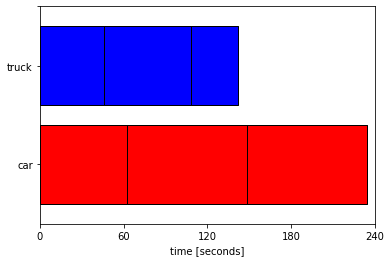

In [343]:
# Create a Gantt chart using the default settings:
vrv.createGantt(assignments = myAssignments, 
                xAxisLabel  = 'time [seconds]')

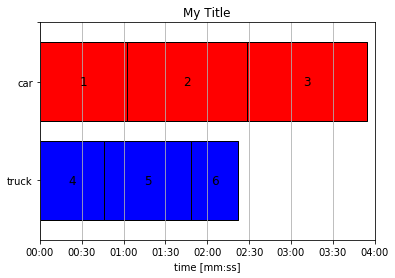

In [344]:
# Create (and save) a Gantt chart using all of the available settings:
vrv.createGantt(assignments         = myAssignments, 
                objectIDorder       = ['truck', 'car'], 
                separateByModelFile = False,
                mergeByodID         = True,
                splitOnColorChange  = True,
                title               = 'My Title',
                xAxisLabel          = 'time [mm:ss]',
                xGrid               = True,
                yGrid               = False,
                xMin                = 0,
                xMax                = None,
                xGridFreq           = 30,
                timeFormat          = 'MS',
                overlayColumn       = 'odID',
                missingColor        = 'lightgray',
                filename            = 'myGantt.png')